# Do BTCUSDT Microstructure Features Predict Returns and Volatility?

**First exploratory study of the `btcusdt_v2` dataset** · Binance USDⓈ-M BTCUSDT perpetual · July 2025 to October 2026

## Summary

**Question.** Do these features contain useful out-of-sample information about future price moves or volatility, and do market-microstructure features improve on a simple price-and-volume baseline?

**Short answer.**

1. **Volatility is very predictable, but microstructure does not improve on a strong baseline.** A nonlinear model using only price, volume, and calendar features beats every linear model, including one with all the microstructure features. Adding microstructure to that nonlinear model gains nothing.
2. **Direction has one real, small, and fast signal.** Top-of-book queue imbalance predicts a move of about 0.67 bps per unit of imbalance. It held in every test month and across volatility levels, and it confirmed a prediction written down before the holdout. Nothing useful exists at 15 minutes or 1 hour beyond that same effect.
3. **None of this is tradable as tested.** The signal is several times smaller than trading costs, and with a one-minute delay it is gone. None of the 24 rule variants passed.

| Question | Measure | Development | Holdout (untouched) | Verdict |
|---|---|---|---|---|
| Volatility, microstructure vs **linear** baseline | QLIKE gain, 15m / 1h | +1.5% / +1.3% | +2.3% / +1.5% (Holm p 0.18 / 1.00) | Not supported |
| Volatility, microstructure vs **nonlinear** baseline | QLIKE gain, 15m / 1h | −0.2% / −1.4% | −0.1% / −1.2% | Not supported |
| Direction, 2 minutes | R² on volatility-scaled returns, Ridge / LightGBM | 0.36% / 0.53% | 0.52% / 0.69% | **Supported** |
| Direction, 15 minutes | R², LightGBM | −0.03% | +0.06% | Passes the frozen rule, but tiny and largely the same 2-minute effect |
| Direction, 1 hour | R², Ridge / LightGBM | −0.01% / −0.02% | +0.01% / −0.11% | Not supported |
| Imbalance slope, no model involved | bps per unit of `qi_1` | 0.70 | 0.67, 95% CI [0.61, 0.72] | **Prediction confirmed** |
| Trading | Rule variants clearing costs | None | 0 of 24 | Not supported |

**How to read this notebook.** Sections 2–3 establish what the data is and where it can be trusted. Section 4 sets out the design. Sections 5–13 are **`EXPLORATORY`**: they use development data, and their results shaped decisions. Section 14 freezes the specification. Section 15 is **`CONFIRMATORY`** evidence on five untouched months, followed by clearly labelled **`POST-HOC`** diagnostics. Section 16 gives the final assessment.

## 1. Setup and reproducibility

**Environment.** Run this notebook with the `disertatie` conda environment, which is also the project interpreter (Python 3.11, with pandas, pyarrow, LightGBM, and statsmodels). The `chdds` package is imported from source only to reuse `incident_rows` and the feature registry.

**Reproducibility.** Seeds are fixed, LightGBM runs in deterministic mode, and every number below is computed from the parquet files. The notebook only reads the dataset and writes nothing next to it. The last code cell confirms the source files are unchanged.

**Runtime and memory.** A full run takes about 35 minutes on 4 threads and peaks near 10 GB of RAM. Only the columns needed are read, and the last cell reports the measured values.

In [1]:
import json, sys, time, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import lightgbm as lgb
import scipy
import statsmodels
from statsmodels.stats.multitest import multipletests

T0 = time.time()
SEED = 20261106
THREADS = 4                     # project guidance: keep parallelism modest on this 30 GB machine
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=RuntimeWarning)  # all-NaN slices during masked statistics

# ---- locate the repository from wherever the notebook was launched
def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the QuantForge repository.")

ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"

# Reuse project code rather than re-implementing its definitions.
sys.path.insert(0, str(CHDDS))
from chdds.dataset import META_COLS, QUALITY_COLS, incident_rows
from chdds.registry import match as registry_match

man = json.loads((DATA / "manifest.json").read_text())

# Fingerprint of the source files, re-checked in the last cell to prove nothing was modified.
def dataset_fingerprint():
    files = sorted(DATA.rglob("*.parquet")) + [DATA / "manifest.json"]
    return len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files)
FINGERPRINT_START = dataset_fingerprint()

# ---- chart style: one validated categorical order, recessive grid, no dual axes
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])   # red < 0 < blue
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "font.family": "sans-serif",
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "lines.linewidth": 1.8, "legend.frameon": False, "legend.fontsize": 9,
})
pd.set_option("display.width", 200, "display.max_columns", 60, "display.max_rows", 200, "display.max_colwidth", 80)

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | pyarrow {pa.__version__} "
      f"| lightgbm {lgb.__version__} | statsmodels {statsmodels.__version__} | scipy {scipy.__version__}")
print(f"Dataset: {DATA}\nCreated {man['created_utc']} | config hash {man['config_hash']} | book mode {man['book_provenance']['book_mode']}")

Python 3.11.13 | pandas 2.3.3 | numpy 2.0.2 | pyarrow 24.0.0 | lightgbm 4.6.0 | statsmodels 0.14.5 | scipy 1.16.2
Dataset: /home/octa/Desktop/QuantForge/data/cryptohftdata/derived/datasets/btcusdt_v2
Created 2026-11-05T20:01:10Z | config hash bf0f4edc96 | book mode rebuilt


## 2. What the data represents

`btcusdt_v2` is built from the raw CryptoHFTData feed for the **Binance USDⓈ-M BTCUSDT perpetual** (trades, L2 order book, mark price and index, funding, open interest, liquidations, ticker). Each row is one bar, and each row carries features describing what was known at that bar's **decision time**.

Three properties from the implementation shape everything that follows:

* **Clock.** Everything runs on the *availability* clock, meaning the time the collector received each message. A row at decision time `T` uses only information received by `eval_time = T − 1 ns`.
* **No targets.** The dataset deliberately contains no labels. I build all targets in this notebook.
* **Validity is explicit.** Windows are *strict*: a window that touches a trade gap is null rather than approximated. So a null means "not measured reliably". It never means zero, and nulls must not be filled with zeros.

First I establish what actually exists, from the files, and check it against the manifest and `docs/DATASET_V2.md`.

In [2]:
# Inventory read directly from the parquet files, compared with the manifest.
rows = []
for spec_id, v in man["bar_sets"].items():
    files = sorted((DATA / spec_id).glob("*.parquet"))
    n = sum(pq.read_metadata(f).num_rows for f in files)
    t_first = pq.read_table(files[0], columns=["decision_time_ns"]).column(0)[0].as_py()
    t_last = pq.read_table(files[-1], columns=["decision_time_ns"]).column(0)[-1].as_py()
    dur = np.concatenate([pq.read_table(f, columns=["bar_duration_s"]).column(0).to_numpy() for f in files])
    s = v["spec"]["spec"]
    rule = (f"adaptive {s['adaptive']}" if s["adaptive"] else f"fixed {s['threshold']}")
    rows.append(dict(bar_set=v["name"], kind=s["kind"], rule=rule, rows=n, matches_manifest=(n == v["rows"]), files=len(files),
                     first_bar=pd.to_datetime(t_first, utc=True).strftime("%Y-%m-%d %H:%M"),
                     last_bar=pd.to_datetime(t_last, utc=True).strftime("%Y-%m-%d %H:%M"),
                     median_bar_s=round(float(np.nanmedian(dur)), 1), p99_bar_s=round(float(np.nanpercentile(dur, 99)), 0),
                     columns=v["n_columns"], model_columns=len(v["model_feature_columns"])))
inventory = pd.DataFrame(rows).set_index("bar_set")
print(f"Total bars: {inventory['rows'].sum():,} across {len(inventory)} bar sets. "
      f"All match the manifest: {inventory['matches_manifest'].all()}")
inventory

Total bars: 9,413,305 across 9 bar sets. All match the manifest: True


,kind,rule,rows,matches_manifest,files,first_bar,last_bar,median_bar_s,p99_bar_s,columns,model_columns
bar_set,,,,,,,,,,,
time_1m,time,fixed 60,707040,True,17,2025-06-28 00:01,2026-11-01 00:00,60.0,60.0,664,643
time_5m,time,fixed 300,141408,True,17,2025-06-28 00:05,2026-11-01 00:00,300.0,300.0,664,643
volume_50btc,volume,fixed 50,1435551,True,17,2025-06-28 05:00,2026-10-31 23:54,14.5,196.0,666,645
volume_adapt60s,volume,"adaptive {'target_s': 60, 'lookback_days': 7}",1390444,True,16,2025-07-05 00:00,2026-10-31 23:56,14.9,196.0,666,645
dollar_5musdt,dollar,fixed 5000000,1220171,True,17,2025-06-28 05:00,2026-10-31 23:54,17.5,229.0,666,645
dollar_adapt60s,dollar,"adaptive {'target_s': 60, 'lookback_days': 7}",1386082,True,16,2025-07-05 00:00,2026-10-31 23:58,15.0,197.0,666,645
cusum_5bps,cusum,fixed 5,1503182,True,17,2025-06-28 05:03,2026-10-31 23:52,6.5,307.0,670,649
cusum_10bps,cusum,fixed 10,462400,True,17,2025-06-28 05:03,2026-10-31 23:13,25.2,945.0,670,649
cusum_adapt_c1,cusum,"adaptive {'c': 1.0, 'lookback_days': 7}",1167027,True,16,2025-07-05 00:01,2026-10-31 23:52,9.7,357.0,670,649


**Reading the table.** The manifest, the files, and `docs/DATASET_V2.md` agree on 9 bar sets and 9,413,305 bars. Two details are worth noting:

* The adaptive sets start on 2025-07-05, because their thresholds need 7 prior days.
* Event bars close on activity, not on the clock, so their duration is very uneven. Dollar and volume bars have a median near 15 s, but the 99th percentile is around 200 s. The `adapt60s` name refers to how the threshold is set, not to a typical bar length.

The next table groups the 643 model columns of `time_1m` by family, using the project's own feature registry.

In [3]:
# Feature families, taken from the project's registry rather than from column-name guesses.
FAMILY_NAMES = {"F1": "Price and trajectory", "F1/bar": "Bar (OHLCV, bar flow)", "F1/F7": "Trades vs index", "F2": "Volatility",
                "F3": "Activity and trade flow", "F4": "Book state", "F5": "Book windows and OFI", "F6": "Execution quality",
                "F6/F11": "Book and flow combinations", "F7": "Mark, basis, funding", "F7/F12": "Funding combinations",
                "F8": "Open interest", "F9": "Liquidations", "F10": "Ticker and calendar"}
spec_1m = next(k for k, v in man["bar_sets"].items() if v["name"] == "time_1m")
model_cols = man["bar_sets"][spec_1m]["model_feature_columns"]
fam = pd.Series({c: registry_match(c)[0].family for c in model_cols}, name="family")
family_table = (fam.value_counts().rename("columns").to_frame()
                .assign(family_name=lambda d: d.index.map(FAMILY_NAMES),
                        examples=lambda d: [", ".join(fam[fam == f].index[:3]) for f in d.index]))
print(f"{len(model_cols)} model columns. Excluded by the project as identity or quality metadata: "
      f"{len(META_COLS)} + {len(QUALITY_COLS)} ({', '.join(QUALITY_COLS)}).")
family_table[["family_name", "columns", "examples"]]

643 model columns. Excluded by the project as identity or quality metadata: 18 + 3 (book_state, cert_bid_floor_dist_bps, cert_ask_ceiling_dist_bps).


,family_name,columns,examples
family,,,
F4,Book state,114,"book_recv_age_ms, book_mkt_age_ms, best_bid"
F3,Activity and trade flow,103,"tw_state_5s, tw_state_30s, tw_state_2m"
F7,"Mark, basis, funding",65,"mark_state, mark_recv_age_ms, mark_mkt_age_ms"
F2,Volatility,64,"rv_trade_5s_grid100ms, rv_neg_trade_5s_grid100ms, rv_pos_trade_5s_grid100ms"
F5,Book windows and OFI,55,"ofi_1s_btc, ofi_rate_1s_btc_s, ofi_norm_1s"
F9,Liquidations,49,"liq_state_30s, liq_notional_short_30s_usdt, liq_notional_long_30s_usdt"
F6/F11,Book and flow combinations,49,"pressure_buy_5bps_5s, pressure_sell_5bps_5s, pressure_net_5bps_5s"
F1,Price and trajectory,42,"last_trade_price, last_trade_age_ms, vwap_5s"
F6,Execution quality,33,"cost_buy_0p1btc_bps, cost_sell_0p1btc_bps, cost_buy_1btc_bps"


### Loading a focused panel

I work mainly with **`time_1m`**, reading only the source columns needed. Three reasons:

1. It gives exact clock horizons, so "the next 15 minutes" means the same thing on every row.
2. It has the best coverage during stress. On 9–11 October 2025 the project's own coverage files show book features on 96% of `time_1m` bars, against about 79% for dollar bars and about 25% for CUSUM bars. CUSUM and event bars fire most when the market moves fastest, which is also when the book is most often stale, so they lose exactly the rows that matter.
3. It keeps the first analysis tractable. `dollar_adapt60s` is used later as a robustness check on the sampling clock.

`time_5m` adds little over `time_1m` because the horizons below are clock-based. CUSUM bars are left out of this notebook because of the coverage problem above.

In [4]:
RAW_COLS = '''decision_time_ns eval_time_ns t_start_ns seg feed_complete book_state bar_close bar_range_log bar_close_location bar_notional_usdt bar_n_trades
last_trade_age_ms mid ret_trade_30s ret_trade_2m ret_trade_15m ret_trade_1h ret_trade_4h ret_trade_24h
rv_trade_2m_grid1s rv_trade_15m_grid1s rv_trade_1h_grid1s rv_trade_4h_grid1m rv_trade_24h_grid1m
close_location_15m drawdown_from_high_15m rebound_from_low_15m notional_2m_usdt notional_15m_usdt trade_count_15m notional_15m_vs_slot_median_28d
hour_of_day_sin hour_of_day_cos day_of_week_sin day_of_week_cos is_weekend
tfi_ratio_5s tfi_ratio_30s tfi_ratio_2m tfi_ratio_15m count_imbalance_30s count_imbalance_2m signed_large_flow_2m_usdt signed_large_flow_15m_usdt
vwap_distance_30s_bps vwap_distance_2m_bps vwap_distance_15m_bps large_trade_share_2m mean_trade_size_2m_btc size_concentration_2m sign_acf_lag1_n1000 run_sign run_volume_btc burstiness_fano_2m_cell1s
qi_1 qi_top5 qi_1bps qi_5bps qi_10bps qi_25bps weighted_mid_offset_bps tw_qi_1_30s tw_qi_1_2m spread_bps
depth_bid_1bps_btc depth_ask_1bps_btc depth_bid_5bps_btc depth_ask_5bps_btc depth_bid_10bps_btc depth_ask_10bps_btc depth_bid_25bps_btc depth_ask_25bps_btc depth_bid_50bps_btc
cost_buy_1btc_bps cost_sell_1btc_bps cost_buy_5btc_bps cost_sell_5btc_bps cost_buy_1000000usdt_atmid_bps cost_sell_1000000usdt_atmid_bps conc_bid_10bps conc_ask_10bps tw_spread_bps_2m max_spread_bps_2m min_depth1_2m_btc
ofi_norm_5s ofi_norm_30s ofi_norm_2m mlofi_norm_l2_30s mlofi_norm_l3_30s mlofi_norm_l4_30s mlofi_norm_l5_30s pressure_net_5bps_30s pressure_net_5bps_2m tfi_over_tw_depth1_30s tfi_over_tw_depth1_2m
add_bid_10bps_2m_btc rem_bid_10bps_2m_btc add_ask_10bps_2m_btc rem_ask_10bps_2m_btc book_level_changes_2m book_msg_count_2m eff_spread_qw_bps_2m markout_5s_qw_bps_2m markout_30s_qw_bps_2m
basis_mark_index_bps basis_mark_index_change_2m_bps basis_mark_index_change_15m_bps basis_mark_index_change_1h_bps ret_trade_minus_index_2m ret_trade_minus_index_15m
funding_rate_asof funding_rz_7d funding_phase_sin funding_phase_cos oi_log_change_known_15m oi_log_change_known_1h oi_log_change_known_4h oi_level_rz_7d oi_change_rz_7d turnover_to_oi_15m
tw_basis_mark_index_bps_15m tw_basis_mark_index_bps_1h
log1p_liq_notional_2m log1p_liq_notional_15m log1p_liq_notional_1h liq_signed_notional_2m_usdt liq_signed_notional_15m_usdt liq_signed_notional_1h_usdt liq_imbalance_15m liq_to_oi_15m time_since_buy_short_liq_s time_since_sell_long_liq_s'''.split()

def load_bars(name, columns=RAW_COLS):
    # Column projection keeps memory small. Read-only access to the monthly parquet files.
    spec_id = next(k for k, v in man["bar_sets"].items() if v["name"] == name)
    parts = [pq.read_table(f, columns=columns).to_pandas() for f in sorted((DATA / spec_id).glob("*.parquet"))]
    b = pd.concat(parts, ignore_index=True)
    b.index = pd.DatetimeIndex(pd.to_datetime(b["decision_time_ns"], utc=True), name="t")
    return b

bars = load_bars("time_1m")
month = bars.index.strftime("%Y-%m")
step = np.diff(bars["decision_time_ns"].to_numpy())
print(f"time_1m: {bars.shape[0]:,} rows x {bars.shape[1]} columns, {bars.memory_usage(deep=True).sum()/1e9:.2f} GB")
print(f"Regular one-minute grid: {bool((step == 60_000_000_000).all())}. Duplicate timestamps: {int(bars.index.duplicated().sum())}.")
print(f"decision_time - eval_time is always 1 ns: {bool(((bars.decision_time_ns - bars.eval_time_ns) == 1).all())}")
print(f"Bars touching a trade-feed gap (feed_complete = 0): {(bars.feed_complete == 0).sum():,} ({(bars.feed_complete == 0).mean():.2%})")

time_1m: 707,040 rows x 132 columns, 0.74 GB
Regular one-minute grid: True. Duplicate timestamps: 0.
decision_time - eval_time is always 1 ns: True
Bars touching a trade-feed gap (feed_complete = 0): 2,848 (0.40%)


The grid is perfectly regular, so a shift of `k` rows is exactly `k` minutes. That lets me build forward targets by shifting, which I verify below.

## 3. Data quality and limitations

Before asking whether features predict anything, I need to know where they can be trusted. The checks in this section use **features only**, never targets, so they can look at the whole history without weakening the later holdout.

### 3.1 Book provenance is not constant over time

`book_state` records how each top-of-book value was obtained:

| State | Meaning |
|---|---|
| 0 | Anchored: a snapshot plus continuous updates |
| 9 | Rebuilt without a snapshot, with the top of book proven exact by a protocol certificate |
| 1 | No book available |
| 2 | Stale: more than 1 s of market age |
| 10 | Rebuilt but not certified, features null |

From July 2025 to April 2026 the vendor has **zero** snapshots, so almost all book values in that span rest on the certificate. The docs are explicit that this exactness is *inferred from the protocol, not directly measured* for those 9.3 months.

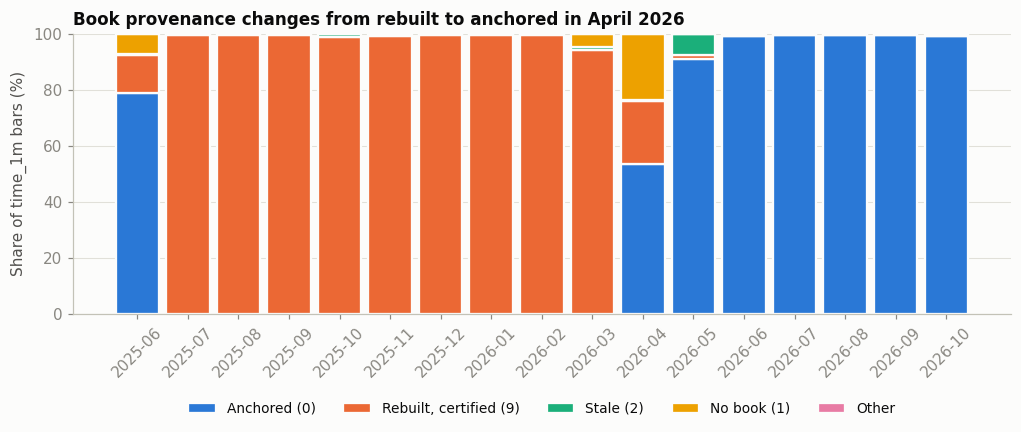

row_0,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
book_state,,,,,,,,,,,,,,,,,
Anchored (0),79.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,53.7,91.2,99.2,99.7,99.8,99.8,99.5
"Rebuilt, certified (9)",13.7,99.7,99.7,99.6,99.1,99.3,99.7,99.6,99.7,94.2,22.3,1.2,0.0,0.0,0.0,0.0,0.0
Stale (2),0.4,0.3,0.3,0.4,0.9,0.7,0.3,0.4,0.3,1.3,0.4,7.6,0.8,0.3,0.2,0.2,0.5
No book (1),6.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.4,23.6,0.0,0.0,0.0,0.0,0.0,0.0
Other,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
STATE_GROUPS = {0: "Anchored (0)", 9: "Rebuilt, certified (9)", 2: "Stale (2)", 1: "No book (1)"}
grp = bars["book_state"].map(STATE_GROUPS).fillna("Other")
prov = pd.crosstab(month, grp, normalize="index").mul(100)
prov = prov.loc[prov.index != "2026-11", [c for c in list(STATE_GROUPS.values()) + ["Other"] if c in prov.columns]]

fig, ax = plt.subplots(figsize=(11, 3.3))
bottom = np.zeros(len(prov))
for col, color in zip(prov.columns, [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"]]):
    ax.bar(prov.index, prov[col], bottom=bottom, color=color, width=0.86, edgecolor=SURFACE, linewidth=1.5, label=col)
    bottom += prov[col].to_numpy()
ax.set(title="Book provenance changes from rebuilt to anchored in April 2026", ylabel="Share of time_1m bars (%)", ylim=(0, 100))
ax.tick_params(axis="x", rotation=45); ax.grid(axis="x", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.27))
plt.show()
prov.round(1).T

**How to read this.** Blue is the part of the data with a direct reference, orange is the part resting on the certificate. Provenance flips in April 2026, which is close to where any final test period would begin. So a model trained on the past and tested on the recent period is also crossing a *data-construction* boundary, and I test below whether that boundary changes the features.

The chart also shows a hole in early April 2026, which the next section looks at.

### 3.2 Feed cadence changes twice, and one column family just measures that

Reading `book_msg_count_2m` by month shows it is close to constant within long periods and then jumps. That is not market activity. It is the exchange or collector update cadence changing (the D1 report lists regimes of about 102 ms, 52 ms, and 26–28 ms). Any feature that counts messages is therefore a disguised calendar variable.

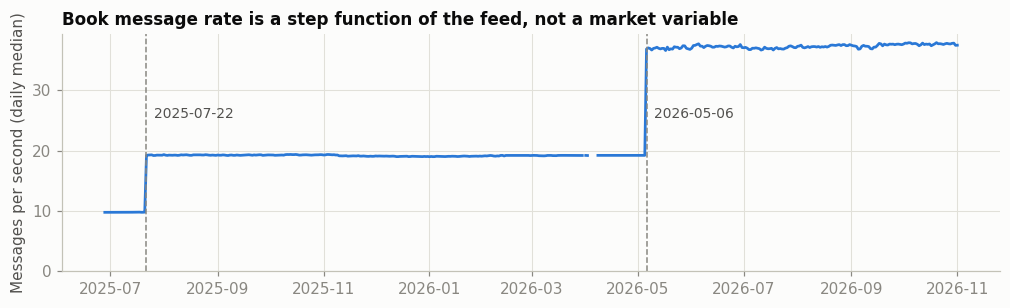

,median_before,median_after,iqr_before,iqr_after,iqr_ratio
book_msg_count_2m,2308.000,4446.000,1.000,60.000,60.000
book_level_changes_2m,129507.000,159530.500,72433.500,79505.500,1.098
ofi_norm_5s,-0.013,-0.003,4.088,3.356,0.821
ofi_norm_30s,-0.171,-0.063,21.224,20.378,0.960
ofi_norm_2m,-0.870,-0.679,49.984,49.544,0.991
mlofi_norm_l3_30s,0.000,-0.000,172.921,249.936,1.445
qi_1,-0.040,0.004,1.076,1.079,1.003
add_bid_10bps_2m_btc,4279.053,7522.010,4144.595,6530.444,1.576


In [6]:
daily_rate = bars["book_msg_count_2m"].resample("1D").median() / 120.0   # messages per second
CADENCE_BREAKS = [pd.Timestamp("2025-07-22", tz="UTC"), pd.Timestamp("2026-05-06", tz="UTC")]

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot(daily_rate.index, daily_rate, color=C["blue"])
for b_ in CADENCE_BREAKS:
    ax.axvline(b_, color=MUTED, lw=1, ls="--")
    ax.annotate(b_.strftime("%Y-%m-%d"), (b_, daily_rate.max() * 0.72), xytext=(5, 0), textcoords="offset points", color=INK2, fontsize=9, va="top")
ax.set(title="Book message rate is a step function of the feed, not a market variable", ylabel="Messages per second (daily median)", ylim=(0, None))
plt.show()

# Does the last cadence change also move features that I do want to use?
b0 = CADENCE_BREAKS[1]
before, after = bars.loc[b0 - pd.Timedelta(days=30):b0], bars.loc[b0:b0 + pd.Timedelta(days=30)]
iqr = lambda s: s.quantile(.75) - s.quantile(.25)
checks = ["book_msg_count_2m", "book_level_changes_2m", "ofi_norm_5s", "ofi_norm_30s", "ofi_norm_2m", "mlofi_norm_l3_30s", "qi_1", "add_bid_10bps_2m_btc"]
pd.DataFrame({"median_before": before[checks].median(), "median_after": after[checks].median(),
              "iqr_before": before[checks].apply(iqr), "iqr_after": after[checks].apply(iqr)}
             ).assign(iqr_ratio=lambda d: d.iqr_after / d.iqr_before).round(3)

**Conclusion.** The message count nearly doubles at the break, while its interquartile range before the break was a single message, so it carries almost no market information and is excluded from all models. For the features I do want:

* **Level-1 OFI and queue imbalance keep their scale** (IQR ratios of 0.8 to 1.0), so they stay in.
* **Deeper MLOFI and raw add volumes rise by about 1.5×.** That could be market conditions or a finer feed capturing more transient orders, and this comparison cannot separate the two. I therefore use adds and removes only as a ratio, where a common scale cancels. Deeper MLOFI stays in as a known risk, and the May 2026 fold and the holdout both test it directly.

### 3.3 Coverage by month

The chart shows the share of **missing** values for one representative column per family, across the full history.

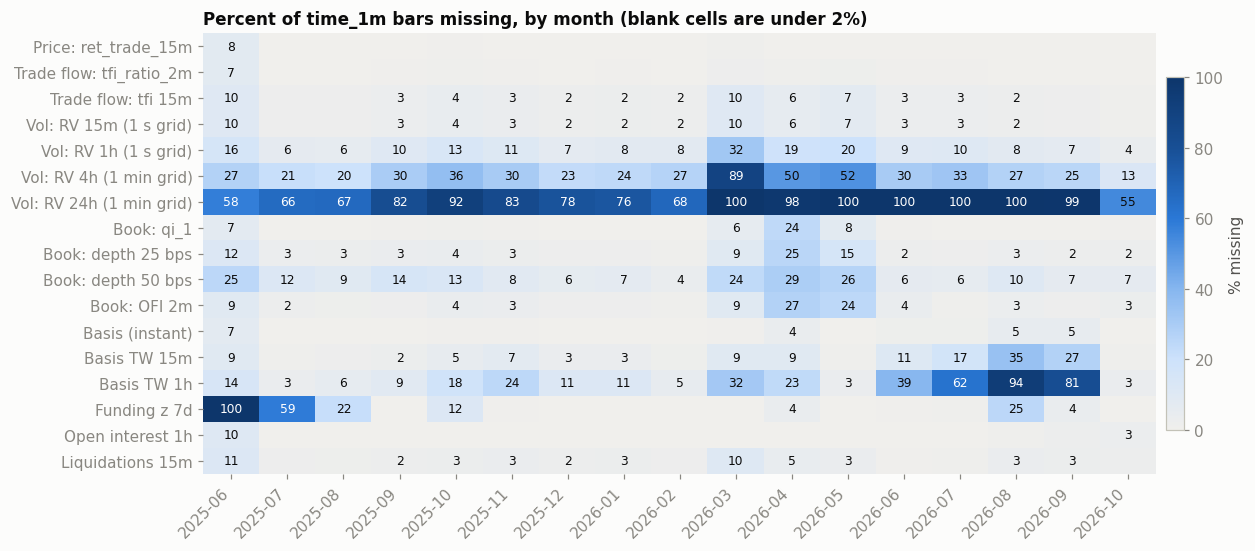

In [7]:
rep = {"Price: ret_trade_15m": "ret_trade_15m", "Trade flow: tfi_ratio_2m": "tfi_ratio_2m", "Trade flow: tfi 15m": "tfi_ratio_15m",
       "Vol: RV 15m (1 s grid)": "rv_trade_15m_grid1s", "Vol: RV 1h (1 s grid)": "rv_trade_1h_grid1s", "Vol: RV 4h (1 min grid)": "rv_trade_4h_grid1m",
       "Vol: RV 24h (1 min grid)": "rv_trade_24h_grid1m", "Book: qi_1": "qi_1", "Book: depth 25 bps": "depth_bid_25bps_btc", "Book: depth 50 bps": "depth_bid_50bps_btc",
       "Book: OFI 2m": "ofi_norm_2m", "Basis (instant)": "basis_mark_index_bps", "Basis TW 15m": "tw_basis_mark_index_bps_15m", "Basis TW 1h": "tw_basis_mark_index_bps_1h",
       "Funding z 7d": "funding_rz_7d", "Open interest 1h": "oi_log_change_known_1h", "Liquidations 15m": "log1p_liq_notional_15m"}
miss = pd.DataFrame({k: bars[v].isna().groupby(month).mean() for k, v in rep.items()}).T.mul(100)
miss = miss.drop(columns=["2026-11"])

fig, ax = plt.subplots(figsize=(11.5, 5.2))
im = ax.imshow(miss.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(miss.shape[1]), miss.columns, rotation=45, ha="right"); ax.set_yticks(range(miss.shape[0]), miss.index)
for i in range(miss.shape[0]):
    for j in range(miss.shape[1]):
        v = miss.values[i, j]
        if v >= 2:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else INK)
ax.grid(False); ax.set_title("Percent of time_1m bars missing, by month (blank cells are under 2%)")
for s in ax.spines.values(): s.set_visible(False)
plt.colorbar(im, ax=ax, fraction=0.018, pad=0.01, label="% missing")
plt.show()

**Reading the heatmap, and what it means for feature choice.**

* **Long strict windows are unusable.** `rv_trade_24h` is missing about 85% of the time and the 4h version about a third. This follows from the project's strict-window policy and the 2,846 trade-ID gaps: one gap anywhere inside a 24h window voids it. A daily volatility term is essential for a good baseline, so I rebuild long-memory volatility from 1-minute bars with a tolerance for partial windows (section 4).
* **Time-weighted basis windows degrade in late 2026.** The 1h window is missing over 90% of the time in August 2026, so its availability differs strongly between past and future. Those columns are excluded. Instantaneous basis stays usable.
* **`funding_rz_7d`** is mostly missing in July 2025 and again partly in August 2026, so I use the raw funding rate.
* **The April 2026 hole is broad.** Book columns are missing on most of 2026-03-30 to 2026-04-09.

Every exclusion above is based on availability, not on predictive performance.

### 3.4 Episodes where book data is degraded

In [8]:
book_ok = bars["mid"].notna().resample("1D").mean()
bad = book_ok[book_ok < 0.9]
runs = (bad.index.to_series().diff() != pd.Timedelta(days=1)).cumsum()
episodes = pd.DataFrame([dict(start=g.index[0].date(), end=g.index[-1].date(), days=len(g), min_daily_book_coverage=round(float(g.min()), 3),
                              mean_daily_book_coverage=round(float(g.mean()), 3),
                              dominant_state=STATE_GROUPS.get(bars.loc[str(g.index[0].date()):str(g.index[-1].date()), "book_state"].where(lambda s: ~s.isin([0, 9])).mode().iloc[0], "Other"))
                         for _, g in bad.groupby(runs)])
episodes

,start,end,days,min_daily_book_coverage,mean_daily_book_coverage,dominant_state
0,2025-06-28,2025-06-28,1,0.792,0.792,No book (1)
1,2025-10-10,2025-10-10,1,0.886,0.886,Stale (2)
2,2026-03-30,2026-04-09,11,0.000,0.223,No book (1)
3,2026-05-24,2026-05-28,5,0.394,0.619,Stale (2)
4,2026-06-01,2026-06-01,1,0.874,0.874,Stale (2)


The two long episodes match the audit documentation: raw order-book hours are missing from 2026-03-30 to 2026-04-09, and 24–27 May 2026 is a reconnection storm. They are data holes, not market events, and a model comparison must not treat them as signal. The first row is the very start of the data, and 2026-06-01 is a brief period of staleness. The 10 October 2025 row is the crash, examined next.

### 3.5 Anatomy of the October 2025 crash

The dataset documentation treats 9–11 October 2025 as a distinct episode. Before deciding how to handle it, I want to see exactly what was recorded during its worst hours.

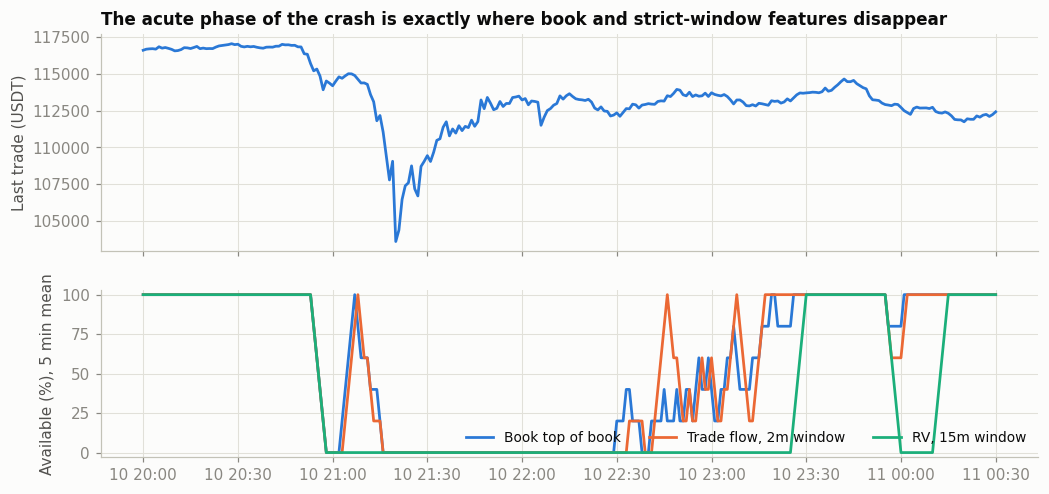

,low,high,trades,feed_ok_%,book_%,tfi_2m_%,rv_15m_%
t,,,,,,,
2025-10-10 20:00:00+00:00,116562.6,116842.4,60443,100.0,100.0,100.0,100.0
2025-10-10 20:15:00+00:00,116711.2,117050.0,43541,100.0,100.0,100.0,100.0
2025-10-10 20:30:00+00:00,116743.3,117014.0,31088,100.0,100.0,100.0,100.0
2025-10-10 20:45:00+00:00,113915.7,116975.9,316143,60.0,60.0,60.0,60.0
2025-10-10 21:00:00+00:00,111804.2,115006.9,297119,53.0,47.0,40.0,0.0
2025-10-10 21:15:00+00:00,103589.3,112164.8,374639,0.0,0.0,0.0,0.0
2025-10-10 21:30:00+00:00,109034.2,111847.4,321701,0.0,0.0,0.0,0.0
2025-10-10 21:45:00+00:00,111429.8,113482.4,260155,0.0,0.0,0.0,0.0
2025-10-10 22:00:00+00:00,111497.9,113506.0,239127,0.0,0.0,0.0,0.0


In [9]:
w = bars.loc["2025-10-10 20:00":"2025-10-11 00:30"]
g = w.groupby(pd.Grouper(freq="15min"))
crash_table = pd.DataFrame({
    "low": g["bar_close"].min(), "high": g["bar_close"].max(), "trades": g["bar_n_trades"].sum().astype(int),
    "feed_ok_%": g["feed_complete"].mean().mul(100).round(0),
    "book_%": g["mid"].apply(lambda s: s.notna().mean() * 100).round(0),
    "tfi_2m_%": g["tfi_ratio_2m"].apply(lambda s: s.notna().mean() * 100).round(0),
    "rv_15m_%": g["rv_trade_15m_grid1s"].apply(lambda s: s.notna().mean() * 100).round(0)})

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, height_ratios=[1.3, 1])
axes[0].plot(w.index, w["bar_close"], color=C["blue"])
axes[0].set(title="The acute phase of the crash is exactly where book and strict-window features disappear", ylabel="Last trade (USDT)")
for col, lab, color in [("mid", "Book top of book", C["blue"]), ("tfi_ratio_2m", "Trade flow, 2m window", C["orange"]), ("rv_trade_15m_grid1s", "RV, 15m window", C["aqua"])]:
    axes[1].plot(w.index, w[col].notna().rolling(5, min_periods=1).mean() * 100, label=lab, color=color)
axes[1].set(ylabel="Available (%), 5 min mean", ylim=(-3, 103)); axes[1].legend(ncol=3, loc="lower right")
plt.show()
crash_table

**What this shows.**

* **Price:** BTC fell from about 117,000 to a 1-minute close near 103,600 in under an hour, then recovered to about 111,800 within roughly 15 minutes.
* **Book:** the book is stale for essentially all of about 21:15–22:30 UTC.
* **Strict windows:** the 15-minute RV is null for more than two hours, and the 2-minute trade-flow window for most of it. Trade IDs were being dropped, so these windows refuse to report.

This has two direct consequences for the research:

1. **Whether microstructure features help during the acute crash cannot be answered with this data**, because the features do not exist there. Any "crash performance" number mostly describes the hours around it.
2. **The primary volatility target is also blind there.** The worst hours would silently disappear from the evaluation. Section 11 uses a secondary target built from 1-minute closes to keep them visible.

There is also a trap for anyone summing `bar_return_log`. It is null across segment breaks, so summing it understates the crash day. Prices at both ends still exist, and that is why I build returns from `ret_trade_*` and fresh closes.

### 3.6 Does provenance change the meaning of book features?

Mid-April 2026 offers a natural experiment. Both provenance states alternate within the same days, so market conditions are almost identical while the data construction differs. If the certificate-based reconstruction were distorted, features would differ between the two groups here.

In [10]:
win = bars.loc["2026-04-10":"2026-04-17"]
A_, R_ = win[win.book_state == 0], win[win.book_state == 9]
feat = ["spread_bps", "qi_1", "qi_5bps", "qi_25bps", "depth_bid_5bps_btc", "depth_bid_10bps_btc", "depth_bid_25bps_btc", "depth_bid_50bps_btc",
        "cost_buy_1000000usdt_atmid_bps", "ofi_norm_30s", "ofi_norm_2m", "book_level_changes_2m", "markout_30s_qw_bps_2m"]
comparison = pd.DataFrame({"median_rebuilt": R_[feat].median(), "median_anchored": A_[feat].median(),
                           "iqr_rebuilt": R_[feat].apply(iqr), "iqr_anchored": A_[feat].apply(iqr),
                           "coverage_rebuilt": R_[feat].notna().mean(), "coverage_anchored": A_[feat].notna().mean()})
print(f"Same-week sample: {len(R_):,} rebuilt bars vs {len(A_):,} anchored bars")
comparison.round(3)

Same-week sample: 4,277 rebuilt bars vs 7,210 anchored bars


,median_rebuilt,median_anchored,iqr_rebuilt,iqr_anchored,coverage_rebuilt,coverage_anchored
spread_bps,0.014,0.013,0.000,0.001,1.000,1.000
qi_1,-0.052,-0.042,1.010,1.048,1.000,1.000
qi_5bps,-0.017,0.011,0.322,0.318,1.000,1.000
qi_25bps,-0.021,0.001,0.176,0.160,0.985,0.974
depth_bid_5bps_btc,60.038,61.484,22.192,24.670,1.000,1.000
depth_bid_10bps_btc,173.542,167.314,47.946,58.185,0.999,0.997
depth_bid_25bps_btc,617.783,629.138,110.615,150.983,0.987,0.981
depth_bid_50bps_btc,1320.505,1311.976,251.398,276.436,0.936,0.902
cost_buy_1000000usdt_atmid_bps,0.655,0.672,0.780,0.829,1.000,1.000
ofi_norm_30s,-0.232,-0.205,20.896,24.885,0.998,0.998


**Interpretation.** Medians, spreads, and coverage are close across the two groups, which is reassuring but not proof: this is a single week, and neither group is randomly assigned. Rebuilt rows also show no coverage penalty here. Across the whole history, though, the 50 bps band is missing much more often than the 25 bps band (section 3.3), so I use bands up to 25 bps only.

### 3.7 Limitations that carry through the analysis

| Limitation | Evidence | How this notebook handles it |
|---|---|---|
| Book exactness Jul 2025–Apr 2026 is inferred, not measured | No snapshots in that span | Provenance reported as a separate market condition |
| Acute crash has no book or strict-window features | Section 3.5 | Reported separately; secondary target used |
| Strict long windows mostly missing | Section 3.3 | Rebuilt from 1-minute bars with tolerance |
| Book outages 2026-03-30 to 04-09 and 24–28 May 2026 | Section 3.4 | Dropped from comparisons by the eligibility rule |
| Feed cadence changes | Section 3.2 | Message counts excluded; dev data starts on a cadence boundary |
| Liquidations are notifications, capped at one per symbol per second | `docs/LIMITATIONS.md` | Treated as a lower-quality proxy for true liquidation volume |
| 75 hours without a liquidation file | `docs/LIMITATIONS.md` | Stay null, never zero |
| Open interest arrives every 5 minutes and can be delayed | Registry | Only "known at time t" versions used |
| Open interest quarantine on 2026-10-15 | `docs/LIMITATIONS.md` | Rejection can act retroactively (values withheld only), a negligible look-ahead in availability |
| Collector clock | `docs/LIMITATIONS.md` | Latency is not modelled; zero latency is optimistic and is examined in section 13 |
| One venue, one instrument | Dataset scope | Conclusions apply to Binance BTCUSDT perpetual only |
| Phantom level on 2025-08-29 (31 s) | `quality_incidents.json` | Rows excluded, using the project's `incident_rows` |

## 4. Research design

### 4.1 Objective and hypotheses

> **Do these features contain useful out-of-sample predictive information about future price movements or volatility, and do the additional market-microstructure features improve on a simple price-and-volume baseline?**

This splits into two separate questions, because volatility and direction behave very differently, plus a third about money:

* **H-VOL.** Microstructure features reduce forecast loss for future realized volatility beyond a strong price-and-volume baseline.
* **H-DIR.** Microstructure features improve forecasts of future returns beyond the same baseline.
* **H-ECON.** Any directional forecast improvement is large enough to survive realistic trading costs.

### 4.2 Evidence tiers

Every analysis is labelled with one of two tiers, and they should not be read the same way:

* **`EXPLORATORY`** uses the development period. I look at the results and may react to them, so any number here is optimistic in the sense that it informed choices.
* **`CONFIRMATORY`** uses the holdout, evaluated with a specification frozen in advance.

| Period | Dates | Role |
|---|---|---|
| Warm-up | 2025-06-28 to 2025-07-21 | Not used for fitting. Includes the older feed cadence and feature warm-up. |
| Development | 2025-07-22 to 2026-05-31 | All exploration, 8 monthly walk-forward test folds (Oct 2025 to May 2026) |
| Holdout | 2026-06-01 to 2026-10-31 | Five untouched months, evaluated once |

Development contains the crash, the book outages, and the provenance and cadence changes, so the specification is tested against all of those before the holdout. The holdout months are almost entirely anchored and have the cleanest book data in the history.

**What I have already seen of the holdout.** The data-quality checks in section 3 cover the full history, so before freezing anything I saw feature coverage for those months, and a ranking of daily volatility that showed high-volatility days in June and August 2026. None of those checks involves a relationship between a feature and a future target.

### 4.3 Validation

* **Walk-forward with an expanding window**, refit monthly. Each test month uses a model trained only on earlier data, like a live system.
* **Purging.** Forward targets overlap, so a row near the end of training can have a target that reaches into the test month. I remove the last 60 bars before every test month, which covers the longest horizon.
* **Train-only preprocessing.** Clipping bounds, scaling, medians, Ridge penalties, and LightGBM stopping points are all determined inside the training window, using a time-ordered inner validation slice.
* **The crash is out of both training and aggregate scores.** Rows from one hour before 2025-10-09 to the end of 2025-10-11 are removed from training and from headline metrics, then reported separately. Removing it from training is a choice, so section 9 tests the alternative.

### 4.4 Metrics and statistical tests

Rows are heavily autocorrelated and overlapping, so treating 300,000 minutes as independent would produce absurdly small p-values. **All inference runs on daily aggregates**: I average each loss difference by day and compute Newey–West (HAC) t-statistics across days.

| Question | Metric | Test |
|---|---|---|
| Volatility forecast error | Out-of-sample R² on log RV, QLIKE loss | Diebold–Mariano on daily mean loss difference |
| Direction | Daily information coefficient (IC), out-of-sample R² against a zero forecast | HAC t-test of mean daily IC |
| Nested comparison (baseline vs. extended) | Change in R² | Clark–West, which corrects for the noise a larger nested model adds |
| Multiple comparisons | | Holm correction across hypotheses |
| Uncertainty | Confidence intervals | 5-day moving-block bootstrap on days |
| Persistence | Monthly and per-condition results | Share of months with the same sign |

Direction is modelled on **volatility-scaled returns**, `z = r / (σ·√h)`, with σ a causal trailing volatility. Without scaling, a squared-error model is dominated by a few violent hours. That is one of the ways a single episode could otherwise take over the whole assessment.

### 4.5 Why these models

* **Ridge regression** is the primary model: transparent, fast enough to run every feature-block ablation, and hard to overfit with 100 features and hundreds of thousands of rows.
* **LightGBM** is the nonlinear check. It answers "is there interaction structure that Ridge cannot see?". Its hyperparameters are fixed and conservative and are **not tuned**. Tuning on a low-signal problem mostly fits noise and uses up the credibility of the test.

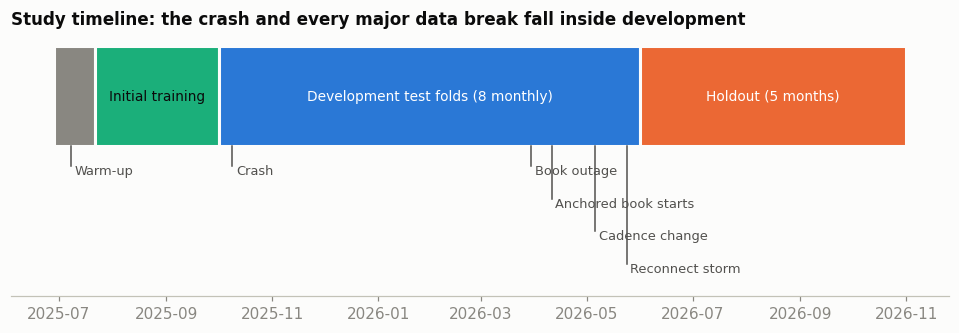

In [11]:
# ------------------------------------------------------------------ frozen study design
UTC = "UTC"
DEV_START     = pd.Timestamp("2025-07-22", tz=UTC)    # first day of the 52 ms cadence regime, after feature warm-up
HOLDOUT_START = pd.Timestamp("2026-06-01", tz=UTC)
DATA_END      = pd.Timestamp("2026-11-01", tz=UTC)
CRASH_START   = pd.Timestamp("2025-10-09", tz=UTC)    # window used by docs/DATASET_V2.md
CRASH_END     = pd.Timestamp("2025-10-12", tz=UTC)
ACUTE_START   = pd.Timestamp("2025-10-10 20:45", tz=UTC)
ACUTE_END     = pd.Timestamp("2025-10-10 23:30", tz=UTC)
PURGE_BARS    = 60                                    # longest horizon in minutes
DEV_FOLDS     = [str(p) for p in pd.period_range("2025-10", "2026-05", freq="M")]
HOLDOUT_FOLDS = [str(p) for p in pd.period_range("2026-06", "2026-10", freq="M")]

fig, ax = plt.subplots(figsize=(11, 3.1))
d = lambda s: mpl.dates.date2num(pd.Timestamp(s))
spans = [("2025-06-28", DEV_START, MUTED, ""), (DEV_START, "2025-10-01", C["aqua"], "Initial training"),
         ("2025-10-01", HOLDOUT_START, C["blue"], "Development test folds (8 monthly)"), (HOLDOUT_START, DATA_END, C["orange"], "Holdout (5 months)")]
for a_, b_, color, lab in spans:
    ax.broken_barh([(d(a_), d(b_) - d(a_))], (1.0, 0.8), facecolor=color, edgecolor=SURFACE, linewidth=2)
    ax.text(d(a_) + (d(b_) - d(a_)) / 2, 1.4, lab, ha="center", va="center", color="white" if color != C["aqua"] else INK, fontsize=9)
# Four staggered label rows keep the closely spaced April and May 2026 events readable.
marks = [("2025-07-08", "Warm-up", 0.78), (CRASH_START, "Crash", 0.78), ("2026-03-30", "Book outage", 0.78), ("2026-04-11", "Anchored book starts", 0.52),
         ("2026-05-06", "Cadence change", 0.26), ("2026-05-24", "Reconnect storm", 0.0)]
for m_, lab, y0 in marks:
    ax.plot([d(m_), d(m_)], [y0 + 0.06, 1.0], color=INK2, lw=1)
    ax.text(d(m_) + 2, y0 + 0.02, lab, ha="left", va="center", fontsize=8.5, color=INK2)
ax.set(ylim=(-0.2, 1.9), title="Study timeline: the crash and every major data break fall inside development"); ax.xaxis_date(); ax.set_yticks([]); ax.grid(False)
ax.spines["left"].set_visible(False)
plt.show()

### 4.6 Targets

All targets are measured from decision time `T`, and I reuse the project's own definitions by shifting them forward. The value of a trailing window at row `t + h` is by construction the forward quantity at row `t`.

| Target | Definition | Why |
|---|---|---|
| `ret_2m`, `ret_15m`, `ret_1h` | `ret_trade_{w}` at `t + h`: log return of last trade price, null if a price is older than 10 s or a gap touches it | Direction at the speed of the microstructure signal, an intermediate speed, and a slow speed |
| `rv_15m`, `rv_1h` | `rv_trade_{w}_grid1s` at `t + h`: sum of squared 1-second returns | High-quality realized variance, modelled in logs |

The spread is about 0.012 bps, a single tick, so bid-ask bounce is negligible in last-trade prices and I do not need mid prices for the main target. That choice also avoids filtering on future book health. A mid-to-mid version is tested in section 9, for a related reason: a last trade can be slightly stale relative to the book at `T`.

**A timing detail found in the code.** `eval_time = T − 1 ns`, so the last point of the 1-second grid at row `t` is `T − 1 s`. The forward RV therefore starts at `T − 1 s`, not `T`: one second of the target is known at decision time. That is 1 of 900 returns at 15 minutes, so the effect should be small, but I test it rather than assume it (section 9).

### 4.7 Feature blocks

Features were chosen by economic role and data availability **before** looking at any relationship with targets. There is no target-based selection. Long windows with poor coverage, levels such as prices, and non-stationary raw quantities are left out. `oi_reference_ts_ns`, for example, is listed as a model column but is literally a timestamp.

| Block | Content | Role |
|---|---|---|
| `BASE` | Past returns, realized volatility, range, volume, calendar. For volatility targets, also a seasonal prior. | The "simple price-and-volume" baseline |
| `FLOW` | Signed trade flow, VWAP distance, trade-size structure | Needs aggressor side |
| `BOOK_STATE` | Queue imbalance, depth, sweep cost, spread | Needs the L2 book |
| `BOOK_FLOW` | OFI, multi-level OFI, adds and removes, markouts | Needs L2 changes |
| `DERIV` | Perp-index basis, funding, open interest | Perp-specific |
| `LIQ` | Liquidation notifications | Perp-specific |

**Normalization.** Liquidity and volume drift by a factor of two or more over the sample, so level features are expressed as the log deviation from their trailing 7-day mean, excluding the current row. Past returns are scaled by trailing volatility. The baseline is intentionally strong: it includes long-memory volatility and a seasonal prior. A weak baseline would make microstructure look better than it is.

In [12]:
def rel_trailing(logx, n, min_n):
    # Log level minus its trailing mean. shift(1) keeps the current row out of its own normaliser.
    return logx - logx.shift(1).rolling(n, min_periods=min_n).mean()

def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))

def safe_log(x):
    return np.log(x.where(x > 0))

def build_features(b, per_hour=60):
    # All inputs are known at the row's decision time, and every rolling operation looks backwards only.
    n1h, n4h, n1d, n7d = per_hour, 4 * per_hour, 24 * per_hour, 7 * 24 * per_hour
    px = b["bar_close"].where(b["last_trade_age_ms"] <= 10_000)      # same 10 s freshness rule as ret_trade_*
    r1 = np.log(px).diff()                                           # uses both prices even across a trade-ID gap
    r2 = r1 ** 2
    sig = np.sqrt(r2.rolling(n4h, min_periods=n4h // 2).mean()).clip(lower=2e-5)   # per-bar vol, floored at 0.2 bps
    rv_bar = lambda n: r2.rolling(n, min_periods=int(0.8 * n)).sum()  # tolerant of partial windows, unlike strict rv_*
    zs = lambda x, minutes: x / (sig * np.sqrt(minutes))
    rel = lambda x: rel_trailing(safe_log(x), n7d, n1d)
    F = {}
    # ---- BASE: price, volatility, range, volume, calendar
    for w, m in [("30s", .5), ("2m", 2), ("15m", 15), ("1h", 60), ("4h", 240), ("24h", 1440)]:
        F[f"z_ret_{w}"] = zs(b[f"ret_trade_{w}"], m)
    F["lrv_2m"], F["lrv_15m"] = safe_log(b["rv_trade_2m_grid1s"]), safe_log(b["rv_trade_15m_grid1s"])
    F["lrv_1h_bars"], F["lrv_4h_bars"], F["lrv_24h_bars"] = safe_log(rv_bar(n1h)), safe_log(rv_bar(n4h)), safe_log(rv_bar(n1d))
    F["l_range_1bar"] = safe_log(b["bar_range_log"])
    F["close_loc_1bar"], F["close_loc_15m"] = b["bar_close_location"], b["close_location_15m"]
    F["z_drawdown_15m"], F["z_rebound_15m"] = zs(b["drawdown_from_high_15m"], 15), zs(b["rebound_from_low_15m"], 15)
    F["rel_notional_1bar"], F["rel_notional_15m"], F["rel_trades_15m"] = rel(b["bar_notional_usdt"]), rel(b["notional_15m_usdt"]), rel(b["trade_count_15m"])
    F["l_slot_notional_15m"] = safe_log(b["notional_15m_vs_slot_median_28d"])
    for c in ["hour_of_day_sin", "hour_of_day_cos", "day_of_week_sin", "day_of_week_cos", "is_weekend"]:
        F[c] = b[c]
    F["hour2_sin"] = 2 * b["hour_of_day_sin"] * b["hour_of_day_cos"]                   # second harmonic of the daily cycle
    F["hour2_cos"] = b["hour_of_day_cos"] ** 2 - b["hour_of_day_sin"] ** 2
    # ---- FLOW: signed trades and trade-size structure
    for c in ["tfi_ratio_5s", "tfi_ratio_30s", "tfi_ratio_2m", "tfi_ratio_15m", "count_imbalance_30s", "count_imbalance_2m",
              "large_trade_share_2m", "size_concentration_2m", "sign_acf_lag1_n1000"]:
        F[c] = b[c]
    F["large_flow_ratio_2m"] = b["signed_large_flow_2m_usdt"] / b["notional_2m_usdt"]
    F["large_flow_ratio_15m"] = b["signed_large_flow_15m_usdt"] / b["notional_15m_usdt"]
    for w, m in [("30s", .5), ("2m", 2), ("15m", 15)]:
        F[f"z_vwap_dist_{w}"] = zs(b[f"vwap_distance_{w}_bps"] * 1e-4, m)
    F["rel_trade_size_2m"] = rel(b["mean_trade_size_2m_btc"])
    F["signed_run"] = b["run_sign"] * np.log1p(b["run_volume_btc"])
    F["l_burstiness_2m"] = safe_log(b["burstiness_fano_2m_cell1s"])
    # ---- BOOK_STATE: imbalance, liquidity, cost of immediacy
    for c in ["qi_1", "qi_top5", "qi_1bps", "qi_5bps", "qi_10bps", "qi_25bps", "weighted_mid_offset_bps", "tw_qi_1_30s", "tw_qi_1_2m"]:
        F[c] = b[c]
    for w in ["1bps", "5bps", "10bps", "25bps"]:
        F[f"rel_depth_{w}"] = rel(b[f"depth_bid_{w}_btc"] + b[f"depth_ask_{w}_btc"])
    F["rel_cost_1m_usdt"] = rel((b["cost_buy_1000000usdt_atmid_bps"] + b["cost_sell_1000000usdt_atmid_bps"]) / 2)
    F["cost_skew_1m_usdt"] = b["cost_buy_1000000usdt_atmid_bps"] - b["cost_sell_1000000usdt_atmid_bps"]
    F["rel_tw_spread_2m"], F["rel_max_spread_2m"], F["rel_min_depth1_2m"] = rel(b["tw_spread_bps_2m"]), rel(b["max_spread_bps_2m"]), rel(b["min_depth1_2m_btc"])
    F["conc_10bps"] = (b["conc_bid_10bps"] + b["conc_ask_10bps"]) / 2
    # ---- BOOK_FLOW: order-flow imbalance and adverse selection. book_msg_count_* is excluded: it measures feed cadence.
    for c in ["ofi_norm_5s", "ofi_norm_30s", "ofi_norm_2m", "mlofi_norm_l2_30s", "mlofi_norm_l3_30s", "mlofi_norm_l4_30s", "mlofi_norm_l5_30s",
              "pressure_net_5bps_30s", "pressure_net_5bps_2m", "tfi_over_tw_depth1_30s", "tfi_over_tw_depth1_2m", "markout_5s_qw_bps_2m", "markout_30s_qw_bps_2m"]:
        F[c] = b[c]
    add_net = b["add_bid_10bps_2m_btc"] - b["rem_bid_10bps_2m_btc"] - b["add_ask_10bps_2m_btc"] + b["rem_ask_10bps_2m_btc"]
    F["add_rem_imbalance_2m"] = add_net / (b["add_bid_10bps_2m_btc"] + b["rem_bid_10bps_2m_btc"] + b["add_ask_10bps_2m_btc"] + b["rem_ask_10bps_2m_btc"])
    F["rel_level_changes_2m"], F["rel_eff_spread_2m"] = rel(b["book_level_changes_2m"]), rel(b["eff_spread_qw_bps_2m"])
    # ---- DERIV: perpetual-specific state
    for c in ["basis_mark_index_bps", "basis_mark_index_change_2m_bps", "basis_mark_index_change_15m_bps", "basis_mark_index_change_1h_bps",
              "funding_phase_sin", "funding_phase_cos", "oi_log_change_known_15m", "oi_log_change_known_1h", "oi_log_change_known_4h", "oi_level_rz_7d", "oi_change_rz_7d"]:
        F[c] = b[c]
    F["z_ret_vs_index_2m"], F["z_ret_vs_index_15m"] = zs(b["ret_trade_minus_index_2m"], 2), zs(b["ret_trade_minus_index_15m"], 15)
    F["funding_bps"] = b["funding_rate_asof"] * 1e4
    F["rel_turnover_oi_15m"] = rel(b["turnover_to_oi_15m"])
    # ---- LIQ: observed liquidation notifications (a lower bound on true liquidations)
    for c in ["log1p_liq_notional_2m", "log1p_liq_notional_15m", "log1p_liq_notional_1h", "liq_imbalance_15m"]:
        F[c] = b[c]
    for w in ["2m", "15m", "1h"]:
        F[f"slog_liq_signed_{w}"] = slog(b[f"liq_signed_notional_{w}_usdt"])
    F["log1p_liq_to_oi_15m"] = np.log1p(b["liq_to_oi_15m"])
    F["l_since_short_liq"], F["l_since_long_liq"] = np.log1p(b["time_since_buy_short_liq_s"]), np.log1p(b["time_since_sell_long_liq_s"])
    X = pd.DataFrame(F, index=b.index).replace([np.inf, -np.inf], np.nan).astype("float32")
    return X, sig, r1, px

X, SIG, R1, PX = build_features(bars)

BLOCK_PREFIXES = {
    "BASE": ["z_ret_", "lrv_", "l_range", "close_loc", "z_drawdown", "z_rebound", "rel_notional", "rel_trades", "l_slot", "hour", "day_of", "is_weekend"],
    "FLOW": ["tfi_ratio", "count_imb", "large_", "size_conc", "sign_acf", "z_vwap", "rel_trade_size", "signed_run", "l_burst"],
    "BOOK_STATE": ["qi_", "weighted_mid", "tw_qi", "rel_depth", "rel_cost", "cost_skew", "rel_tw_spread", "rel_max_spread", "rel_min_depth", "conc_"],
    "BOOK_FLOW": ["ofi_norm", "mlofi", "pressure", "tfi_over", "markout", "add_rem", "rel_level", "rel_eff"],
    "DERIV": ["basis_", "funding", "oi_", "z_ret_vs_index", "rel_turnover"],
    "LIQ": ["log1p_liq", "liq_imb", "slog_liq", "l_since"]}
def block_of(c):
    if c.startswith("z_ret_vs_index"): return "DERIV"
    hits = [k for k, pre in BLOCK_PREFIXES.items() if any(c.startswith(p) for p in pre)]
    assert len(hits) == 1, (c, hits)
    return hits[0]
BLOCK = {c: block_of(c) for c in X.columns}
BLOCK_COLS = {k: [c for c in X.columns if BLOCK[c] == k] for k in BLOCK_PREFIXES}
print({k: len(v) for k, v in BLOCK_COLS.items()}, "| total", X.shape[1])
print(f"Feature matrix: {X.shape}, {X.memory_usage().sum()/1e9:.2f} GB")

{'BASE': 27, 'FLOW': 17, 'BOOK_STATE': 19, 'BOOK_FLOW': 16, 'DERIV': 15, 'LIQ': 10} | total 104
Feature matrix: (707040, 104), 0.32 GB


### 4.8 Building targets, and checking they are aligned correctly

An off-by-one error in a target is the most common way to fabricate predictive power, so I verify alignment directly.

In [13]:
HORIZONS = {"ret_2m": 2, "ret_15m": 15, "ret_1h": 60, "rv_15m": 15, "rv_1h": 60}
DIR_TARGETS = ["ret_2m", "ret_15m", "ret_1h"]
VOL_TARGETS = ["rv_15m", "rv_1h"]

Y = pd.DataFrame(index=bars.index)
Y["ret_2m"]  = bars["ret_trade_2m"].shift(-2)
Y["ret_15m"] = bars["ret_trade_15m"].shift(-15)
Y["ret_1h"]  = bars["ret_trade_1h"].shift(-60)
Y["rv_15m"]  = bars["rv_trade_15m_grid1s"].shift(-15).where(lambda s: s > 0)
Y["rv_1h"]   = bars["rv_trade_1h_grid1s"].shift(-60).where(lambda s: s > 0)
for k in DIR_TARGETS:       # volatility-scaled direction target, using only trailing sigma
    Y["z_" + k] = (Y[k] / (SIG * np.sqrt(HORIZONS[k]))).clip(-10, 10)
for k in VOL_TARGETS:
    Y["l_" + k] = np.log(Y[k])

# Seasonal prior for volatility: mean forward log RV at this minute of day over the previous 28 days.
# shift(1) within each minute-of-day slot means the newest value used ended at least 23 hours before t.
slot = bars.index.hour * 60 + bars.index.minute
for k in VOL_TARGETS:
    X["slot_prior_" + k] = Y["l_" + k].groupby(slot).transform(lambda s: s.shift(1).rolling(28, min_periods=7).mean()).astype("float32")

def target_key(k):
    return ("z_" + k) if k in DIR_TARGETS else ("l_" + k)

def feature_set(blocks, target):
    # Column list for a target. The seasonal prior belongs to BASE, only for its own volatility target.
    if blocks == ["NAIVE"]:                     # one-feature reference: only the most recent realized volatility
        return ["lrv_15m"]
    cols = [c for b_ in blocks for c in BLOCK_COLS[b_]]
    if target in VOL_TARGETS and "BASE" in blocks:
        cols = cols + ["slot_prior_" + target]
    return cols

# ---- alignment checks
lc = np.log(bars["bar_close"])
checks = {}
for k, h in [("ret_2m", 2), ("ret_15m", 15), ("ret_1h", 60)]:
    both = Y[k].notna() & lc.notna() & lc.shift(-h).notna()
    checks[k] = float((Y.loc[both, k] - (lc.shift(-h) - lc)[both]).abs().max())
print("Max |forward target - (log close[t+h] - log close[t])|:", {k: f"{v:.1e}" for k, v in checks.items()})

# rv_15m must equal the sum of 900 one-second squared returns ending 15 minutes after t, so its scale should
# match the sum of the next 15 squared one-minute returns on average (they estimate the same variance).
fwd_bar_rv = (R1 ** 2).rolling(15, min_periods=15).sum().shift(-15)
ok = Y["rv_15m"].notna() & fwd_bar_rv.notna() & (Y.index < DEV_START)
print(f"Warm-up check. Spearman(RV 1 s grid, RV 1 min bars): {Y.loc[ok, 'rv_15m'].corr(fwd_bar_rv[ok], method='spearman'):.3f}. "
      f"Ratio of means: {Y.loc[ok, 'rv_15m'].mean() / fwd_bar_rv[ok].mean():.3f}")
print(f"Share of development z targets clipped at +-10: {(Y.loc[Y.index < HOLDOUT_START, ['z_' + k for k in DIR_TARGETS]].abs() >= 10).mean().round(5).to_dict()}")

Max |forward target - (log close[t+h] - log close[t])|: {'ret_2m': '1.9e-15', 'ret_15m': '1.9e-15', 'ret_1h': '1.9e-15'}
Warm-up check. Spearman(RV 1 s grid, RV 1 min bars): 0.934. Ratio of means: 0.671
Share of development z targets clipped at +-10: {'z_ret_2m': 0.00026, 'z_ret_15m': 0.00034, 'z_ret_1h': 0.00048}


**Result.** Forward returns match log close differences to machine precision, so the shift goes to the right rows. The 1-second and 1-minute RV estimates rank periods almost identically. (This check uses only the warm-up period.)

The ratio of means is well below 1, which looks wrong at first: microstructure noise would normally push high-frequency RV *up*. Section 5 shows this is a real property of the market and not a target error.

### 4.9 Eligibility: one common sample for every model

If each model were scored on whichever rows it happened to have data for, a "gain" could simply reflect a different sample. So I define one **common sample**: rows where the main feature windows are valid at decision time. Every model in a comparison is then scored on the same rows, and a feature block cannot gain just by being unavailable in hard periods.

In [14]:
# Conditions are known at decision time. book_state comes from the file, as a filter only, never as a model input.
ELIGIBLE = (bars["book_state"].isin([0, 9]) & bars["tfi_ratio_15m"].notna() & bars["ofi_norm_2m"].notna() & bars["basis_mark_index_bps"].notna()
            & bars["oi_log_change_known_1h"].notna() & bars["log1p_liq_notional_15m"].notna() & X["lrv_24h_bars"].notna()
            & SIG.notna() & X["rel_notional_15m"].notna())

# Retrospective quality incident: rows are dropped, never modelled. Widened by the 15 min feature and 60 min target spans.
INCIDENT = incident_rows(bars["t_start_ns"].to_numpy() - 15 * 60 * 10**9, bars["eval_time_ns"].to_numpy() + 60 * 60 * 10**9, man["quality_incidents"])
ELIGIBLE &= ~INCIDENT

t_idx = bars.index
IN_CRASH = (t_idx >= CRASH_START - pd.Timedelta(minutes=PURGE_BARS)) & (t_idx < CRASH_END)
IN_DEV = (t_idx >= DEV_START) & (t_idx < HOLDOUT_START)
IN_HOLDOUT = (t_idx >= HOLDOUT_START) & (t_idx < DATA_END)
MONTH = pd.Series(month, index=bars.index)

ret_by_month = ELIGIBLE[t_idx >= DEV_START].groupby(MONTH[t_idx >= DEV_START]).mean().mul(100).round(1).drop("2026-11")
print(f"Incident rows removed: {int(INCIDENT.sum())}. Eligible share by month (%):")
print(ret_by_month.to_frame("eligible_%").T.to_string())

# Selection check, on feature-side activity only: how different are excluded rows? Uses past returns, so no target information.
past_abs = bars["ret_trade_15m"].abs() * 1e4
sel = pd.DataFrame({"eligible": [past_abs[ELIGIBLE & IN_DEV].median(), past_abs[ELIGIBLE & IN_DEV].quantile(.99)],
                    "excluded": [past_abs[~ELIGIBLE & IN_DEV].median(), past_abs[~ELIGIBLE & IN_DEV].quantile(.99)]},
                   index=["median |past 15m return| (bps)", "p99 |past 15m return| (bps)"]).round(1)
sel

Incident rows removed: 76. Eligible share by month (%):
t           2025-07  2025-08  2025-09  2025-10  2025-11  2025-12  2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08  2026-09  2026-10
eligible_%     94.2     96.0     94.9     91.9     92.4     95.3     94.3     96.2     80.9     65.2     70.5     93.0     94.3     88.4     89.4     92.7


,eligible,excluded
median |past 15m return| (bps),9.6,11.6
p99 |past 15m return| (bps),78.9,121.1


**Interpretation.** The sample keeps most of each month, with visible dips during the book outages. It is not a random sample, though: excluded rows are a little more active than eligible ones, because feed problems cluster in fast markets. **All results below therefore describe the market when the data pipeline is healthy, and they say nothing about the moments it was not.**

### 4.10 Empirical causality audit `EXPLORATORY`

The registry and code say features are causal. As an independent check, I measure each feature's correlation with the bar that just closed and with the next bars. A causal signed feature should correlate most with the bar ending at `t` (lag 0) and drop sharply at the next bar (lag +1). A feature leaking future data would stay high at +1.

In [15]:
dev_rows = ELIGIBLE & IN_DEV & ~IN_CRASH
zr = (R1 / SIG.shift(1)).clip(-10, 10)                   # one-bar return in units of trailing vol
lags = {"lag_-1": zr.shift(1), "lag_0": zr, "lag_+1": zr.shift(-1), "lag_+2": zr.shift(-2)}
signed = [c for c in X.columns if c in BLOCK and (BLOCK[c] != "BASE" or c.startswith("z_"))]
Xd = X.loc[dev_rows, signed]
Xd = Xd.clip(Xd.quantile(.001), Xd.quantile(.999), axis=1)
audit = pd.DataFrame({k: Xd.corrwith(v[dev_rows].astype("float32")) for k, v in lags.items()})
audit["abs_lag0"], audit["abs_lag1"] = audit["lag_0"].abs(), audit["lag_+1"].abs()
audit["block"] = audit.index.map(BLOCK)

flagged = audit[(audit.abs_lag1 > 0.05) & (audit.abs_lag1 > 0.5 * audit.abs_lag0)]
print(f"Features tested: {len(audit)}. Largest |corr| at lag +1: {audit.abs_lag1.max():.3f}. Flagged as possible leaks: {len(flagged)}")
print("\nThe strongest features at lag 0, with their next-bar correlation:")
display(audit.sort_values("abs_lag0", ascending=False).head(8)[["block", "lag_-1", "lag_0", "lag_+1", "lag_+2"]].round(3))
print("The strongest features at lag +1, the ones that matter for prediction:")
display(audit.sort_values("abs_lag1", ascending=False).head(8)[["block", "lag_-1", "lag_0", "lag_+1", "lag_+2"]].round(3))

# Exact checks for the flagged features. If the book were stamped one bar late, mid at row t would sit next to the close of row t+1.
lmid, lcl = np.log(bars["mid"]), np.log(bars["bar_close"])
print("Median |log mid(t) - log close(s)| in bps, on development rows:")
print({lab: round(float(((lmid - lcl.shift(-k)).abs() * 1e4)[dev_rows].median()), 3) for lab, k in [("s = t-1", -1), ("s = t", 0), ("s = t+1", 1)]})
# If a stale last-trade price created the effect, it would vanish when the return is measured mid to mid.
for h in [1, 2, 5]:
    ym, yt = (lmid.shift(-h) - lmid)[dev_rows], (lcl.shift(-h) - lcl)[dev_rows]
    both = ym.notna() & yt.notna() & bars.loc[dev_rows, "qi_1"].notna()
    print(f"h = {h}m: corr(qi_1, mid-to-mid) = {bars.loc[dev_rows, 'qi_1'][both].corr(ym[both]):.4f}, corr(qi_1, trade-to-trade) = {bars.loc[dev_rows, 'qi_1'][both].corr(yt[both]):.4f}")

Features tested: 85. Largest |corr| at lag +1: 0.112. Flagged as possible leaks: 6

The strongest features at lag 0, with their next-bar correlation:


,block,lag_-1,lag_0,lag_+1,lag_+2
z_vwap_dist_2m,FLOW,0.234,0.858,0.004,-0.006
z_ret_2m,BASE,0.701,0.703,-0.004,-0.007
z_ret_30s,BASE,-0.002,0.668,0.003,-0.001
add_rem_imbalance_2m,BOOK_FLOW,0.507,0.533,0.006,-0.010
count_imbalance_30s,FLOW,0.015,0.527,0.025,-0.003
count_imbalance_2m,FLOW,0.534,0.512,0.001,-0.009
z_vwap_dist_30s,FLOW,-0.044,0.490,0.012,0.002
ofi_norm_2m,BOOK_FLOW,0.461,0.489,0.003,-0.002


The strongest features at lag +1, the ones that matter for prediction:


,block,lag_-1,lag_0,lag_+1,lag_+2
qi_1,BOOK_STATE,0.006,0.107,0.112,-0.007
qi_top5,BOOK_STATE,0.004,0.106,0.111,-0.007
qi_1bps,BOOK_STATE,0.006,0.073,0.107,-0.007
weighted_mid_offset_bps,BOOK_STATE,0.003,0.097,0.102,-0.007
cost_skew_1m_usdt,BOOK_STATE,0.011,0.069,0.095,-0.007
qi_5bps,BOOK_STATE,-0.021,-0.056,0.059,-0.004
tw_qi_1_30s,BOOK_STATE,0.015,0.335,0.046,-0.004
qi_10bps,BOOK_STATE,-0.070,-0.171,0.035,-0.003


Median |log mid(t) - log close(s)| in bps, on development rows:
{'s = t-1': 2.453, 's = t': 0.006, 's = t+1': 2.462}
h = 1m: corr(qi_1, mid-to-mid) = 0.0826, corr(qi_1, trade-to-trade) = 0.0813
h = 2m: corr(qi_1, mid-to-mid) = 0.0541, corr(qi_1, trade-to-trade) = 0.0532
h = 5m: corr(qi_1, mid-to-mid) = 0.0314, corr(qi_1, trade-to-trade) = 0.0308


**Audit result.** Six features trip the automatic rule, all of them top-of-book imbalance measures (`qi_1`, `qi_top5`, `qi_1bps`, `qi_5bps`, `weighted_mid_offset_bps`, `cost_skew_1m_usdt`). A flag means "investigate", so I checked the two explanations that would make them invalid:

* **Is the book stamped late?** No. Mid at row `t` is about 0.006 bps from the close of row `t`, but about 2.5 bps from the closes of rows `t ± 1`.
* **Is the effect created by a stale last-trade price?** No. The correlation is the same when the return is measured mid to mid.

The shape is also not what a timing bug would produce. The correlation is similar in the bars on either side of `T` and is **zero two bars ahead**. That pattern suggests a short-lived, real effect around the decision time, and section 6 measures its lifetime directly. No other feature keeps a meaningful next-bar correlation.

## 5. What the targets look like `EXPLORATORY`

Everything from here until section 15 uses **development rows only** and excludes the crash window. The question for this section: how much is there to predict, and what is the realistic ceiling for each target?

,n,std_bps,mean_bps,skew,excess_kurtosis,share_up,autocorr_next_period
target,,,,,,,
ret_2m,393552,8.393,-0.023,0.061,17.253,0.497,-0.013
ret_15m,393398,22.870,-0.198,-0.184,13.393,0.498,-0.015
ret_1h,393362,45.387,-0.510,-0.350,12.032,0.500,-0.020


,n,median_vol_bps,p99_vol_bps,std_log_rv,autocorr_next_period
target,,,,,
rv_15m,381355,13.071,59.273,1.277,0.860
rv_1h,348539,26.700,111.623,1.185,0.845


1 s grid variance relative to 1 min, by month: min 0.54 max 0.76


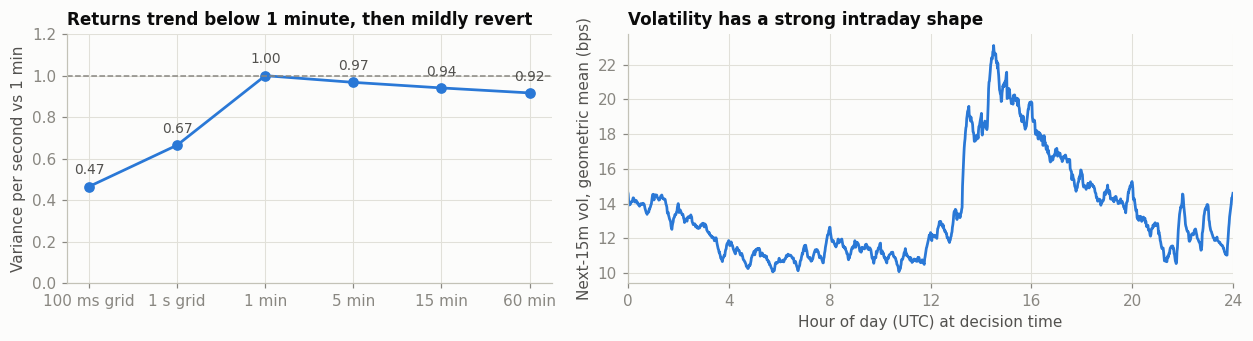

,100 ms grid,1 s grid,1 min,5 min,15 min,60 min
"variance per second, relative to 1 min",0.466,0.665,1.0,0.968,0.941,0.917


In [16]:
DEV_EVAL = ELIGIBLE & IN_DEV & ~IN_CRASH

rows = []
for k in DIR_TARGETS:
    h = HORIZONS[k]; y = Y.loc[DEV_EVAL, k].dropna() * 1e4
    full = Y[k].where(IN_DEV & ~IN_CRASH)
    rows.append(dict(target=k, n=len(y), std_bps=y.std(), mean_bps=y.mean(), skew=y.skew(), excess_kurtosis=y.kurt(),
                     share_up=(y > 0).mean(), autocorr_next_period=full.corr(full.shift(-h))))
ret_stats = pd.DataFrame(rows).set_index("target")
rows = []
for k in VOL_TARGETS:
    h = HORIZONS[k]; l = Y.loc[DEV_EVAL, "l_" + k].dropna(); v = np.sqrt(Y.loc[DEV_EVAL, k].dropna()) * 1e4
    full = Y["l_" + k].where(IN_DEV & ~IN_CRASH)
    rows.append(dict(target=k, n=len(l), median_vol_bps=v.median(), p99_vol_bps=v.quantile(.99), std_log_rv=l.std(), autocorr_next_period=full.corr(full.shift(-h))))
vol_stats = pd.DataFrame(rows).set_index("target")
display(ret_stats.round(3)); display(vol_stats.round(3))

# Variance signature: variance per second measured at different sampling frequencies, relative to 1-minute sampling.
extra = load_bars("time_1m", ["decision_time_ns", "rv_trade_30s_grid100ms", "rv_trade_30s_grid1s"]).loc[:HOLDOUT_START - pd.Timedelta(minutes=1)]
dv = (bars.index >= DEV_START) & (bars.index < HOLDOUT_START) & ~IN_CRASH
lp = np.log(bars["bar_close"].where(dv))
signature = {"100 ms grid": extra.loc[extra.index >= DEV_START, "rv_trade_30s_grid100ms"].mean() / 30,
             "1 s grid": extra.loc[extra.index >= DEV_START, "rv_trade_30s_grid1s"].mean() / 30}
for k_, lab in [(1, "1 min"), (5, "5 min"), (15, "15 min"), (60, "60 min")]:
    signature[lab] = (lp.diff(k_) ** 2).mean() / (60 * k_)
signature = pd.Series(signature); signature = (signature / signature["1 min"]).rename("variance per second, relative to 1 min")
sig_month = pd.DataFrame({m: {"1 s grid": extra.loc[extra.index.strftime("%Y-%m") == m, "rv_trade_30s_grid1s"].mean() / 30 /
                              ((lp.diff()[MONTH == m] ** 2).mean() / 60)} for m in sorted(set(MONTH[dv]))}).T.round(2)
print("1 s grid variance relative to 1 min, by month: min", sig_month.iloc[:, 0].min(), "max", sig_month.iloc[:, 0].max())

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.2), width_ratios=[1, 1.25])
axes[0].plot(signature.index, signature.values, color=C["blue"], marker="o", markersize=6)
axes[0].axhline(1, color=MUTED, lw=1, ls="--")
axes[0].set(title="Returns trend below 1 minute, then mildly revert", ylabel="Variance per second vs 1 min", ylim=(0, 1.2))
for x_, y_ in zip(signature.index, signature.values):
    axes[0].annotate(f"{y_:.2f}", (x_, y_), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=INK2)
prof = Y.loc[DEV_EVAL, "l_rv_15m"].groupby(bars.index[DEV_EVAL].hour * 60 + bars.index[DEV_EVAL].minute).mean()
axes[1].plot(prof.index / 60, np.exp(prof / 2) * 1e4, color=C["blue"])
axes[1].set(title="Volatility has a strong intraday shape", xlabel="Hour of day (UTC) at decision time", ylabel="Next-15m vol, geometric mean (bps)", xlim=(0, 24), xticks=range(0, 25, 4))
plt.tight_layout(); plt.show()
signature.round(3).to_frame().T

**What this shows.**

* **Returns are close to unpredictable from their own past.** Next-period autocorrelation is between −0.01 and −0.02 at all three horizons. The distributions are very fat-tailed (excess kurtosis of 12 to 17), which is why I scale by volatility.
* **Size matters for later.** A 2-minute return has a standard deviation of about 8 bps, so a 10 bps round-trip cost is larger than one standard deviation of the move being forecast.
* **Volatility is highly persistent.** Forward log RV has an autocorrelation near 0.85. Any reasonable volatility model will therefore score a high R², and a high R² on its own says little. Only the improvement over a strong baseline is informative.
* **Volatility has a clear daily shape.** It peaks around 13:30–14:30 UTC, the US open, at about twice the level of the quiet hours, which is why the baseline carries a seasonal prior.

**The RV puzzle from section 4.8 is resolved.** Variance per second is 0.47 at 100 ms, 0.67 at 1 s, and 1.00 at 1 minute, then drifts slightly lower. Noise would make this curve *fall* towards 1 minute; here it *rises*. So returns are positively autocorrelated below one minute: prices adjust over seconds rather than instantly. The 1-second ratio stays between 0.54 and 0.76 in every month, so this is a stable property of the market and the target is sound.

It also sets a limit on this notebook. **Much of the short-term structure in this market happens inside a single one-minute bar**, where these bars cannot see it.

## 6. Which individual features carry signal? `EXPLORATORY`

Before fitting any model, I test each feature on its own against future volatility-scaled returns, using the **daily information coefficient** (IC): the correlation between feature and target within a day, averaged over days. This treats each day equally and answers a simple question: does this feature, alone, line up with the future move?

With about 100 features and 3 horizons, some will look significant by chance. I therefore report the Benjamini–Hochberg false-discovery-adjusted `q` value alongside the HAC t-statistic.

This screen is used for **interpretation only**. It does not choose model inputs. Choosing features this way and then evaluating on the same data would leak the selection into the score.

**A trap worth documenting.** My first version computed the correlation *within* each day and averaged it, a common way to compute a daily IC. It reported an IC of about −0.17 for the past 24-hour return against the next hour, with a t-statistic near −14, which looked like a huge mean-reversion effect. It was an artefact. Demeaning a slow-moving feature inside a short window makes it negatively correlated with its own future increments, the Stambaugh/Kendall small-sample bias. The next cell shows the same bias appearing on a simulated random walk, where no predictability exists. Everything below therefore uses a **non-demeaned** IC: feature and target are scaled once, globally, and the daily mean of their product is averaged over days.

In [17]:
# Demonstration: the same past-24h-return feature under both definitions, and on a pure random walk.
x_ = (X.loc[DEV_EVAL, "z_ret_24h"]).astype(float); y_ = Y.loc[DEV_EVAL, "z_ret_1h"].clip(-6, 6)
ok_ = x_.notna() & y_.notna(); x_, y_ = x_[ok_], y_[ok_]
dk_ = x_.index.floor("D")
within_ic = pd.concat([x_, y_], axis=1).groupby(dk_).apply(lambda g: g.iloc[:, 0].corr(g.iloc[:, 1]), include_groups=False)
global_ic = (((x_ - x_.mean()) / x_.std()) * (y_ / np.sqrt((y_ ** 2).mean()))).groupby(dk_).mean()

rng = np.random.default_rng(SEED)
walk = pd.Series(np.cumsum(rng.standard_normal(400 * 1440)))
wx, wy = ((walk - walk.shift(1440)) / np.sqrt(1440)), ((walk.shift(-60) - walk) / np.sqrt(60))
sim = pd.DataFrame({"x": wx, "y": wy}).dropna()
sim_day = sim.index // 1440
sim_within = sim.groupby(sim_day).apply(lambda g: g["x"].corr(g["y"]), include_groups=False)

pd.DataFrame({"within-day demeaned IC": [within_ic.mean(), sim_within.mean()], "non-demeaned IC": [global_ic.mean(), sim["x"].corr(sim["y"])]},
             index=["z_ret_24h vs next 1h (real data)", "Simulated random walk (no predictability)"]).round(4)

,within-day demeaned IC,non-demeaned IC
z_ret_24h vs next 1h (real data),-0.1686,0.0104
Simulated random walk (no predictability),-0.2002,0.0090


In [18]:
def hac_t(x, lags=5):
    # Mean and Newey-West t-statistic of a daily series. Accounts for serial correlation across days.
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    n = x.size
    if n < 10:
        return np.nan, np.nan
    m = x.mean(); e = x - m
    s = e @ e / n
    for L in range(1, min(lags, n - 1) + 1):
        s += 2 * (1 - L / (lags + 1)) * (e[L:] @ e[:-L]) / n
    return m, m / np.sqrt(max(s, 1e-30) / n)

def two_sided_p(t):
    return 2 * (1 - scipy.stats.norm.cdf(abs(t)))

feats_screen = [c for c in X.columns if c in BLOCK and not c.startswith(("hour", "day_of", "is_weekend"))]
XS = X.loc[DEV_EVAL, feats_screen]
XS = XS.clip(XS.quantile(.005), XS.quantile(.995), axis=1)
XS = (XS - XS.mean()) / XS.std()                         # standardised once, globally: never demeaned within a day
day_key = XS.index.floor("D")

def daily_ic_table(ycol):
    # Daily mean of x*y, with x and y scaled globally. Its mean over days is a correlation that weights days equally.
    y = Y.loc[DEV_EVAL, ycol].clip(-6, 6)
    y = y / np.sqrt((y ** 2).mean())
    return XS.mul(y, axis=0).groupby(day_key).mean()     # days x features

IC_DAILY = {k: daily_ic_table("z_" + k) for k in DIR_TARGETS}

rows = []
for k, ic in IC_DAILY.items():
    for c in ic.columns:
        m, t = hac_t(ic[c].to_numpy())
        rows.append(dict(target=k, feature=c, block=BLOCK[c], mean_ic=m, t_hac=t, share_days_pos=(ic[c] > 0).mean()))
ic_tab = pd.DataFrame(rows)
ic_tab["p"] = two_sided_p(ic_tab["t_hac"])
ic_tab["q_bh"] = multipletests(ic_tab["p"], method="fdr_bh")[1]

summary = ic_tab.assign(sig=ic_tab.q_bh < 0.05).groupby(["target", "block"]).agg(features=("sig", "size"), fdr_significant=("sig", "sum"), best_abs_ic=("mean_ic", lambda s: s.abs().max()))
display(summary.unstack("target").round(3))
for k in DIR_TARGETS:
    print(f"Top features for {k}:")
    display(ic_tab[ic_tab.target == k].assign(a=lambda d: d.t_hac.abs()).sort_values("a", ascending=False).head(8)[["feature", "block", "mean_ic", "t_hac", "share_days_pos", "q_bh"]].round(4).set_index("feature"))

features               fdr_significant               best_abs_ic              
target      ret_15m ret_1h ret_2m         ret_15m ret_1h ret_2m     ret_15m ret_1h ret_2m
block                                                                                    
BASE             20     20     20               2      0      4       0.019  0.021  0.011
BOOK_FLOW        16     16     16               4      3     10       0.011  0.011  0.020
BOOK_STATE       19     19     19               7      6      9       0.023  0.016  0.073
DERIV            15     15     15               1      1      3       0.012  0.022  0.012
FLOW             17     17     17               4      1     10       0.020  0.009  0.022
LIQ              10     10     10               3      0      4       0.015  0.016  0.008

Top features for ret_2m:


,block,mean_ic,t_hac,share_days_pos,q_bh
feature,,,,,
cost_skew_1m_usdt,BOOK_STATE,0.0629,27.5127,0.9837,0.0
weighted_mid_offset_bps,BOOK_STATE,0.0693,26.4822,0.9706,0.0
qi_1,BOOK_STATE,0.0735,19.6886,0.9706,0.0
qi_top5,BOOK_STATE,0.0730,19.5679,0.9575,0.0
qi_1bps,BOOK_STATE,0.0700,19.4222,0.9771,0.0
qi_5bps,BOOK_STATE,0.0389,10.2757,0.8203,0.0
tfi_ratio_5s,FLOW,0.0217,8.2301,0.7059,0.0
signed_run,FLOW,0.0178,8.2285,0.7092,0.0


Top features for ret_15m:


,block,mean_ic,t_hac,share_days_pos,q_bh
feature,,,,,
weighted_mid_offset_bps,BOOK_STATE,0.0217,11.2087,0.7810,0.0000
qi_1,BOOK_STATE,0.0230,10.7213,0.7843,0.0000
qi_top5,BOOK_STATE,0.0227,10.5658,0.7712,0.0000
cost_skew_1m_usdt,BOOK_STATE,0.0179,9.1650,0.7190,0.0000
qi_1bps,BOOK_STATE,0.0188,7.9983,0.6993,0.0000
close_loc_15m,BASE,-0.0187,-4.8596,0.3497,0.0000
basis_mark_index_change_1h_bps,DERIV,-0.0117,-4.1995,0.3529,0.0003
count_imbalance_2m,FLOW,-0.0093,-3.7694,0.3987,0.0013


Top features for ret_1h:


,block,mean_ic,t_hac,share_days_pos,q_bh
feature,,,,,
qi_1,BOOK_STATE,0.0157,7.9468,0.6634,0.0000
weighted_mid_offset_bps,BOOK_STATE,0.0150,7.6383,0.6503,0.0000
qi_top5,BOOK_STATE,0.0155,7.5593,0.6536,0.0000
count_imbalance_2m,FLOW,-0.0095,-3.9477,0.3758,0.0007
cost_skew_1m_usdt,BOOK_STATE,0.0087,3.2529,0.6111,0.0076
tw_qi_1_30s,BOOK_STATE,0.0082,3.0802,0.5458,0.0128
ofi_norm_30s,BOOK_FLOW,0.0055,3.0197,0.4673,0.0146
qi_1bps,BOOK_STATE,0.0077,3.0154,0.5621,0.0146


**Interpretation.**

* **One family dominates.** Top-of-book imbalance measures (`qi_1`, `qi_top5`, `qi_1bps`, `weighted_mid_offset_bps`, `cost_skew_1m_usdt`) reach an IC of about 0.06–0.07 at 2 minutes, with t-statistics of about 20 to 27 and a positive sign on over 95% of days. These are closely related variables, so this is **one signal measured several ways**, not five independent findings.
* **Trade flow is much weaker.** `tfi_ratio_5s` and `signed_run` reach about 0.02.
* **Price and volume alone carry almost nothing.** The largest `BASE` IC at 2 minutes is about 0.01.
* **Significance overstates usefulness at longer horizons.** Many features pass the false-discovery screen at 15 minutes and 1 hour, but with |IC| of roughly 0.02 or less. With hundreds of days, very small effects become detectable without being useful.

### Are the strongest individual signals stable from month to month?

A high average IC can come from one good month. The heatmap shows the monthly mean IC for the strongest features at the shortest horizon. Good evidence is a row with the same color across all months.

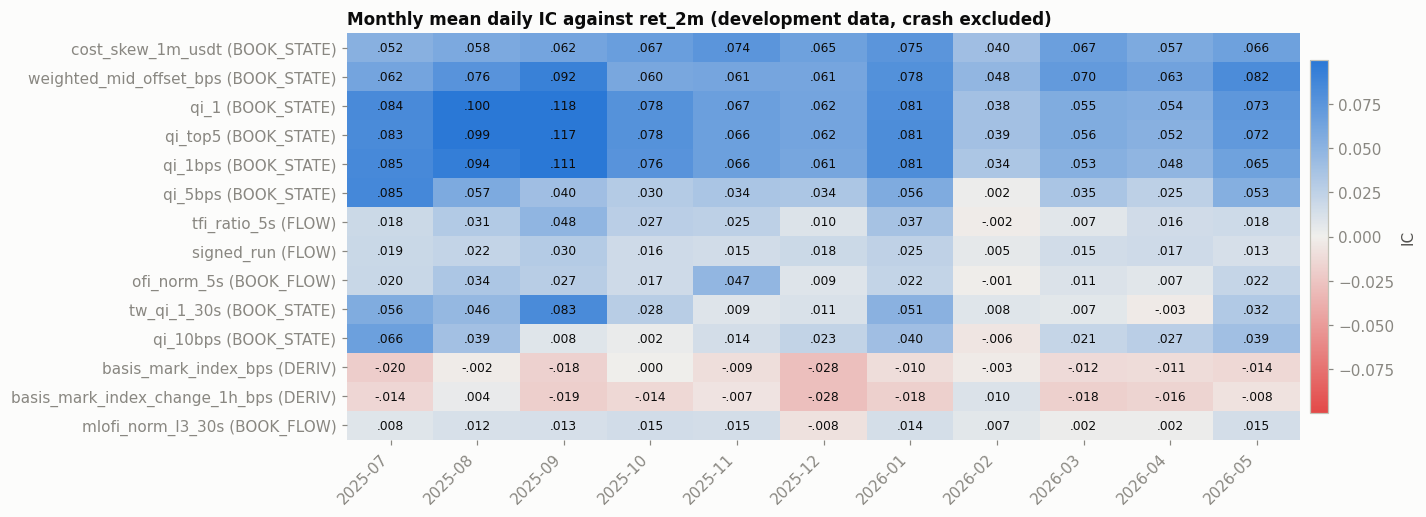

Share of months with the same sign as the full-sample mean:
cost_skew_1m_usdt                 1.00
weighted_mid_offset_bps           1.00
qi_1                              1.00
qi_top5                           1.00
qi_1bps                           1.00
qi_5bps                           1.00
tfi_ratio_5s                      0.91
signed_run                        1.00
ofi_norm_5s                       0.91
tw_qi_1_30s                       0.91
qi_10bps                          0.91
basis_mark_index_bps              0.91
basis_mark_index_change_1h_bps    0.82
mlofi_norm_l3_30s                 0.91


In [19]:
k0 = "ret_2m"
top = ic_tab[ic_tab.target == k0].assign(a=lambda d: d.t_hac.abs()).sort_values("a", ascending=False).head(14)["feature"].tolist()
ic = IC_DAILY[k0][top]
m_ic = ic.groupby(ic.index.strftime("%Y-%m")).mean().T
fig, ax = plt.subplots(figsize=(11.5, 4.8))
lim = float(np.nanpercentile(np.abs(m_ic.values), 98))
im = ax.imshow(m_ic.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(m_ic.shape[1]), m_ic.columns, rotation=45, ha="right"); ax.set_yticks(range(m_ic.shape[0]), [f"{c} ({BLOCK[c]})" for c in m_ic.index])
for i in range(m_ic.shape[0]):
    for j in range(m_ic.shape[1]):
        ax.text(j, i, f"{m_ic.values[i, j]:.3f}".replace("0.", "."), ha="center", va="center", fontsize=8, color=INK)
ax.grid(False); ax.set_title(f"Monthly mean daily IC against {k0} (development data, crash excluded)")
for s in ax.spines.values(): s.set_visible(False)
plt.colorbar(im, ax=ax, fraction=0.018, pad=0.01, label="IC")
plt.show()
print("Share of months with the same sign as the full-sample mean:")
print((np.sign(m_ic).eq(np.sign(m_ic.mean(axis=1)), axis=0)).mean(axis=1).round(2).to_string())

### How quickly does the signal decay?

A key practical question is the lifetime of a signal. If information disappears within a few minutes, only very fast execution could use it. Here I recompute the IC for a few economically distinct features across horizons from 1 minute to 1 hour, and also with a one-minute delay before the forecast window starts.

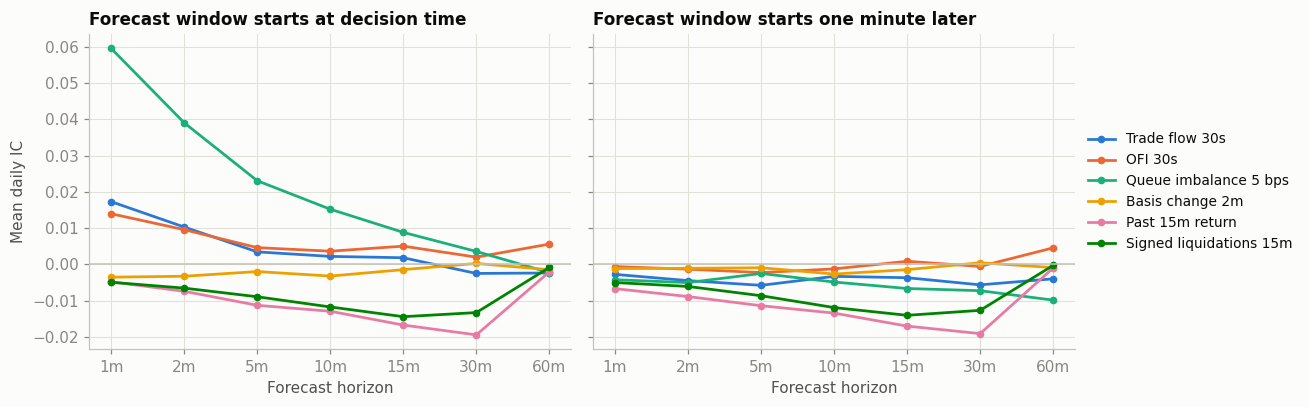

Trade flow 30s  OFI 30s  Queue imbalance 5 bps  Basis change 2m  Past 15m return  Signed liquidations 15m
immediate        1           0.0173   0.0140                 0.0596          -0.0035          -0.0048                  -0.0049
                 5           0.0034   0.0046                 0.0231          -0.0020          -0.0113                  -0.0089
                 60         -0.0024   0.0056                -0.0023          -0.0015          -0.0020                  -0.0008
one_minute_delay 1          -0.0028  -0.0006                -0.0042          -0.0012          -0.0067                  -0.0050
                 5          -0.0058  -0.0023                -0.0025          -0.0009          -0.0114                  -0.0086
                 60         -0.0040   0.0046                -0.0099          -0.0009          -0.0010                  -0.0003

In [20]:
decay_feats = {"tfi_ratio_30s": "Trade flow 30s", "ofi_norm_30s": "OFI 30s", "qi_5bps": "Queue imbalance 5 bps",
               "basis_mark_index_change_2m_bps": "Basis change 2m", "z_ret_15m": "Past 15m return", "slog_liq_signed_15m": "Signed liquidations 15m"}
hs = [1, 2, 5, 10, 15, 30, 60]
lpx = np.log(PX)
XDc = X.loc[DEV_EVAL, list(decay_feats)]
XDc = XDc.clip(XDc.quantile(.005), XDc.quantile(.995), axis=1)
XDc = (XDc - XDc.mean()) / XDc.std()
dk = XDc.index.floor("D")
def mean_daily_ic(h, delay=0):
    y = ((lpx.shift(-h - delay) - lpx.shift(-delay)) / (SIG * np.sqrt(h))).loc[DEV_EVAL].clip(-6, 6)
    y = y / np.sqrt((y ** 2).mean())
    return XDc.mul(y, axis=0).groupby(dk).mean().mean()
decay = pd.DataFrame({h: mean_daily_ic(h) for h in hs}).T
decay_delayed = pd.DataFrame({h: mean_daily_ic(h, delay=1) for h in hs}).T

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, D_, ttl in [(axes[0], decay, "Forecast window starts at decision time"), (axes[1], decay_delayed, "Forecast window starts one minute later")]:
    for (c, lab), color in zip(decay_feats.items(), [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"], C["green"]]):
        ax.plot(range(len(hs)), D_[c], color=color, label=lab, marker="o", markersize=4)
    ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(len(hs)), [f"{h}m" for h in hs]); ax.set(title=ttl, xlabel="Forecast horizon")
axes[0].set_ylabel("Mean daily IC")
axes[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()
pd.concat({"immediate": decay.loc[[1, 5, 60]], "one_minute_delay": decay_delayed.loc[[1, 5, 60]]}).round(4).rename(columns=decay_feats)

**Interpretation.** The left panel shows fast microstructure signals falling quickly: queue imbalance drops from an IC of 0.06 at 1 minute to about 0.02 at 5 minutes. The right panel is the important one. **With a one-minute delay, imbalance, trade flow, and OFI are all essentially gone.** Whatever they predict has already happened within the first minute.

Past return and signed liquidations behave differently. Their small negative IC (mild mean reversion) reaches −0.01 to −0.02 near 15–30 minutes and is the same with or without the delay, so it is slow. It is also small.

### Inside the minute: how fast does queue imbalance pay out?

One-minute bars cannot show what happens in the first seconds after a decision. The project's intermediate 100 ms top-of-book grid can, so this one diagnostic reads `derived/book_grid/btcusdt_v2/grid100ms` (not part of `datasets/btcusdt_v2`, but built by the same run). It uses every 7th development day, sampled every 10 seconds, with the crash excluded.

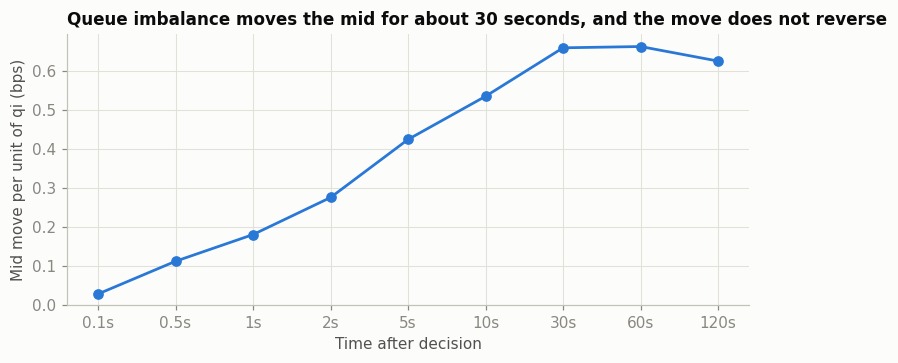

45 days, 373,796 samples. Mean forward mid move in bps by imbalance bucket:


,share_of_samples,1s,5s,30s,60s,120s
qi,,,,,,
below -0.9,0.071,-0.275,-0.554,-0.777,-0.762,-0.696
-0.9 to -0.5,0.200,-0.091,-0.252,-0.419,-0.433,-0.420
-0.5 to 0.5,0.451,-0.000,-0.004,-0.001,0.000,-0.001
0.5 to 0.9,0.204,0.088,0.236,0.401,0.404,0.360
above 0.9,0.074,0.264,0.549,0.756,0.750,0.741


,slope_bps,corr,ret_std_bps,share_of_60s_slope
0.1s,0.029,0.143,0.123,0.043
0.5s,0.113,0.200,0.344,0.170
1s,0.181,0.215,0.514,0.273
2s,0.276,0.219,0.771,0.416
5s,0.425,0.209,1.246,0.641
10s,0.536,0.184,1.781,0.808
30s,0.661,0.129,3.135,0.995
60s,0.664,0.091,4.444,1.000
120s,0.627,0.061,6.254,0.944


In [21]:
GRID = CHDDS / "derived/book_grid/btcusdt_v2/grid100ms"
grid_days = [f for f in sorted(GRID.glob("*.parquet")) if "2025-07-22" <= f.stem < HOLDOUT_START.strftime("%Y-%m-%d") and not ("2025-10-08" <= f.stem <= "2025-10-11")][::7]
steps = [1, 5, 10, 20, 50, 100, 300, 600, 1200]               # in units of 100 ms
parts = []
for f in grid_days:
    g_ = pq.read_table(f, columns=["state", "mid2_ticks", "qty_bid1_e3", "qty_ask1_e3"]).to_pandas()
    lm = np.log(g_["mid2_ticks"].where(g_["state"].isin([0, 9]) & (g_["mid2_ticks"] > 0)).to_numpy(float))
    q_ = ((g_["qty_bid1_e3"] - g_["qty_ask1_e3"]) / (g_["qty_bid1_e3"] + g_["qty_ask1_e3"])).to_numpy()
    pos = np.arange(0, len(g_) - 1300, 100)                   # one sample every 10 s
    parts.append(pd.DataFrame({"qi": q_[pos], **{f"f{k}": (lm[pos + k] - lm[pos]) * 1e4 for k in steps}}))
G = pd.concat(parts, ignore_index=True).dropna()

life = pd.DataFrame({f"{k / 10:g}s": {"slope_bps": np.polyfit(G["qi"], G[f"f{k}"], 1)[0], "corr": G["qi"].corr(G[f"f{k}"]), "ret_std_bps": G[f"f{k}"].std()} for k in steps}).T
life["share_of_60s_slope"] = life["slope_bps"] / life.loc["60s", "slope_bps"]
buckets = pd.cut(G["qi"], [-1.001, -.9, -.5, .5, .9, 1.001], labels=["below -0.9", "-0.9 to -0.5", "-0.5 to 0.5", "0.5 to 0.9", "above 0.9"])
by_bucket = G.groupby(buckets, observed=True)[["f10", "f50", "f300", "f600", "f1200"]].mean().rename(columns={"f10": "1s", "f50": "5s", "f300": "30s", "f600": "60s", "f1200": "120s"})
by_bucket.insert(0, "share_of_samples", G.groupby(buckets, observed=True).size() / len(G))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(len(life)), life["slope_bps"], color=C["blue"], marker="o", markersize=6)
ax.set_xticks(range(len(life)), life.index); ax.set(title="Queue imbalance moves the mid for about 30 seconds, and the move does not reverse", xlabel="Time after decision", ylabel="Mid move per unit of qi (bps)", ylim=(0, None))
plt.show()
print(f"{len(grid_days)} days, {len(G):,} samples. Mean forward mid move in bps by imbalance bucket:")
display(by_bucket.round(3)); life.round(3)

**Interpretation.** This is the clearest picture of the main direction signal.

* **It is real price movement, not noise.** The mid moves in the predicted direction for about 30 seconds and then *stays* there out to 2 minutes. A bounce or measurement artefact would revert.
* **It arrives fast.** About 27% of the eventual move happens within 1 second, 64% within 5 seconds, and 81% within 10 seconds. A trader reacting even a few seconds late has lost most of it.
* **It is small.** At the extremes, where |`qi_1`| is above 0.9 (about 15% of samples), the move is about ±0.75 bps. That is more than 60 ticks, large in book terms, but less than a fifth of even the cheapest round-trip fee considered in section 13.

Here the book diagnostic uses 45 days, and it measures the raw imbalance alone, not a fitted model.

## 7. Modelling harness

The code below is deliberately short. There is one walk-forward loop, used unchanged for development, all sensitivity checks, and the holdout, so the holdout runs exactly what was tested.

For each test month it:

1. Takes training rows ending 60 minutes before the month starts, and removes the crash.
2. Fits clipping bounds, medians, and scaling on training rows only.
3. Uses the last 20% of training, in time order, to pick the Ridge penalty (or the last 15% for LightGBM's early stopping).
4. Predicts the test month. Rows beyond the end of the test month are never touched.

**Direction forecasts have no intercept.** A model trained during a bear market would otherwise simply predict continued decline, which is drift rather than signal. Scoring against a zero forecast then measures only what the features add.

**Configurations.** `+X` adds one block to `BASE` and answers "does X add anything to the baseline?". `ALL-X` removes one block from the full model and answers "is X still needed given everything else?". These can differ, because blocks overlap.

In [22]:
ALPHAS = 10.0 ** np.arange(0, 9)
LGB_COMMON = dict(objective="regression", learning_rate=0.03, num_leaves=15, max_depth=5, feature_fraction=0.5, bagging_fraction=0.5, bagging_freq=1,
                  lambda_l2=50.0, max_bin=63, num_threads=THREADS, seed=SEED, deterministic=True, force_row_wise=True, verbosity=-1)
LGB_PARAMS = {False: dict(LGB_COMMON, min_data_in_leaf=2000), True: dict(LGB_COMMON, min_data_in_leaf=500)}   # keyed by is_vol
LGB_ROUNDS = {False: 300, True: 1500}    # the first development run hit a 500-round cap on volatility, so it was raised for BASE and ALL alike
LGB_STRIDE = 2     # adjacent one-minute rows are nearly duplicates for overlapping targets; halves the fit cost

BLOCKS_ALL = ["BASE", "FLOW", "BOOK_STATE", "BOOK_FLOW", "DERIV", "LIQ"]
CONFIGS = {"NAIVE": ["NAIVE"], "BASE": ["BASE"], "+FLOW": ["BASE", "FLOW"], "+BOOK_STATE": ["BASE", "BOOK_STATE"], "+BOOK_FLOW": ["BASE", "BOOK_FLOW"],
           "+BOOK": ["BASE", "BOOK_STATE", "BOOK_FLOW"], "+DERIV": ["BASE", "DERIV"], "+LIQ": ["BASE", "LIQ"], "ALL": BLOCKS_ALL,
           "ALL-FLOW": ["BASE", "BOOK_STATE", "BOOK_FLOW", "DERIV", "LIQ"], "ALL-BOOK": ["BASE", "FLOW", "DERIV", "LIQ"],
           "ALL-DERIV": ["BASE", "FLOW", "BOOK_STATE", "BOOK_FLOW", "LIQ"], "ALL-LIQ": ["BASE", "FLOW", "BOOK_STATE", "BOOK_FLOW", "DERIV"]}

def make_ctx(Xdf, Ydf, eligible, crash, ykey, vol_targets, purge):
    t = Xdf.index
    return dict(t=t, tn=t.asi8, X=Xdf.to_numpy(np.float32), feats=list(Xdf.columns), Y=Ydf, elig=np.asarray(eligible), crash=np.asarray(crash),
                ykey=ykey, vol=set(vol_targets), purge=purge)

CTX = make_ctx(X, Y, ELIGIBLE, IN_CRASH, {k: target_key(k) for k in HORIZONS}, VOL_TARGETS, pd.Timedelta(minutes=PURGE_BARS))

def col_index(ctx, blocks, target):
    pos = {c: i for i, c in enumerate(ctx["feats"])}
    return np.array([pos[c] for c in feature_set(blocks, target) if c in pos])

def scaler_fit(Xtr):
    s = Xtr[::3]                                          # quantiles do not need every row
    lo, hi = np.nanquantile(s, [.001, .999], axis=0)
    med = np.nanmedian(s, axis=0)
    c = np.clip(s, lo, hi); c = np.where(np.isnan(c), med, c)
    return lo, hi, med, c.mean(0), c.std(0) + 1e-9

def scaler_apply(Xa, par):
    lo, hi, med, mu, sd = par
    Z = np.clip(Xa, lo, hi); Z = np.where(np.isnan(Z), med, Z)
    return ((Z - mu) / sd).astype(np.float32)

def ridge_suite(Z, y, tr, te, col_sets, purge_rows, is_vol):
    # Closed-form Ridge for many feature sets. One Gram matrix per target is sliced for each configuration.
    cut = int(len(tr) * 0.8)
    fit, val = tr[:cut - purge_rows], tr[cut:]            # purged, time-ordered inner split
    yfm, ytm = y[fit].mean(), y[tr].mean()
    Zf = Z[fit].astype(np.float64); Gf = Zf.T @ Zf; bf = Zf.T @ (y[fit] - yfm); del Zf
    Za = Z[tr].astype(np.float64); Ga = Za.T @ Za; ba = Za.T @ (y[tr] - ytm); del Za
    Zv, Zt, yv = Z[val], Z[te], y[val] - yfm
    preds, info = {}, {}
    for name, ix in col_sets.items():
        w, V = np.linalg.eigh(Gf[np.ix_(ix, ix)])
        c = V.T @ bf[ix]
        errs = [np.mean((yv - Zv[:, ix] @ (V @ (c / (w + a)))) ** 2) for a in ALPHAS]
        a = ALPHAS[int(np.argmin(errs))]
        beta = np.linalg.solve(Ga[np.ix_(ix, ix)] + a * np.eye(len(ix)), ba[ix])
        preds[name] = Zt[:, ix] @ beta + (ytm if is_vol else 0.0)
        info[name] = dict(alpha=a, s2=float(min(errs)), beta=beta)
    return preds, info

def lgb_fit_predict(Xr, y, tr, te, ix, is_vol, purge_rows):
    cut = int(len(tr) * 0.85)
    fit, val = tr[:cut - purge_rows:LGB_STRIDE], tr[cut:]
    ym = y[fit].mean()
    dtr = lgb.Dataset(Xr[np.ix_(fit, ix)], label=y[fit] - ym, free_raw_data=True)
    dva = lgb.Dataset(Xr[np.ix_(val, ix)], label=y[val] - ym, reference=dtr, free_raw_data=True)
    bst = lgb.train(LGB_PARAMS[is_vol], dtr, LGB_ROUNDS[is_vol], valid_sets=[dva], callbacks=[lgb.early_stopping(30, verbose=False)])
    it = bst.best_iteration or LGB_ROUNDS[is_vol]
    s2 = float(np.mean((y[val] - ym - bst.predict(Xr[np.ix_(val, ix)], num_iteration=it)) ** 2))
    return bst.predict(Xr[np.ix_(te, ix)], num_iteration=it) + (ym if is_vol else 0.0), it, s2

def run_walk_forward(ctx, folds, targets, configs=CONFIGS, lgb_configs=("BASE", "+BOOK", "ALL"), include_crash=False, y_override=None, X_override=None,
                     extra_purge=pd.Timedelta(0), train_start=DEV_START):
    # One loop for development, controls, and holdout. Returns {target: DataFrame of out-of-sample rows}, plus fit diagnostics.
    t, tn = ctx["t"], ctx["tn"]
    Xfull = ctx["X"] if X_override is None else X_override
    out = {k: [] for k in targets}; diag = []
    purge_rows = int(ctx["purge"] / pd.Timedelta(minutes=1)) if ctx.get("per_minute", True) else ctx["purge_rows"]
    for fold in folds:
        start = pd.Timestamp(f"{fold}-01", tz=UTC); end = start + pd.offsets.MonthBegin(1)
        tr_end = start - ctx["purge"] - extra_purge
        hi = int(np.searchsorted(tn, end.value))                         # rows after this month are never read
        train_rows = ctx["elig"][:hi] & (tn[:hi] >= train_start.value) & (tn[:hi] < tr_end.value)
        if not include_crash:
            train_rows &= ~ctx["crash"][:hi]
        par = scaler_fit(Xfull[:hi][train_rows])
        Z = scaler_apply(Xfull[:hi], par)
        for k in targets:
            is_vol = k in ctx["vol"]
            ycol = (y_override[k] if y_override and k in y_override else ctx["Y"][ctx["ykey"][k]]).to_numpy(np.float64)[:hi]
            finite = np.isfinite(ycol)
            tr = np.flatnonzero(train_rows & finite)
            te = np.flatnonzero(ctx["elig"][:hi] & finite & (tn[:hi] >= start.value))
            sets = {name: col_index(ctx, blocks, k) for name, blocks in configs.items()}
            preds, info = ridge_suite(Z, ycol, tr, te, sets, purge_rows, is_vol)
            frame = {"row": te, "y": ycol[te].astype(np.float32), "ybar": np.float32(ycol[tr].mean()), "fold": fold}
            for name, p in preds.items():
                frame["ridge_" + name] = p.astype(np.float32)
                if is_vol:
                    frame["ridge_" + name + "|lvl"] = (p + 0.5 * info[name]["s2"]).astype(np.float32)   # log-normal level correction
                diag.append(dict(fold=fold, target=k, model="ridge_" + name, n_train=len(tr), n_test=len(te), alpha=info[name]["alpha"]))
            if "ALL" in info:
                ctx.setdefault("betas", {})[(k, fold)] = dict(zip(np.array(ctx["feats"])[sets["ALL"]], info["ALL"]["beta"]))
            for name in lgb_configs:
                p, it, s2 = lgb_fit_predict(Xfull, ycol, tr, te, sets[name], is_vol, purge_rows)
                frame["lgb_" + name] = p.astype(np.float32)
                if is_vol:
                    frame["lgb_" + name + "|lvl"] = (p + 0.5 * s2).astype(np.float32)
                diag.append(dict(fold=fold, target=k, model="lgb_" + name, n_train=len(tr) // LGB_STRIDE, n_test=len(te), rounds=it))
            out[k].append(pd.DataFrame(frame))
        del Z
    return {k: pd.concat(v, ignore_index=True) for k, v in out.items()}, pd.DataFrame(diag)

# ---- evaluation. All inference is on daily aggregates.
def with_days(P, ctx=None):
    ctx = ctx or CTX
    t = ctx["t"][P["row"].to_numpy()]
    return P.assign(day=t.floor("D"), month=t.strftime("%Y-%m"), crash=ctx["crash"][P["row"].to_numpy()])

def block_boot(num, den, block=5, reps=2000, seed=SEED):
    # 95% CI of sum(num)/sum(den) from a circular moving-block bootstrap over days.
    rng = np.random.default_rng(seed); n = len(num)
    starts = rng.integers(0, n, size=(reps, int(np.ceil(n / block))))
    idx = ((starts[:, :, None] + np.arange(block)) % n).reshape(reps, -1)[:, :n]
    return np.percentile(num[idx].sum(1) / den[idx].sum(1), [2.5, 97.5])

def score_direction(P, model, base=None):
    y, f = P["y"].to_numpy(np.float64), P[model].to_numpy(np.float64)
    g = P["day"].to_numpy()
    df_ = pd.DataFrame({"d": g, "y": y, "f": f})
    sst_d = df_.assign(v=y ** 2).groupby("d")["v"].sum()
    gain_d = df_.assign(v=y ** 2 - (y - f) ** 2).groupby("d")["v"].sum()
    # Non-demeaned IC, as in section 6. A within-day correlation would be biased for persistent forecasts.
    rms_f, rms_y = np.sqrt(np.mean(f ** 2)), np.sqrt(np.mean(y ** 2))
    prod = pd.Series((f / rms_f) * (y / rms_y) if rms_f > 0 else np.zeros_like(y))
    ic_d = prod.groupby(g).mean()
    m_ic, t_ic = hac_t(ic_d.to_numpy())
    r = dict(n=len(y), days=len(ic_d), r2_pct=100 * gain_d.sum() / sst_d.sum(), ic=m_ic, ic_t=t_ic, hit=float(np.mean(np.sign(y[(y != 0) & (f != 0)]) == np.sign(f[(y != 0) & (f != 0)]))) if rms_f > 0 else np.nan)
    lo, hi = block_boot(gain_d.to_numpy(), sst_d.to_numpy())
    r.update(r2_lo=100 * lo, r2_hi=100 * hi)
    months = prod.groupby(P["month"].to_numpy()).mean()
    r["months_ic_pos"] = f"{int((months > 0).sum())}/{len(months)}"
    if base:
        f0 = P[base].to_numpy(np.float64)
        adj = (y - f0) ** 2 - ((y - f) ** 2 - (f0 - f) ** 2)                        # Clark-West adjusted difference
        cw = pd.Series(adj).groupby(g).mean().to_numpy()
        _, t = hac_t(cw)
        d_gain = pd.Series((y - f0) ** 2 - (y - f) ** 2).groupby(g).sum().to_numpy()
        dl, dh = block_boot(d_gain, sst_d.to_numpy())
        r.update(d_r2_pct=100 * d_gain.sum() / sst_d.sum(), d_r2_lo=100 * dl, d_r2_hi=100 * dh, cw_t=t, cw_p=1 - scipy.stats.norm.cdf(t))
    return r

def qlike(y_log, f_lvl_log):
    # QLIKE on variance levels, using log inputs: RV/F - log(RV/F) - 1. Robust to noise in the volatility proxy.
    d = y_log - f_lvl_log
    return np.exp(d) - d - 1

def score_vol(P, model, base=None):
    y, f, fl = P["y"].to_numpy(np.float64), P[model].to_numpy(np.float64), P[model + "|lvl"].to_numpy(np.float64)
    g = P["day"].to_numpy(); ybar = P["ybar"].to_numpy(np.float64)
    sse, sst = (y - f) ** 2, (y - ybar) ** 2
    ql = qlike(y, fl)
    r = dict(n=len(y), days=P["day"].nunique(), r2_pct=100 * (1 - sse.sum() / sst.sum()), rmse_log=float(np.sqrt(sse.mean())), qlike=float(ql.mean()))
    if base:
        f0, fl0 = P[base].to_numpy(np.float64), P[base + "|lvl"].to_numpy(np.float64)
        sse0, ql0 = (y - f0) ** 2, qlike(y, fl0)
        d_q = pd.Series(ql0 - ql).groupby(g).mean().to_numpy()
        d_m = pd.Series(sse0 - sse).groupby(g).mean().to_numpy()
        _, t_q = hac_t(d_q); _, t_m = hac_t(d_m)
        sst_d = pd.Series(sst).groupby(g).sum().to_numpy()
        lo, hi = block_boot(pd.Series(sse0 - sse).groupby(g).sum().to_numpy(), sst_d)
        monthly = pd.DataFrame({"m": P["month"].to_numpy(), "d": ql0 - ql}).groupby("m")["d"].mean()
        r.update(d_r2_pct=100 * (sse0.sum() - sse.sum()) / sst.sum(), d_r2_lo=100 * lo, d_r2_hi=100 * hi, qlike_gain_pct=100 * (1 - ql.mean() / ql0.mean()),
                 dm_t_mse=t_m, dm_t_qlike=t_q, dm_p_qlike=two_sided_p(t_q), months_better=f"{int((monthly > 0).sum())}/{len(monthly)}")
    return r
print("Harness ready.")

Harness ready.


## 8. Walk-forward results on development data `EXPLORATORY`

Eight monthly test folds, October 2025 to May 2026, with crash rows excluded from every score below. Volatility comes first because it is the stronger result, then direction.

In [23]:
t_start = time.time()
P_DEV, DIAG_DEV = run_walk_forward(CTX, DEV_FOLDS, list(HORIZONS))
P_DEV = {k: with_days(v) for k, v in P_DEV.items()}
print(f"Walk-forward finished in {(time.time() - t_start) / 60:.1f} min.")
print(DIAG_DEV[DIAG_DEV.model == "ridge_ALL"].groupby("target")[["n_train", "n_test"]].agg({"n_train": ["min", "max"], "n_test": "sum"}).to_string())
print("\nRidge penalty chosen for the full model, by fold (a very large value means Ridge shrinks towards zero):")
print(DIAG_DEV[DIAG_DEV.model == "ridge_ALL"].pivot(index="target", columns="fold", values="alpha").map(lambda a: f"1e{int(np.log10(a))}").to_string())
print("\nLightGBM boosting rounds selected by early stopping:")
print(DIAG_DEV[DIAG_DEV.model == "lgb_ALL"].pivot(index="target", columns="fold", values="rounds").astype(int).to_string())

Walk-forward finished in 6.3 min.
        n_train          n_test
            min     max     sum
target                         
ret_15m   97341  361886  299758
ret_1h    97314  361849  299741
ret_2m    97345  362036  299911
rv_15m    95563  351194  289343
rv_1h     90520  321876  261142

Ridge penalty chosen for the full model, by fold (a very large value means Ridge shrinks towards zero):
fold    2025-10 2025-11 2025-12 2026-01 2026-02 2026-03 2026-04 2026-05
target                                                                 
ret_15m     1e5     1e7     1e5     1e6     1e6     1e7     1e8     1e8
ret_1h      1e8     1e5     1e4     1e7     1e8     1e8     1e8     1e8
ret_2m      1e4     1e5     1e6     1e5     1e5     1e6     1e6     1e6
rv_15m      1e2     1e3     1e0     1e0     1e0     1e0     1e1     1e4
rv_1h       1e3     1e4     1e0     1e0     1e0     1e0     1e0     1e4

LightGBM boosting rounds selected by early stopping:
fold     2025-10  2025-11  2025-12  2026-01  20

In [24]:
def aggregate(P):
    return P[~P["crash"]]

VOL_MODELS = ["ridge_NAIVE", "ridge_BASE", "ridge_+FLOW", "ridge_+BOOK_STATE", "ridge_+BOOK_FLOW", "ridge_+BOOK", "ridge_+DERIV", "ridge_+LIQ", "ridge_ALL", "lgb_BASE", "lgb_+BOOK", "lgb_ALL"]
def vol_table(Pd):
    rows = {}
    for k in VOL_TARGETS:
        Pk = aggregate(Pd[k])
        for m in VOL_MODELS:
            base = None if m in ("ridge_NAIVE", "ridge_BASE", "lgb_BASE") else ("lgb_BASE" if m.startswith("lgb") else "ridge_BASE")
            rows[(k, m)] = score_vol(Pk, m, base)
    return pd.DataFrame(rows).T

def fmt_vol(t):
    cols = ["n", "r2_pct", "rmse_log", "qlike", "d_r2_pct", "d_r2_lo", "d_r2_hi", "qlike_gain_pct", "dm_t_qlike", "dm_p_qlike", "months_better"]
    out = t[cols].copy()
    for c in cols[1:-1]:
        out[c] = pd.to_numeric(out[c]).round(3)
    out["n"] = out["n"].astype(int)
    return out

VOL_DEV = vol_table(P_DEV)
display(fmt_vol(VOL_DEV))

# Head-to-head across model classes: does a linear model WITH microstructure beat a nonlinear model WITHOUT it?
def head_to_head(Pd):
    rows = {}
    for k in VOL_TARGETS:
        s_ = score_vol(aggregate(Pd[k]), "ridge_ALL", "lgb_BASE")
        rows[k] = dict(qlike_ridge_ALL=s_["qlike"], qlike_lgb_BASE=score_vol(aggregate(Pd[k]), "lgb_BASE")["qlike"], gain_of_ridge_ALL_pct=s_["qlike_gain_pct"], dm_t=s_["dm_t_qlike"], dm_p=s_["dm_p_qlike"], months_ridge_ALL_better=s_["months_better"])
    return pd.DataFrame(rows).T
head_to_head(P_DEV)

n  r2_pct  rmse_log  qlike  d_r2_pct  d_r2_lo  d_r2_hi  qlike_gain_pct  dm_t_qlike  dm_p_qlike months_better
rv_15m ridge_NAIVE        285732  77.220     0.652  0.259       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       ridge_BASE         285732  81.349     0.590  0.230       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       ridge_+FLOW        285732  81.380     0.590  0.230     0.032   -0.064    0.111          -0.094      -0.225       0.822           4/8
       ridge_+BOOK_STATE  285732  81.425     0.589  0.228     0.077   -0.022    0.175           0.544       1.451       0.147           6/8
       ridge_+BOOK_FLOW   285732  81.582     0.587  0.226     0.233    0.102    0.363           1.336       2.888       0.004           6/8
       ridge_+BOOK        285732  81.594     0.586  0.226     0.245    0.077    0.398           1.476       2.594       0.009           6/8
       ridge_+DERIV       285732  81.375     0.590  0.230     0.027   -0.243    0.265          -0.033       0.063       0.950           6/8
       ridge_+LIQ         285732  81.560     0.587  0.228     0.211    0.099    0.322           0.837       1.893       0.058           5/8
       ridge_ALL          285732  81.740     0.584  0.226     0.392    0.100    0.674           1.469       1.486       0.137           6/8
       lgb_BASE           285732  81.921     0.581  0.214       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       lgb_+BOOK          285732  81.882     0.582  0.214    -0.039   -0.300    0.163           0.332       0.691       0.489           7/8
       lgb_ALL            285732  81.806     0.583  0.215    -0.115   -0.386    0.142          -0.203      -0.423       0.672           4/8
rv_1h  ridge_NAIVE        257959  72.884     0.669  0.262       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       ridge_BASE         257959  79.445     0.583  0.223       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       ridge_+FLOW        257959  79.368     0.584  0.225    -0.077   -0.192    0.018          -0.649      -1.520       0.129           4/8
       ridge_+BOOK_STATE  257959  79.533     0.582  0.222     0.088   -0.081    0.254           0.389       0.641       0.522           5/8
       ridge_+BOOK_FLOW   257959  79.610     0.580  0.223     0.165    0.004    0.309           0.229      -0.203       0.839           5/8
       ridge_+BOOK        257959  79.660     0.580  0.222     0.214   -0.027    0.439           0.561       0.307       0.759           7/8
       ridge_+DERIV       257959  79.508     0.582  0.220     0.062   -0.403    0.477           1.469       1.517       0.129           6/8
       ridge_+LIQ         257959  79.637     0.580  0.222     0.192    0.057    0.318           0.653       1.036       0.300           4/8
       ridge_ALL          257959  79.659     0.580  0.220     0.214   -0.391    0.776           1.337       0.721       0.471           6/8
       lgb_BASE           257959  80.168     0.572  0.206       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       lgb_+BOOK          257959  80.077     0.574  0.206    -0.091   -0.349    0.110          -0.096      -0.039       0.968           4/8
       lgb_ALL            257959  79.638     0.580  0.208    -0.530   -0.956   -0.136          -1.369      -1.347       0.178           3/8

,qlike_ridge_ALL,qlike_lgb_BASE,gain_of_ridge_ALL_pct,dm_t,dm_p,months_ridge_ALL_better
rv_15m,0.226142,0.214409,-5.472375,-2.422271,0.015424,1/8
rv_1h,0.220173,0.205522,-7.128701,-1.756814,0.07895,2/8


**Reading the table.** `r2_pct` is out-of-sample R² on log RV, `d_r2_*` is the change against the baseline of the same model class, with its bootstrap interval, and `qlike_gain_pct` is the percent reduction in QLIKE. `dm_*` is a Diebold–Mariano test on daily losses (p-values here are unadjusted).

**What development suggests.**

1. **Volatility is highly forecastable.** `BASE` reaches an R² of 81% at 15 minutes and 79% at 1 hour, against 77% and 73% for a one-feature model. Most of this is volatility persistence plus the seasonal prior.
2. **Against a linear baseline, the book helps a little.** `+BOOK_FLOW` and `+BOOK` cut QLIKE by about 1.3–1.5% at 15 minutes, with Diebold–Mariano p-values below 0.01 before adjustment. The full model has a similar point estimate but is not significant, and nothing is clear at 1 hour.
3. **Against a nonlinear baseline, that gain disappears.** LightGBM on `BASE` alone is the best model in the table, with QLIKE of 0.214 and 0.206, compared with about 0.226 and 0.220 for Ridge with every feature. Adding the book to LightGBM changes QLIKE by +0.3% and −0.1%, and adding everything makes it slightly worse.
4. **The head-to-head is decisive for this period.** Ridge with microstructure loses to LightGBM without it by 5.5% and 7.1%, and wins in only 1 or 2 of 8 months.

So on development data, **the apparent microstructure gain for volatility mostly reflects nonlinearity in price and volume that a better baseline already captures.** This is why the choice of baseline matters so much for the research question.

**Two process notes.** In the first run, LightGBM's volatility fits stopped at a 500-round cap, which could have penalised the larger model unfairly. I raised the cap to 1,500 for all configurations. Fits now converge and the conclusion did not change. I added `lgb_+BOOK` after seeing `lgb_ALL` underperform, to check whether extra features were simply diluting the model. That did not rescue the gain either.

In [25]:
DIR_MODELS = ["ridge_BASE", "ridge_+FLOW", "ridge_+BOOK_STATE", "ridge_+BOOK_FLOW", "ridge_+BOOK", "ridge_+DERIV", "ridge_+LIQ", "ridge_ALL", "lgb_BASE", "lgb_+BOOK", "lgb_ALL"]
def dir_table(Pd):
    rows = {}
    for k in DIR_TARGETS:
        Pk = aggregate(Pd[k])
        for m in DIR_MODELS:
            base = None if m in ("ridge_BASE", "lgb_BASE") else ("lgb_BASE" if m.startswith("lgb") else "ridge_BASE")
            rows[(k, m)] = score_direction(Pk, m, base)
    return pd.DataFrame(rows).T

def fmt_dir(t):
    cols = ["n", "r2_pct", "r2_lo", "r2_hi", "ic", "ic_t", "hit", "months_ic_pos", "d_r2_pct", "d_r2_lo", "d_r2_hi", "cw_t", "cw_p"]
    out = t[cols].copy()
    for c in [c for c in cols if c not in ("n", "months_ic_pos")]:
        out[c] = pd.to_numeric(out[c]).round(4)
    out["n"] = out["n"].astype(int)
    return out

DIR_DEV = dir_table(P_DEV)
fmt_dir(DIR_DEV)

n  r2_pct   r2_lo   r2_hi      ic     ic_t     hit months_ic_pos  d_r2_pct  d_r2_lo  d_r2_hi     cw_t    cw_p
ret_2m  ridge_BASE         296147 -0.0045 -0.0261  0.0148  0.0077   2.2672  0.5104           6/8       NaN      NaN      NaN      NaN     NaN
        ridge_+FLOW        296147  0.0309 -0.0081  0.0734  0.0216   5.0406  0.5120           8/8    0.0354  -0.0012   0.0746   4.6870  0.0000
        ridge_+BOOK_STATE  296147  0.3690  0.2749  0.4588  0.0604  12.2755  0.5299           8/8    0.3736   0.2768   0.4682  13.0408  0.0000
        ridge_+BOOK_FLOW   296147 -0.0012 -0.0337  0.0335  0.0124   3.4878  0.5127           8/8    0.0034  -0.0252   0.0314   3.3272  0.0004
        ridge_+BOOK        296147  0.3656  0.2690  0.4584  0.0603  12.4370  0.5306           8/8    0.3701   0.2700   0.4677  13.2244  0.0000
        ridge_+DERIV       296147 -0.0082 -0.0337  0.0164  0.0086   2.4904  0.5128           7/8   -0.0037  -0.0260   0.0184   2.2004  0.0139
        ridge_+LIQ         296147 -0.0090 -0.0306  0.0092  0.0051   1.7088  0.5119           6/8   -0.0045  -0.0150   0.0040   0.1445  0.4425
        ridge_ALL          296147  0.3593  0.2457  0.4688  0.0603  12.0594  0.5309           8/8    0.3639   0.2471   0.4783  12.6571  0.0000
        lgb_BASE           296147  0.0211  0.0021  0.0400  0.0143   4.8642  0.5073           7/8       NaN      NaN      NaN      NaN     NaN
        lgb_+BOOK          296147  0.5156  0.4012  0.6317  0.0701  12.0552  0.5308           8/8    0.4945   0.3899   0.6024  12.3814  0.0000
        lgb_ALL            296147  0.5305  0.4171  0.6451  0.0709  11.7500  0.5310           8/8    0.5094   0.4050   0.6164  12.1581  0.0000
ret_15m ridge_BASE         295997 -0.0158 -0.1011  0.0549  0.0073   0.8834  0.5099           6/8       NaN      NaN      NaN      NaN     NaN
        ridge_+FLOW        295997 -0.0048 -0.0929  0.0794  0.0130   1.7074  0.5120           7/8    0.0109  -0.0278   0.0487   1.8729  0.0305
        ridge_+BOOK_STATE  295997  0.0215 -0.0641  0.1017  0.0166   2.1979  0.5124           7/8    0.0373   0.0128   0.0646   4.0876  0.0000
        ridge_+BOOK_FLOW   295997 -0.0049 -0.0858  0.0665  0.0102   1.3089  0.5108           6/8    0.0109  -0.0057   0.0291   1.8803  0.0300
        ridge_+BOOK        295997  0.0293 -0.0476  0.1014  0.0176   2.5035  0.5130           7/8    0.0450   0.0151   0.0777   3.8404  0.0001
        ridge_+DERIV       295997 -0.0353 -0.1060  0.0307  0.0048   0.7784  0.5110           5/8   -0.0195  -0.0643   0.0259   0.2004  0.4206
        ridge_+LIQ         295997 -0.0145 -0.0983  0.0542  0.0081   1.1024  0.5114           7/8    0.0013  -0.0179   0.0233   0.6738  0.2502
        ridge_ALL          295997 -0.0085 -0.0912  0.0680  0.0128   2.1758  0.5160           7/8    0.0072  -0.0680   0.0809   2.1410  0.0161
        lgb_BASE           295997  0.0517 -0.0030  0.1061  0.0135   1.3861  0.5122           8/8       NaN      NaN      NaN      NaN     NaN
        lgb_+BOOK          295997  0.0684 -0.0179  0.1573  0.0221   3.0023  0.5133           8/8    0.0167  -0.0368   0.0710   3.2539  0.0006
        lgb_ALL            295997 -0.0283 -0.1654  0.1024  0.0138   1.6386  0.5146           8/8   -0.0800  -0.1886   0.0175   0.7390  0.2300
ret_1h  ridge_BASE         295988 -0.0049 -0.2670  0.2482  0.0190   1.2086  0.5008           5/8       NaN      NaN      NaN      NaN     NaN
        ridge_+FLOW        295988 -0.0112 -0.2749  0.2338  0.0193   1.3223  0.5008           5/8   -0.0063  -0.0435   0.0266   0.5435  0.2934
        ridge_+BOOK_STATE  295988 -0.0157 -0.2907  0.2488  0.0197   1.3249  0.5015           5/8   -0.0108  -0.0502   0.0251   0.8933  0.1858
        ridge_+BOOK_FLOW   295988  0.0122 -0.2421  0.2619  0.0214   1.4050  0.5008           5/8    0.0171   0.0012   0.0369   2.1917  0.0142
        ridge_+BOOK        295988  0.0000 -0.2564  0.2482  0.0210   1.4444  0.5017           5/8    0.0049  -0.0287   0.0408   1.7639  0.0389
        ridge_+DERIV       295988 -0.0437 -0.2981  0.191

**Reading the table.** `r2_pct` is measured against a zero forecast on volatility-scaled returns, `ic` is the non-demeaned information coefficient with its HAC `ic_t`, and `hit` is the share of correct signs. `cw_t` and `cw_p` are the Clark–West comparison against the baseline of the same model class (unadjusted).

**What development suggests.**

* **2 minutes: a clear, small signal.** `BASE` has essentially zero R². Adding `BOOK_STATE` lifts it to 0.37%, and LightGBM reaches 0.53%. IC is 0.06–0.07, with a t-statistic near 12, and positive in all 8 months. Sign accuracy is about 53%. This is strong statistically and small economically: over 99% of the variance remains unexplained.
* **15 minutes: nothing usable.** Every R² interval includes zero. Some Clark–West tests still reject, which is not a contradiction. Clark–West asks whether the larger model contains *any* information in principle, while R² asks whether it forecasts better in practice. Here it is the second question that matters.
* **1 hour: nothing.** Point estimates are around zero, with intervals several times wider than any estimate.

LightGBM's advantage at 2 minutes suggests some nonlinearity in the imbalance effect.

### Which block contributes what?

`+X` rows show what one block adds to `BASE`. `ALL-X` rows show what is lost when that block is removed from the full model. Comparing the two reveals overlap: a block can look valuable alone, yet be redundant once the others are in. Values are percentage points of R² (Ridge), so a positive `+X` cell or a negative `ALL-X` cell means the block helps.

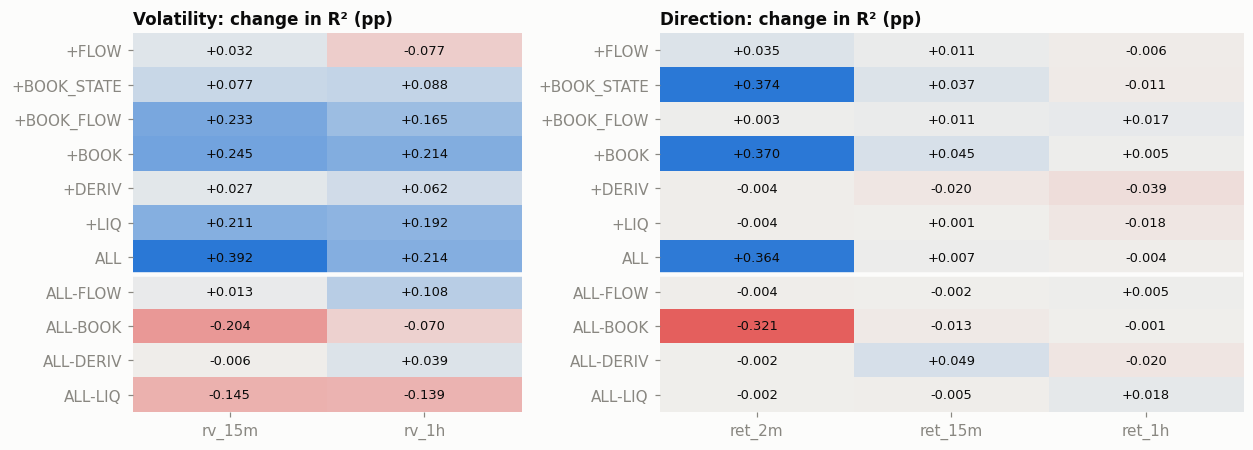

In [26]:
ABL_PLUS = ["+FLOW", "+BOOK_STATE", "+BOOK_FLOW", "+BOOK", "+DERIV", "+LIQ", "ALL"]
ABL_MINUS = ["ALL-FLOW", "ALL-BOOK", "ALL-DERIV", "ALL-LIQ"]
def ablation(Pd, targets):
    res = {}
    for k in targets:
        Pk = aggregate(Pd[k]); y = Pk["y"].to_numpy(np.float64)
        ref = (y - Pk["ybar"].to_numpy(np.float64)) if k in VOL_TARGETS else y
        sst = (ref ** 2).sum()
        e = lambda m: ((y - Pk["ridge_" + m].to_numpy(np.float64)) ** 2).sum()
        res[k] = {**{m: 100 * (e("BASE") - e(m)) / sst for m in ABL_PLUS}, **{m: 100 * (e("ALL") - e(m)) / sst for m in ABL_MINUS}}
    return pd.DataFrame(res)

ABL_VOL, ABL_DIR = ablation(P_DEV, VOL_TARGETS), ablation(P_DEV, DIR_TARGETS)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), width_ratios=[2, 3])
for ax, T_, ttl in [(axes[0], ABL_VOL, "Volatility: change in R² (pp)"), (axes[1], ABL_DIR, "Direction: change in R² (pp)")]:
    lim = float(np.abs(T_.values).max())
    ax.imshow(T_.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(T_.shape[1]), T_.columns); ax.set_yticks(range(T_.shape[0]), T_.index)
    for i in range(T_.shape[0]):
        for j in range(T_.shape[1]):
            ax.text(j, i, f"{T_.values[i, j]:+.3f}", ha="center", va="center", fontsize=8.5, color=INK)
    ax.axhline(len(ABL_PLUS) - 0.5, color=SURFACE, lw=3); ax.grid(False); ax.set_title(ttl)
    for s_ in ax.spines.values(): s_.set_visible(False)
plt.tight_layout(); plt.show()

**Interpretation.**

* **Direction:** only `BOOK_STATE` matters. Removing the book from the full model loses 0.32 pp at 2 minutes, while removing any other block changes almost nothing. Trade flow and OFI have some univariate IC, but it is absorbed by top-of-book imbalance.
* **Volatility:** `BOOK_FLOW` and `LIQ` carry what a linear model can use, and `FLOW` adds nothing. `DERIV` has very wide intervals in the table above, largely because `rel_turnover_oi_15m` is almost a copy of `rel_notional_15m` (correlation 0.997 on development data), so their coefficients trade off against each other.

### Which features does the full model lean on, and do their signs hold?

A coefficient that flips sign between refits suggests the model is fitting noise. Here I take the Ridge coefficients from each monthly refit, keep the largest by mean absolute size, and show how consistent their sign is.

In [27]:
def coef_table(k, top=10):
    B_ = pd.DataFrame({fold: CTX["betas"][(k, fold)] for fold in DEV_FOLDS})
    t_ = pd.DataFrame({"block": [BLOCK.get(c, "BASE") for c in B_.index], "mean_coef": B_.mean(axis=1).values, "sign_consistency": (np.sign(B_).eq(np.sign(B_.mean(axis=1)), axis=0)).mean(axis=1).values}, index=B_.index)
    return t_.assign(a=t_.mean_coef.abs()).sort_values("a", ascending=False).head(top).drop(columns="a")
display(coef_table("ret_2m").round(4)); display(coef_table("rv_15m").round(4))

,block,mean_coef,sign_consistency
qi_1bps,BOOK_STATE,0.0158,1.0
qi_1,BOOK_STATE,0.0158,1.0
qi_top5,BOOK_STATE,0.0146,1.0
weighted_mid_offset_bps,BOOK_STATE,0.0114,1.0
tw_qi_1_30s,BOOK_STATE,0.0092,1.0
cost_skew_1m_usdt,BOOK_STATE,0.0065,1.0
rel_tw_spread_2m,BOOK_STATE,0.0053,1.0
basis_mark_index_bps,DERIV,-0.0050,1.0
basis_mark_index_change_1h_bps,DERIV,-0.0049,1.0
qi_5bps,BOOK_STATE,0.0041,1.0


,block,mean_coef,sign_consistency
rel_notional_15m,BASE,-0.6890,1.00
lrv_15m,BASE,0.3701,1.00
rel_turnover_oi_15m,DERIV,0.3557,0.75
slot_prior_rv_15m,BASE,0.2193,1.00
l_slot_notional_15m,BASE,0.1846,1.00
lrv_4h_bars,BASE,0.1745,1.00
lrv_1h_bars,BASE,0.1728,1.00
rel_level_changes_2m,BOOK_FLOW,0.1277,1.00
rel_trades_15m,BASE,0.1242,1.00
rel_notional_1bar,BASE,0.1006,1.00


## 9. Controls and sensitivity checks `EXPLORATORY`

A result only means something if the same pipeline fails when it should fail. Each check below re-runs the Ridge walk-forward with a single change.

| Check | Change | What a healthy result looks like |
|---|---|---|
| **Placebo** | Target taken from 7 days and 13 minutes later, so it has no real link to the features | R² and IC near zero. Anything else means leakage or a flawed metric. |
| **Stale features** | All features delayed by one extra bar | Shows how much of the result depends on the freshest minute |
| **Mid-to-mid target** | Direction measured between mids rather than last trades | Close to the main result |
| **Delayed volatility target** | Forward RV starts one minute later | Removes the 1-second overlap of section 4.6. The gain should barely move. |
| **Crash in training** | Crash rows kept in training (test months after the crash) | Shows whether excluding the crash was consequential |
| **Unscaled returns** | The same forecasts converted to raw returns, plus a refit on raw bps | Shows how much the direction result depends on volatility scaling |

In [28]:
SMALL = {"BASE": CONFIGS["BASE"], "ALL": CONFIGS["ALL"]}
ctrl_rows = []
def add_dir(label, Pd, k):
    s_ = score_direction(aggregate(Pd), "ridge_ALL", "ridge_BASE")
    ctrl_rows.append(dict(check=label, target=k, metric="R² ALL (%)", value=s_["r2_pct"], lo=s_["r2_lo"], hi=s_["r2_hi"], gain_vs_base=s_["d_r2_pct"], ic=s_["ic"], ic_t=s_["ic_t"], stat_t=s_["cw_t"]))
def add_vol(label, Pd, k):
    s_ = score_vol(aggregate(Pd), "ridge_ALL", "ridge_BASE")
    ctrl_rows.append(dict(check=label, target=k, metric="R² ALL (%)", value=s_["r2_pct"], gain_vs_base=s_["d_r2_pct"], qlike_gain_pct=s_["qlike_gain_pct"], stat_t=s_["dm_t_qlike"]))

for k in ["ret_2m", "ret_15m", "ret_1h"]:
    add_dir("Main result", P_DEV[k], k)
for k in VOL_TARGETS:
    add_vol("Main result", P_DEV[k], k)

# Placebo: extra purge, because the shifted target looks seven days ahead.
SHIFT = 7 * 1440 + 13
y_placebo = {k: Y["z_" + k].shift(-SHIFT) for k in ["ret_2m", "ret_15m"]}
Pp, _ = run_walk_forward(CTX, DEV_FOLDS, ["ret_2m", "ret_15m"], configs=SMALL, lgb_configs=(), y_override=y_placebo, extra_purge=pd.Timedelta(days=7, minutes=13))
for k in Pp: add_dir("Placebo (target from 7 days later)", with_days(Pp[k]), k)

# Features delayed by one bar.
X_lag = pd.DataFrame(CTX["X"], index=X.index, columns=CTX["feats"]).shift(1).to_numpy(np.float32)
Pl, _ = run_walk_forward(CTX, DEV_FOLDS, ["ret_2m", "ret_15m", "rv_15m"], configs=SMALL, lgb_configs=(), X_override=X_lag)
for k in ["ret_2m", "ret_15m"]: add_dir("Features one bar stale", with_days(Pl[k]), k)
add_vol("Features one bar stale", with_days(Pl["rv_15m"]), "rv_15m")
del X_lag

# Mid-to-mid direction target.
lmid = np.log(bars["mid"])
y_mid = {k: ((lmid.shift(-HORIZONS[k]) - lmid) / (SIG * np.sqrt(HORIZONS[k]))).clip(-10, 10) for k in ["ret_2m", "ret_15m"]}
Pm, _ = run_walk_forward(CTX, DEV_FOLDS, ["ret_2m", "ret_15m"], configs=SMALL, lgb_configs=(), y_override=y_mid)
for k in Pm: add_dir("Mid-to-mid target", with_days(Pm[k]), k)

# Forward RV starting one bar later, removing any overlap with the last second before T.
y_delay = {k: Y["l_" + k].shift(-1) for k in VOL_TARGETS}
Pv, _ = run_walk_forward(CTX, DEV_FOLDS, VOL_TARGETS, configs=SMALL, lgb_configs=(), y_override=y_delay)
for k in Pv: add_vol("Volatility target starts 1 min later", with_days(Pv[k]), k)

# Crash kept in training. Compared with the main run over the same post-crash test months.
post = DEV_FOLDS[1:]
Pc, _ = run_walk_forward(CTX, post, list(HORIZONS), configs=SMALL, lgb_configs=(), include_crash=True)
for k in DIR_TARGETS:
    add_dir("Post-crash months, crash excluded from training", P_DEV[k][P_DEV[k]["fold"].isin(post)], k); add_dir("Post-crash months, crash in training", with_days(Pc[k]), k)
for k in VOL_TARGETS:
    add_vol("Post-crash months, crash excluded from training", P_DEV[k][P_DEV[k]["fold"].isin(post)], k); add_vol("Post-crash months, crash in training", with_days(Pc[k]), k)

# Unscaled returns: same forecasts, converted to raw return units. No refit is needed.
for k in DIR_TARGETS:
    P_ = aggregate(P_DEV[k]); r_ = P_["row"].to_numpy(); sc = SIG.to_numpy()[r_] * np.sqrt(HORIZONS[k])
    y_raw = Y[k].to_numpy()[r_]
    e0, e1 = (y_raw - P_["ridge_BASE"].to_numpy(np.float64) * sc) ** 2, (y_raw - P_["ridge_ALL"].to_numpy(np.float64) * sc) ** 2
    ctrl_rows.append(dict(check="Unscaled returns (forecasts rescaled)", target=k, metric="R² ALL (%)", value=100 * (1 - e1.sum() / (y_raw ** 2).sum()), gain_vs_base=100 * (e0.sum() - e1.sum()) / (y_raw ** 2).sum()))

# Refit directly on raw bps. If R² recovers, the problem above is the scaling of the forecast and not the absence of a signal.
y_raw_bps = {k: Y[k] * 1e4 for k in DIR_TARGETS}
Pr, _ = run_walk_forward(CTX, DEV_FOLDS, DIR_TARGETS, configs=SMALL, lgb_configs=(), y_override=y_raw_bps)
for k in DIR_TARGETS: add_dir("Refit on raw bps returns", with_days(Pr[k]), k)

CTRL = pd.DataFrame(ctrl_rows)
CTRL.drop(columns="metric").set_index(["check", "target"]).round(4)

value      lo      hi  gain_vs_base      ic     ic_t   stat_t  qlike_gain_pct
check                                           target                                                                                  
Main result                                     ret_2m    0.3593  0.2457  0.4688        0.3639  0.0603  12.0594  12.6571             NaN
                                                ret_15m  -0.0085 -0.0912  0.0680        0.0072  0.0128   2.1758   2.1410             NaN
                                                ret_1h   -0.0090 -0.2156  0.1893       -0.0041  0.0203   1.7638   1.0567             NaN
                                                rv_15m   81.7405     NaN     NaN        0.3918     NaN      NaN   1.4863          1.4694
                                                rv_1h    79.6594     NaN     NaN        0.2140     NaN      NaN   0.7208          1.3369
Placebo (target from 7 days later)              ret_2m   -0.0024 -0.0108  0.0054       -0.0039  0.0025   0.9015   0.0755             NaN
                                                ret_15m  -0.0501 -0.1245  0.0089       -0.0510 -0.0002  -0.0365  -0.1477             NaN
Features one bar stale                          ret_2m    0.0067 -0.0066  0.0193        0.0080  0.0084   3.4044   3.2712             NaN
                                                ret_15m  -0.0022 -0.0474  0.0367        0.0043  0.0075   1.2490   0.8623             NaN
                                                rv_15m   80.8790     NaN     NaN        0.3037     NaN      NaN   1.0748          0.9661
Mid-to-mid target                               ret_2m    0.3703  0.2531  0.4836        0.3733  0.0619  12.5859  13.1892             NaN
                                                ret_15m  -0.0028 -0.0902  0.0787        0.0100  0.0142   2.3882   2.2597             NaN
Volatility target starts 1 min later            rv_15m   80.9384     NaN     NaN        0.3756     NaN      NaN   1.3378          1.3180
                                                rv_1h    79.3146     NaN     NaN        0.2119     NaN      NaN   0.7107          1.3148
Post-crash months, crash excluded from training ret_2m    0.3433  0.2245  0.4684        0.3523  0.0581  12.9819  13.1677             NaN
Post-crash months, crash in training            ret_2m    0.3468  0.2279  0.4707        0.3550  0.0583  13.0267  13.1866             NaN
Post-crash months, crash excluded from training ret_15m   0.0278 -0.0357  0.0889        0.0472  0.0165   2.6091   2.7260             NaN
Post-crash months, crash in training            ret_15m   0.0301 -0.0324  0.0914        0.0462  0.0170   2.6506   2.5828             NaN
Post-crash months, crash excluded from training ret_1h   -0.0107 -0.2600  0.2034       -0.0048  0.0216   1.7697   1.0580             NaN
Post-crash months, crash in training            ret_1h   -0.0212 -0.2946  0.2147       -0.0064  0.0219   1.7446   1.0852             NaN
Post-crash months, crash excluded from training rv_15m   82.7099     NaN     NaN        0.5984     NaN      NaN   2.4009          2.4437
Post-crash months, crash in training            rv_15m   82.6751     NaN     NaN        0.5847     NaN      NaN   2.5646          2.4795
Post-crash months, crash excluded from training rv_1h    81.5152     NaN     NaN        0.5998     NaN      NaN   2.1407          3.5526
Post-crash months, crash in training            rv_1h    81.5976     NaN     NaN        0.6200     NaN      NaN   2.2202          3.6073
Unscaled returns (forecasts rescaled)           ret_2m   -0.0977     NaN     NaN       -0.0968     NaN      NaN      NaN             NaN
                                                ret_15m  -0.0719     NaN     NaN       -0.0366     NaN      NaN      NaN             NaN
                                                ret_1h   -0.0962     NaN     NaN       -0.0201     NaN      NaN      NaN             NaN
Refit on raw bps returns                        ret_2m    0.2293  0.1651  0.3055      

**Interpretation.**

* **Placebo: passed.** With a target that has no real link to the features, R² is about zero with an interval spanning zero, and the IC t-statistic is below 1. The pipeline does not manufacture signal.
* **Stale features: decisive for direction.** One extra minute of staleness takes 2-minute R² from 0.36% to 0.01%, a loss of about 98%, while the volatility gain barely changes. Direction information is fast and volatility information is slow.
* **Mid-to-mid target:** results match the main run, so last-trade staleness is not the source.
* **Delayed volatility target:** the gain moves from 0.39 to 0.38 pp, so the 1-second overlap identified in section 4.6 is not a concern.
* **Crash in training:** almost no effect on the post-crash months, so excluding it was not a consequential choice.
* **Unscaled returns: an important caveat.** Converting the forecasts back to raw returns makes 2-minute R² *negative* (−0.10%). A refit directly on raw bps gives +0.23%, with an interval that excludes zero. So the signal survives, and the problem lies in how a volatility-scaled forecast maps back to bps. Section 10.3 explains the mechanism. The headline 2-minute R² depends on the scale of the target, so it should always be quoted with that scale.

Note also that the post-crash rows show a stronger Ridge volatility gain (Diebold–Mariano t around 2.1–2.4) than the full development sample. Most of the difference comes from October 2025, when the larger model had only ten weeks of training data.

## 10. Does the evidence persist? `EXPLORATORY`

An aggregate score can hide a result that came from one month or one market state. This section looks at each test month separately, then across market conditions defined **only from information available at the time**.

### 10.1 Month by month

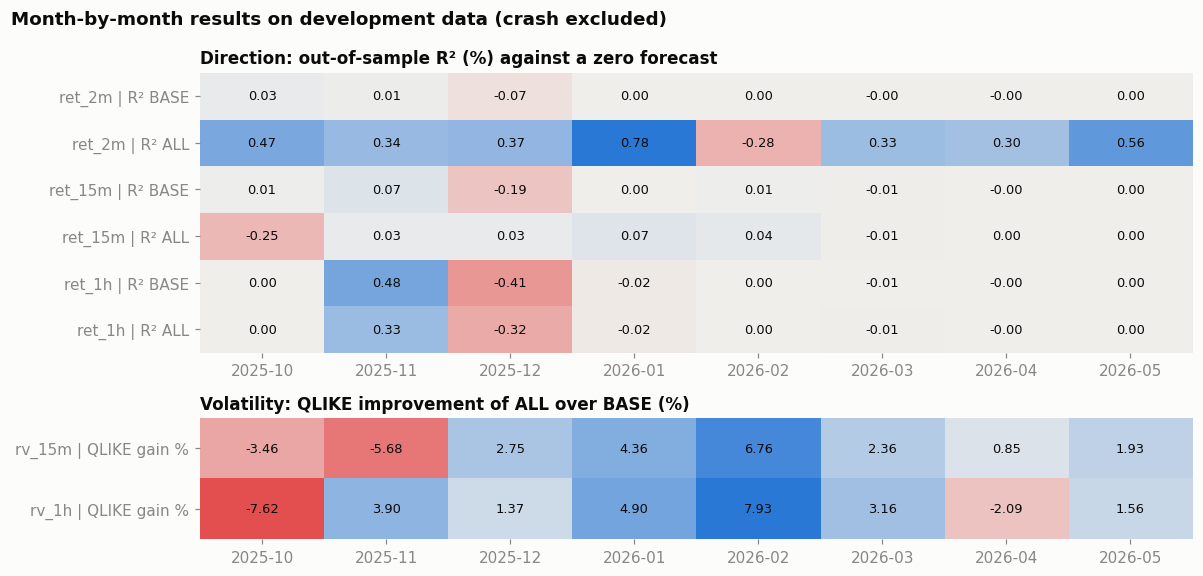

In [29]:
def monthly_table(Pd):
    res = {}
    for k in DIR_TARGETS:
        P_ = aggregate(Pd[k]); y = P_["y"].to_numpy(np.float64)
        for m, lab in [("ridge_BASE", "BASE"), ("ridge_ALL", "ALL")]:
            f = P_[m].to_numpy(np.float64)
            res[(k, f"R² {lab}")] = pd.DataFrame({"mo": P_["month"].to_numpy(), "n": y ** 2 - (y - f) ** 2, "d": y ** 2}).groupby("mo").sum().eval("100 * n / d")
    D = pd.DataFrame(res).T
    res = {}
    for k in VOL_TARGETS:
        P_ = aggregate(Pd[k]); y = P_["y"].to_numpy(np.float64)
        q0, q1 = qlike(y, P_["ridge_BASE|lvl"].to_numpy(np.float64)), qlike(y, P_["ridge_ALL|lvl"].to_numpy(np.float64))
        g_ = pd.DataFrame({"mo": P_["month"].to_numpy(), "q0": q0, "q1": q1}).groupby("mo").mean()
        res[(k, "QLIKE gain %")] = 100 * (1 - g_["q1"] / g_["q0"])
    return D, pd.DataFrame(res).T

def monthly_plot(D, V, title):
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.3), height_ratios=[len(D), len(V) + 0.6])
    for ax, T_, ttl in [(axes[0], D, "Direction: out-of-sample R² (%) against a zero forecast"), (axes[1], V, "Volatility: QLIKE improvement of ALL over BASE (%)")]:
        lim = float(np.nanmax(np.abs(T_.values)))
        ax.imshow(T_.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
        ax.set_xticks(range(T_.shape[1]), T_.columns); ax.set_yticks(range(T_.shape[0]), [f"{a} | {b}" for a, b in T_.index])
        for i in range(T_.shape[0]):
            for j in range(T_.shape[1]):
                ax.text(j, i, f"{T_.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5, color=INK)
        ax.grid(False); ax.set_title(ttl)
        for s_ in ax.spines.values(): s_.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="semibold"); plt.tight_layout(); plt.show()

MD_DEV, MV_DEV = monthly_table(P_DEV)
monthly_plot(MD_DEV, MV_DEV, "Month-by-month results on development data (crash excluded)")

**Interpretation.**

* **2-minute direction:** `ALL` is positive in 7 of 8 months. `BASE` stays near zero throughout, which shows the signal comes from the added features. February 2026, the most volatile month in development, is the exception at −0.28%, even though its IC is positive. Section 10.3 explains why.
* **15 minutes and 1 hour:** values hover around zero. Exact zeros in the later months occur because the inner validation chose a very large Ridge penalty, which is the model correctly reporting that it found nothing. The ±0.3–0.5% swings in November and December at 1 hour are of mixed sign in `BASE` and `ALL` alike, and do not suggest skill.
* **Volatility (Ridge `ALL` over `BASE`):** negative in the first folds, then mostly positive. This fits the idea that a larger model needs more training data, but it could equally reflect the market regime, and eight months cannot separate the two.

### 10.2 Market conditions

Each row of the panel gets a label at decision time:

* **Volatility regime:** where the trailing 24h volatility sits within its own trailing 30-day distribution (terciles).
* **Trend:** past 24h return in units of trailing volatility, above +1 or below −1.
* **Session:** Asia 00–08, Europe 08–13, US 13–21, late 21–24 UTC.
* **Weekend** versus weekday.
* **Book provenance:** anchored (state 0) or rebuilt (state 9).
* **Liquidity:** book depth within 10 bps, above or below its trailing 7-day mean.

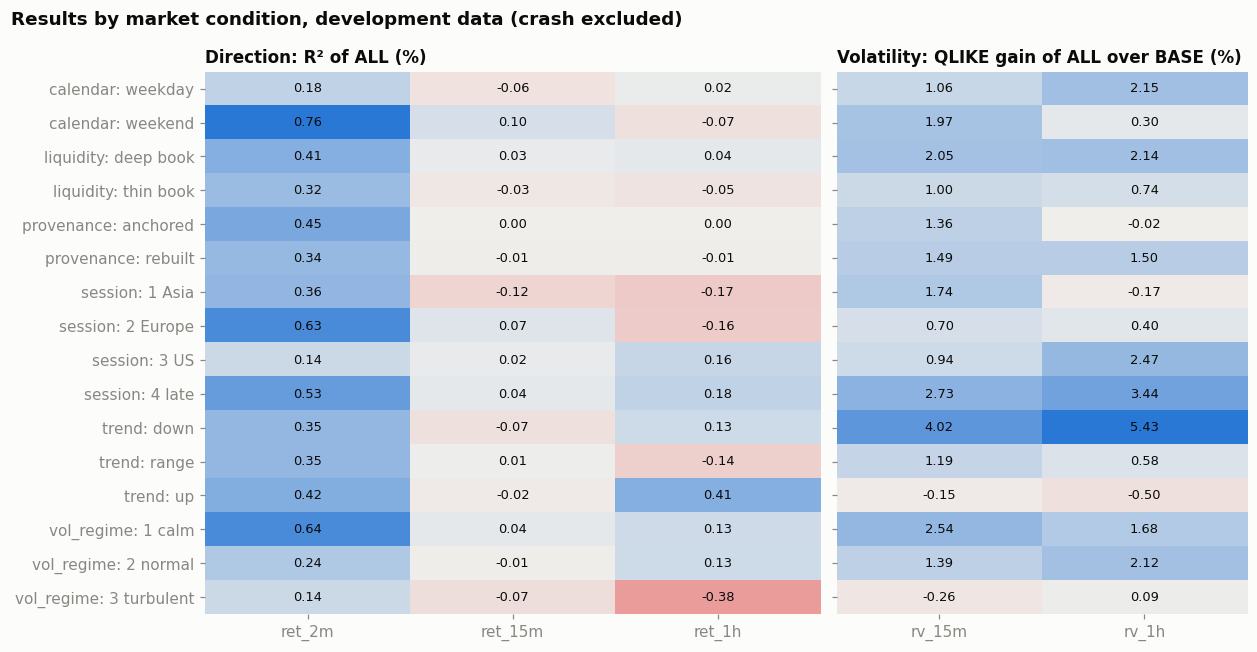

target                         ret_2m        ret_15m         ret_1h          rv_15m           rv_1h
condition  level                                                                                   
calendar   weekday       [0.08, 0.28]  [-0.17, 0.05]  [-0.30, 0.33]   [-1.13, 3.67]   [-1.71, 6.49]
           weekend       [0.51, 1.00]  [-0.02, 0.24]  [-0.41, 0.19]   [-0.32, 4.19]   [-3.22, 3.89]
liquidity  deep book     [0.26, 0.56]  [-0.07, 0.12]  [-0.22, 0.26]    [0.24, 3.95]    [0.08, 4.39]
           thin book     [0.20, 0.45]  [-0.13, 0.06]  [-0.33, 0.21]   [-1.05, 3.35]   [-3.22, 5.22]
provenance anchored      [0.31, 0.59]   [0.00, 0.01]  [-0.00, 0.01]   [-0.61, 3.31]   [-5.00, 3.38]
           rebuilt       [0.21, 0.48]  [-0.11, 0.07]  [-0.29, 0.23]   [-0.56, 3.55]   [-1.92, 5.06]
session    1 Asia        [0.19, 0.52]  [-0.30, 0.03]  [-0.50, 0.11]   [-0.24, 3.93]   [-3.22, 3.37]
           2 Europe      [0.49, 0.76]  [-0.05, 0.20]  [-0.66, 0.25]   [-0.76, 2.09]   [-2.06, 3.19]
           3 US          [0.00, 0.29]  [-0.10, 0.14]  [-0.31, 0.67]   [-1.65, 3.63]   [-1.46, 6.75]
           4 late        [0.32, 0.75]  [-0.16, 0.25]  [-0.10, 0.59]   [-0.61, 6.16]   [-2.37, 8.93]
trend      down          [0.14, 0.58]  [-0.35, 0.17]  [-0.13, 0.47]  [-0.94, 10.28]  [-2.31, 14.67]
           range         [0.23, 0.47]  [-0.06, 0.08]  [-0.40, 0.08]   [-0.49, 2.71]   [-1.96, 2.97]
           up            [0.21, 0.65]  [-0.25, 0.22]  [-0.30, 1.25]   [-2.51, 2.04]   [-4.68, 2.84]
vol_regime 1 calm        [0.51, 0.78]  [-0.05, 0.12]  [-0.12, 0.38]    [1.22, 3.78]   [-0.06, 3.73]
           2 normal      [0.10, 0.39]  [-0.18, 0.11]  [-0.12, 0.46]   [-0.73, 3.66]    [0.15, 4.29]
           3 turbulent  [-0.04, 0.34]  [-0.31, 0.11]  [-1.14, 0.14]   [-5.23, 5.69]   [-8.65, 9.47]

In [30]:
# Causal labels: the 30-day rank uses hourly samples up to t, forward-filled to minutes.
hourly = X["lrv_24h_bars"].astype(float).iloc[59::60]
rank30 = hourly.rolling(720, min_periods=240).rank(pct=True).reindex(X.index, method="ffill")
hr = bars.index.hour
COND = pd.DataFrame({
    "vol_regime": pd.cut(rank30, [0, 1/3, 2/3, 1.0], labels=["1 calm", "2 normal", "3 turbulent"]).astype(object),
    "trend": np.select([X["z_ret_24h"] > 1, X["z_ret_24h"] < -1], ["up", "down"], "range"),
    "session": np.select([hr < 8, hr < 13, hr < 21], ["1 Asia", "2 Europe", "3 US"], "4 late"),
    "calendar": np.where(bars["is_weekend"] == 1, "weekend", "weekday"),
    "provenance": bars["book_state"].map({0: "anchored", 9: "rebuilt"}),
    "liquidity": np.where(X["rel_depth_10bps"] < 0, "thin book", "deep book")}, index=bars.index)

def condition_table(Pd, min_rows=2000):
    rows = []
    for k in list(HORIZONS):
        P_ = aggregate(Pd[k]); r_ = P_["row"].to_numpy()
        y = P_["y"].to_numpy(np.float64); f0, f1 = P_["ridge_BASE"].to_numpy(np.float64), P_["ridge_ALL"].to_numpy(np.float64)
        for c in COND.columns:
            lab = COND[c].to_numpy()[r_]
            for level in sorted(set(x for x in lab if isinstance(x, str))):
                m = lab == level
                if m.sum() < min_rows:
                    continue
                g_ = P_["day"].to_numpy()[m]
                if k in VOL_TARGETS:
                    q0, q1 = qlike(y[m], P_["ridge_BASE|lvl"].to_numpy(np.float64)[m]), qlike(y[m], P_["ridge_ALL|lvl"].to_numpy(np.float64)[m])
                    num, den = pd.Series(q0 - q1).groupby(g_).sum().to_numpy(), pd.Series(q0).groupby(g_).sum().to_numpy()
                else:
                    num, den = pd.Series(y[m] ** 2 - (y[m] - f1[m]) ** 2).groupby(g_).sum().to_numpy(), pd.Series(y[m] ** 2).groupby(g_).sum().to_numpy()
                lo, hi = block_boot(num, den, reps=1000)
                rows.append(dict(target=k, condition=c, level=level, rows=int(m.sum()), value=100 * num.sum() / den.sum(), lo=100 * lo, hi=100 * hi))
    return pd.DataFrame(rows)

def condition_plot(T_, title):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 6), width_ratios=[3, 2], sharey=True)
    for ax, targets, ttl in [(axes[0], DIR_TARGETS, "Direction: R² of ALL (%)"), (axes[1], VOL_TARGETS, "Volatility: QLIKE gain of ALL over BASE (%)")]:
        pv = T_[T_.target.isin(targets)].pivot(index=["condition", "level"], columns="target", values="value")[targets]
        lim = float(np.nanmax(np.abs(pv.values)))
        ax.imshow(pv.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
        ax.set_xticks(range(len(targets)), targets); ax.set_yticks(range(len(pv)), [f"{a}: {b}" for a, b in pv.index])
        for i in range(pv.shape[0]):
            for j in range(pv.shape[1]):
                if np.isfinite(pv.values[i, j]):
                    ax.text(j, i, f"{pv.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5, color=INK)
        ax.grid(False); ax.set_title(ttl)
        for s_ in ax.spines.values(): s_.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="semibold"); plt.tight_layout(); plt.show()

CT_DEV = condition_table(P_DEV)
condition_plot(CT_DEV, "Results by market condition, development data (crash excluded)")
CT_DEV.assign(ci=lambda d: d.apply(lambda r: f"[{r.lo:.2f}, {r.hi:.2f}]", axis=1)).pivot(index=["condition", "level"], columns="target", values="ci")[list(HORIZONS)]

**Interpretation.** Cell values are point estimates, and the table gives their day-block 95% intervals.

* **The 2-minute signal is broad.** It is positive in every condition, and its interval excludes zero in all of them except turbulent markets, with the US session right at the edge. It is stronger in calm markets (0.64%) than in turbulent ones (0.14%), and stronger at weekends than on weekdays.
* **Provenance is not driving it.** Anchored rows (0.45%) and rebuilt rows (0.34%) have overlapping intervals. This is useful evidence on the certificate-based book reconstruction, at least for this signal.
* **15 minutes and 1 hour:** intervals include zero in nearly every condition.
* **Volatility gains look concentrated in falling markets**, at 4.0% and 5.4% for Ridge, but those intervals are very wide and include zero. Treat this as a lead to investigate, and not a finding. The gain is near zero in turbulent conditions, which is where better volatility forecasts would be most valuable.

With 16 condition levels and 5 targets, a few cells will look notable by chance.

### 10.3 Why the 2-minute signal weakens when volatility rises

R² at 2 minutes falls from calm to turbulent conditions, and February 2026 is negative even though the IC stays positive. A likely explanation is that the imbalance effect has a **fixed size in bps** and does not scale with volatility. If so, a forecast expressed in volatility units will overshoot when volatility is high. That can be tested without any model, by regressing the raw 2-minute return on `qi_1` within volatility buckets and within months.

In [31]:
def qi_slope_tables(rows_mask):
    # Slope of the raw forward 2-minute return (bps) on qi_1. No fitted model, no scaling, no feature selection.
    d_ = pd.DataFrame({"y": Y["ret_2m"] * 1e4, "q": bars["qi_1"], "sig": SIG * 1e4, "mo": MONTH})[rows_mask].dropna()
    slope = lambda g: np.polyfit(g["q"], g["y"], 1)[0]
    d_["bucket"] = pd.qcut(d_["sig"], 5, labels=["1 calm", "2", "3", "4", "5 turbulent"])
    by_vol = d_.groupby("bucket", observed=True).apply(lambda g: pd.Series({"median_vol_bps_per_min": g["sig"].median(), "slope_bps": slope(g), "slope_in_vol_units": slope(g) / g["sig"].median(), "corr": g["q"].corr(g["y"])}), include_groups=False)
    by_month = d_.groupby("mo").apply(lambda g: pd.Series({"median_vol_bps_per_min": g["sig"].median(), "slope_bps": slope(g), "corr": g["q"].corr(g["y"]), "rows": len(g)}), include_groups=False)
    return by_vol, by_month, d_

dev_test_rows = ELIGIBLE & IN_DEV & ~IN_CRASH & MONTH.isin(DEV_FOLDS)
QI_VOL_DEV, QI_MONTH_DEV, _ = qi_slope_tables(dev_test_rows)
display(QI_VOL_DEV.round(3)); QI_MONTH_DEV.round(3)

,median_vol_bps_per_min,slope_bps,slope_in_vol_units,corr
bucket,,,,
1 calm,2.677,0.695,0.259,0.098
2,3.941,0.717,0.182,0.071
3,5.176,0.758,0.146,0.059
4,6.749,0.685,0.101,0.043
5 turbulent,9.785,0.658,0.067,0.029


,median_vol_bps_per_min,slope_bps,corr,rows
mo,,,,
2025-10,4.741,0.802,0.064,37236.0
2025-11,5.849,0.835,0.055,39869.0
2025-12,4.934,0.644,0.046,42537.0
2026-01,3.966,0.720,0.057,42105.0
2026-02,7.325,0.593,0.027,38776.0
2026-03,6.239,0.832,0.051,36027.0
2026-04,4.621,0.551,0.044,28141.0
2026-05,3.570,0.589,0.064,31456.0


**Result.** The slope in bps is nearly flat across a more than threefold range of volatility, while the same effect measured in volatility units falls by about a factor of four. That explains both the calm-versus-turbulent pattern and February 2026: the effect is still there, but the forecast in volatility units is too large for the month. A simple law emerges from the development data: **a fully imbalanced top of book is followed by a move of about 0.7 bps, in any market condition seen so far.**

Because this needs no fitted model, it makes a sharp prediction for the holdout, recorded in section 14.

## 11. The October 2025 crash as a stress episode `EXPLORATORY`

The crash sits in the first test fold, with the model trained only on July to September 2025. It is out of all aggregates above, and is examined here on its own terms. Because only one such event exists in the sample, everything in this section is a case study and not a statistical estimate.

Three phases are used: **before** (from 9 October to 20:45 on 10 October), **acute** (20:45 to 23:30), and **after** (to the end of 11 October).

In [32]:
PHASES = {"before": (CRASH_START, ACUTE_START), "acute": (ACUTE_START, ACUTE_END), "after": (ACUTE_END, CRASH_END)}

# Secondary volatility target from one-minute closes. It exists through the acute phase, unlike the strict 1 s grid RV.
r2_bar = R1 ** 2
SEC = {"rv_15m": r2_bar.rolling(15, min_periods=12).sum().shift(-15), "rv_1h": r2_bar.rolling(60, min_periods=48).sum().shift(-60)}

rows = []
for ph, (a_, b_) in PHASES.items():
    m = (t_idx >= a_) & (t_idx < b_)
    rows.append(dict(phase=ph, bars=int(m.sum()), eligible=int((ELIGIBLE & m).sum()), eligible_pct=100 * (ELIGIBLE & m).sum() / m.sum(),
                     ret_15m_target=int(Y.loc[m, "ret_15m"].notna().sum()), rv_15m_target=int(Y.loc[m, "rv_15m"].notna().sum()), secondary_rv_15m=int(SEC["rv_15m"][m].notna().sum()),
                     in_evaluation=int(((t_idx[P_DEV["rv_15m"]["row"].to_numpy()] >= a_) & (t_idx[P_DEV["rv_15m"]["row"].to_numpy()] < b_)).sum())))
crash_cov = pd.DataFrame(rows).set_index("phase").round(1)
display(crash_cov)

rows = []
for k in list(HORIZONS):
    P_ = P_DEV[k]; ts = t_idx[P_["row"].to_numpy()]
    for ph, (a_, b_) in list(PHASES.items()) + [("normal days, Oct 2025", (pd.Timestamp("2025-10-01", tz=UTC), pd.Timestamp("2025-11-01", tz=UTC)))]:
        m = (ts >= a_) & (ts < b_)
        if ph.startswith("normal"):
            m &= ~P_["crash"].to_numpy()
        S = P_[m]
        if len(S) < 30:
            rows.append(dict(target=k, phase=ph, rows=len(S))); continue
        y = S["y"].to_numpy(np.float64)
        if k in VOL_TARGETS:
            q0, q1 = qlike(y, S["ridge_BASE|lvl"].to_numpy(np.float64)), qlike(y, S["ridge_ALL|lvl"].to_numpy(np.float64))
            rows.append(dict(target=k, phase=ph, rows=len(S), mean_error_log=float(np.mean(y - S["ridge_ALL"].to_numpy(np.float64))), rmse_base=float(np.sqrt(np.mean((y - S["ridge_BASE"]) ** 2))),
                             rmse_all=float(np.sqrt(np.mean((y - S["ridge_ALL"]) ** 2))), qlike_base=float(q0.mean()), qlike_all=float(q1.mean())))
        else:
            f0, f1 = S["ridge_BASE"].to_numpy(np.float64), S["ridge_ALL"].to_numpy(np.float64)
            rows.append(dict(target=k, phase=ph, rows=len(S), r2_base_pct=100 * (1 - ((y - f0) ** 2).sum() / (y ** 2).sum()), r2_all_pct=100 * (1 - ((y - f1) ** 2).sum() / (y ** 2).sum()),
                             hit_all=float(np.mean(np.sign(f1) == np.sign(y)))))
CRASH_PERF = pd.DataFrame(rows).set_index(["target", "phase"]).round(3)
CRASH_PERF

,bars,eligible,eligible_pct,ret_15m_target,rv_15m_target,secondary_rv_15m,in_evaluation
phase,,,,,,,
before,2685,2419,90.1,2666,2466,2685,2290
acute,165,10,6.1,143,19,165,2
after,1470,1281,87.1,1470,1440,1470,1262


rows  r2_base_pct  r2_all_pct  hit_all  mean_error_log  rmse_base  rmse_all  qlike_base  qlike_all
target  phase                                                                                                                     
ret_2m  before                  2416        0.237       0.505    0.526             NaN        NaN       NaN         NaN        NaN
        acute                     10          NaN         NaN      NaN             NaN        NaN       NaN         NaN        NaN
        after                   1281       -0.306      -0.807    0.524             NaN        NaN       NaN         NaN        NaN
        normal days, Oct 2025  37236        0.027       0.470    0.535             NaN        NaN       NaN         NaN        NaN
ret_15m before                  2413        0.235      -0.280    0.506             NaN        NaN       NaN         NaN        NaN
        acute                     10          NaN         NaN      NaN             NaN        NaN       NaN         NaN        NaN
        after                   1281       -0.188      -3.113    0.468             NaN        NaN       NaN         NaN        NaN
        normal days, Oct 2025  37198        0.008      -0.251    0.514             NaN        NaN       NaN         NaN        NaN
ret_1h  before                  2405        0.009       0.010    0.548             NaN        NaN       NaN         NaN        NaN
        acute                     10          NaN         NaN      NaN             NaN        NaN       NaN         NaN        NaN
        after                   1281       -0.005      -0.013    0.450             NaN        NaN       NaN         NaN        NaN
        normal days, Oct 2025  37191        0.001       0.002    0.507             NaN        NaN       NaN         NaN        NaN
rv_15m  before                  2290          NaN         NaN      NaN           0.311      0.526     0.544       0.119      0.124
        acute                      2          NaN         NaN      NaN             NaN        NaN       NaN         NaN        NaN
        after                   1262          NaN         NaN      NaN           0.666      0.845     0.825       0.362      0.329
        normal days, Oct 2025  36153          NaN         NaN      NaN           0.244      0.641     0.657       0.299      0.310
rv_1h   before                  1909          NaN         NaN      NaN           0.380      0.551     0.573       0.139      0.149
        acute                      0          NaN         NaN      NaN             NaN        NaN       NaN         NaN        NaN
        after                   1217          NaN         NaN      NaN           1.031      1.137     1.185       0.911      0.981
        normal days, Oct 2025  33036          NaN         NaN      NaN           0.342      0.681     0.710       0.346      0.372

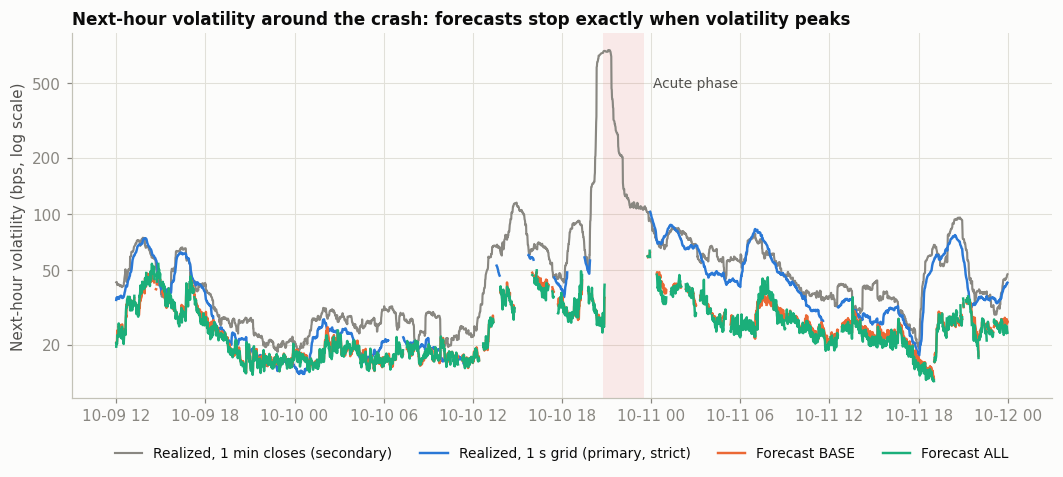

Last forecast before the acute phase, 2025-10-10 20:44 UTC. Next-hour volatility: BASE 25 bps, ALL 23 bps.
Realized over that next hour, from 1 min closes: 727 bps (31.3 times the forecast).
Percentile of that ALL forecast among forecasts from 9 Oct 12:00 to 10 Oct 12:00: 75%


In [33]:
# Forecast every eligible row in the window, including rows whose target is missing. A live system would still have produced
# these forecasts, so the scored sample alone would give a false picture of the last forecast before the crash.
k = "rv_1h"
fold_start = pd.Timestamp("2025-10-01", tz=UTC)
hi = int(np.searchsorted(CTX["tn"], pd.Timestamp("2025-10-12", tz=UTC).value))
tr_mask = CTX["elig"][:hi] & (CTX["tn"][:hi] >= DEV_START.value) & (CTX["tn"][:hi] < (fold_start - CTX["purge"]).value) & ~CTX["crash"][:hi]
Zc = scaler_apply(CTX["X"][:hi], scaler_fit(CTX["X"][:hi][tr_mask]))
yc = Y["l_" + k].to_numpy(np.float64)[:hi]
tr = np.flatnonzero(tr_mask & np.isfinite(yc))
te = np.flatnonzero(CTX["elig"][:hi] & (CTX["tn"][:hi] >= pd.Timestamp("2025-10-09 12:00", tz=UTC).value))
pc, _ = ridge_suite(Zc, yc, tr, te, {m: col_index(CTX, CONFIGS[m], k) for m in ["BASE", "ALL"]}, PURGE_BARS, True)
del Zc
vol = lambda l: np.exp(np.asarray(l, float) / 2) * 1e4
fc = pd.DataFrame({m: vol(pc[m]) for m in pc}, index=t_idx[te])

win = slice(pd.Timestamp("2025-10-09 12:00", tz=UTC), pd.Timestamp("2025-10-11 23:59", tz=UTC))
sec = np.sqrt(SEC["rv_1h"].loc[win]) * 1e4
prim = np.sqrt(Y["rv_1h"].loc[win]) * 1e4
fig, ax = plt.subplots(figsize=(11.5, 4.3))
ax.plot(sec.index, sec, color=MUTED, lw=1.4, label="Realized, 1 min closes (secondary)")
ax.plot(prim.index, prim, color=C["blue"], lw=1.6, label="Realized, 1 s grid (primary, strict)")
for col, color, lab in [("BASE", C["orange"], "Forecast BASE"), ("ALL", C["aqua"], "Forecast ALL")]:
    ax.plot(sec.index, fc[col].reindex(sec.index), color=color, lw=1.6, label=lab)
ax.axvspan(ACUTE_START, ACUTE_END, color=C["red"], alpha=0.10, lw=0)
ax.set_yscale("log"); ax.set_yticks([20, 50, 100, 200, 500], ["20", "50", "100", "200", "500"]); ax.minorticks_off()
ax.annotate("Acute phase", (ACUTE_END, 500), xytext=(6, 0), textcoords="offset points", fontsize=9, color=INK2, va="center")
ax.set(title="Next-hour volatility around the crash: forecasts stop exactly when volatility peaks", ylabel="Next-hour volatility (bps, log scale)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1)); plt.show()

# What was the model saying just before the crash?
pre_t = fc.index[fc.index < ACUTE_START][-1]
norm = fc.index[fc.index < pd.Timestamp("2025-10-10 12:00", tz=UTC)]
print(f"Last forecast before the acute phase, {pre_t:%Y-%m-%d %H:%M} UTC. Next-hour volatility: BASE {fc.loc[pre_t, 'BASE']:.0f} bps, ALL {fc.loc[pre_t, 'ALL']:.0f} bps.")
print(f"Realized over that next hour, from 1 min closes: {sec.loc[pre_t]:.0f} bps ({sec.loc[pre_t] / fc.loc[pre_t, 'ALL']:.1f} times the forecast).")
print(f"Percentile of that ALL forecast among forecasts from 9 Oct 12:00 to 10 Oct 12:00: {(fc.loc[norm, 'ALL'] < fc.loc[pre_t, 'ALL']).mean():.0%}")

**What the stress episode shows.** This is a single event, so these are observations rather than estimates.

* **No usable coverage of the acute phase.** Only 10 of 165 acute bars are eligible, 2 are scored for 15-minute volatility, and none for 1-hour volatility. The question "do microstructure features help during a crash?" cannot be answered here. In the chart, forecasts simply stop.
* **No warning.** The last forecast before the acute phase, at 20:44 UTC, called for about 23–25 bps of next-hour volatility, an unremarkable level. Volatility over the next hour, measured from 1-minute closes, was about 727 bps, roughly 31 times the forecast, and the forecast itself sat only around the 75th percentile of the previous day. Neither the baseline nor the microstructure model anticipated it.
* **Underprediction around the event.** The mean log error is positive before and especially after the crash, because the model had seen only the calmer months of July to September 2025.
* **Direction degraded in the aftermath.** 2-minute R² for `ALL` is about −0.8% in the after phase, compared with about +0.5% on normal October days, although with only 1,281 rows.

Excluding the crash from the aggregates did not hide a success or a failure: there is almost nothing there to score. The more important lesson is about data. **The moments most relevant to risk are the ones this pipeline cannot observe.**

## 12. Is the conclusion an artefact of the clock? `EXPLORATORY`

Everything so far uses clock time. Activity-based bars sample more often when the market is busy, and often show better statistical behaviour. As a robustness check, I re-run the Ridge comparison on `dollar_adapt60s` over development data only. Horizons are now in bars, about 120 per hour on average, so 30 bars is around 15 minutes and 120 bars around 1 hour. Forward volatility is the sum of squared bar returns.

This is not a head-to-head contest. The samples, horizons, and baseline differ (no seasonal prior here), so only the *qualitative* pattern is comparable.

In [34]:
ev = load_bars("dollar_adapt60s")
ev = ev[ev.index < HOLDOUT_START]                     # development rows only
per_hour = int(round(len(ev) / ((ev.index[-1] - ev.index[0]).total_seconds() / 3600)))
XE, SIGE, R1E, PXE = build_features(ev, per_hour=per_hour)
lpe = np.log(PXE)
YE = pd.DataFrame(index=ev.index)
EV_H = {"ev_ret_30": 30, "ev_ret_120": 120, "ev_rv_30": 30, "ev_rv_120": 120}
for k, h in EV_H.items():
    if "ret" in k:
        YE[k] = ((lpe.shift(-h) - lpe) / (SIGE * np.sqrt(h))).clip(-10, 10)
    else:
        YE[k] = np.log((R1E ** 2).rolling(h, min_periods=h).sum().shift(-h).where(lambda s: s > 0))

te_ = ev.index
ELIG_E = (ev["book_state"].isin([0, 9]) & ev["tfi_ratio_15m"].notna() & ev["ofi_norm_2m"].notna() & ev["basis_mark_index_bps"].notna()
          & ev["oi_log_change_known_1h"].notna() & ev["log1p_liq_notional_15m"].notna() & XE["lrv_24h_bars"].notna() & SIGE.notna() & XE["rel_notional_15m"].notna())
ELIG_E &= ~incident_rows(ev["t_start_ns"].to_numpy() - 15 * 60 * 10**9, ev["eval_time_ns"].to_numpy() + 6 * 3600 * 10**9, man["quality_incidents"])
CRASH_E = (te_ >= CRASH_START - pd.Timedelta(hours=6)) & (te_ < CRASH_END)
CTX_E = make_ctx(XE, YE, ELIG_E, CRASH_E, {k: k for k in EV_H}, ["ev_rv_30", "ev_rv_120"], pd.Timedelta(hours=6))
CTX_E.update(per_minute=False, purge_rows=240)
P_EV, _ = run_walk_forward(CTX_E, DEV_FOLDS, list(EV_H), configs=SMALL, lgb_configs=())
P_EV = {k: with_days(v, CTX_E) for k, v in P_EV.items()}

rows = []
pairs = [("ret_15m", "ev_ret_30"), ("ret_1h", "ev_ret_120"), ("rv_15m", "ev_rv_30"), ("rv_1h", "ev_rv_120")]
for a_, b_ in pairs:
    for lab, Pk, k in [("time_1m", P_DEV[a_], a_), ("dollar_adapt60s", P_EV[b_], b_)]:
        P_ = aggregate(Pk)
        if "ret" in k:
            s_ = score_direction(P_, "ridge_ALL", "ridge_BASE"); s0 = score_direction(P_, "ridge_BASE")
            rows.append(dict(pair=a_, bars=lab, rows=s_["n"], base_r2_pct=s0["r2_pct"], all_r2_pct=s_["r2_pct"], gain_r2_pp=s_["d_r2_pct"], test_t=s_["cw_t"], ic_all=s_["ic"]))
        else:
            s_ = score_vol(P_, "ridge_ALL", "ridge_BASE"); s0 = score_vol(P_, "ridge_BASE")
            rows.append(dict(pair=a_, bars=lab, rows=s_["n"], base_r2_pct=s0["r2_pct"], all_r2_pct=s_["r2_pct"], gain_r2_pp=s_["d_r2_pct"], test_t=s_["dm_t_qlike"], qlike_gain_pct=s_["qlike_gain_pct"]))
print(f"dollar_adapt60s: {len(ev):,} development bars, about {per_hour} per hour. Eligible: {ELIG_E.mean():.1%}")
CLOCK = pd.DataFrame(rows).set_index(["pair", "bars"]).round(3)
del ev, XE, YE, CTX_E
CLOCK

dollar_adapt60s: 926,545 development bars, about 117 per hour. Eligible: 81.3%


rows  base_r2_pct  all_r2_pct  gain_r2_pp  test_t  ic_all  qlike_gain_pct
pair    bars                                                                                        
ret_15m time_1m          295997       -0.016      -0.009       0.007   2.141   0.013             NaN
        dollar_adapt60s  531289       -0.033       0.004       0.037   4.353   0.022             NaN
ret_1h  time_1m          295988       -0.005      -0.009      -0.004   1.057   0.020             NaN
        dollar_adapt60s  531251       -0.111      -0.058       0.053   1.691   0.007             NaN
rv_15m  time_1m          285732       81.349      81.740       0.392   1.486     NaN           1.469
        dollar_adapt60s  531289       78.348      79.040       0.692   0.249     NaN           1.539
rv_1h   time_1m          257959       79.445      79.659       0.214   0.721     NaN           1.337
        dollar_adapt60s  531251       87.443      87.431      -0.012  -1.204     NaN          -1.571

**Interpretation.** The picture is qualitatively unchanged on the activity clock. Direction gains at comparable horizons are still small (R² of 0.00 or below), and the 15-minute volatility gain is a similar 1.5% and again not significant, while the 1-hour gain turns negative. Nothing suggests the weak results at 15 minutes and 1 hour are caused by the use of clock time. The higher R² at 120 bars reflects the different target and sample, so it is not comparable with the `time_1m` value.

## 13. Predictive is not the same as profitable `EXPLORATORY`

A forecast can be statistically solid and still lose money. R² and IC measure whether a forecast relates to future returns on average. Profit depends on whether the *size* of the predictable move exceeds what it costs to capture it, with every trade paying costs while the edge is small.

This section is a **break-even analysis, not a backtest**. It does not model queue position, partial fills, market impact, funding, or latency beyond a one-minute delay. Those omissions all flatter the result, so a failure here is informative, and a success would only justify a proper simulation.

**The rule.** Trade only when the forecast magnitude is in the top 10% or top 1% of its own trailing 7-day distribution, in the forecast direction, hold for the horizon, and allow only one position at a time. The threshold uses only past forecasts.

**Cost assumptions.** These are assumptions, not values from this repository. I use a Binance USDⓈ-M style base-tier schedule of roughly 2 bps maker and 5 bps taker per side, so a round trip is 4 bps (both maker), 7 bps (maker and taker), or 10 bps (both taker). The last matches the 10 bps assumption in this project's earlier strategy notebooks. Real rates depend on account tier. The all-maker case is optimistic: it assumes fills exactly when they are wanted, and passive orders are filled preferentially when the price is about to move against them.

In [35]:
FEES = {"4 bps": 4.0, "7 bps": 7.0, "10 bps": 10.0}

def simulate(P, k, model, q=0.99, delay=0):
    # Forecast and realized return in bps of price. One open position at a time. Threshold from past forecasts only.
    P = aggregate(P).sort_values("row")
    rows_ = P["row"].to_numpy(); h = HORIZONS[k]
    f_bps = P[model].to_numpy(np.float64) * SIG.to_numpy()[rows_] * np.sqrt(h) * 1e4
    thr = pd.Series(np.abs(f_bps)).rolling(10080, min_periods=2880).quantile(q).shift(1).to_numpy()
    realized = Y[k].shift(-delay).to_numpy()[rows_] * 1e4
    trades, next_free = [], -1
    for i in np.flatnonzero(np.abs(f_bps) > thr):
        r_ = rows_[i]
        if r_ >= next_free and np.isfinite(realized[i]):
            trades.append((r_, np.sign(f_bps[i]) * realized[i], abs(f_bps[i])))
            next_free = r_ + h + delay
    return pd.DataFrame(trades, columns=["row", "gross_bps", "forecast_bps"])

def trade_summary(T_):
    if len(T_) < 20:
        return dict(trades=len(T_))
    ts_ = t_idx[T_["row"].to_numpy()]
    daily = T_["gross_bps"].groupby(ts_.floor("D")).sum()
    all_days = pd.Series(0.0, index=pd.date_range(daily.index.min(), daily.index.max(), freq="D", tz=UTC))
    all_days.loc[daily.index] = daily
    monthly = T_["gross_bps"].groupby(ts_.strftime("%Y-%m")).mean()
    r = dict(trades=len(T_), trades_per_day=len(T_) / len(all_days), mean_forecast_bps=T_["forecast_bps"].mean(), gross_bps=T_["gross_bps"].mean(), t_gross=hac_t(all_days.to_numpy())[1], hit=(T_["gross_bps"] > 0).mean(),
             months_gross_pos=f"{int((monthly > 0).sum())}/{len(monthly)}")
    for lab, c in FEES.items():
        r[f"net_{lab.replace(' ', '')}"] = T_["gross_bps"].mean() - c
    return r

def econ_table(Pd):
    rows = {}
    for k in DIR_TARGETS:
        for m in ["ridge_ALL", "lgb_ALL"]:
            for q in [0.90, 0.99]:
                for delay in [0, 1]:
                    rows[(k, m, f"top {100 * (1 - q):.0f}%", f"{delay} min")] = trade_summary(simulate(Pd[k], k, m, q, delay))
    return pd.DataFrame(rows).T.rename_axis(["target", "model", "signal", "delay"])

ECON_DEV = econ_table(P_DEV)
num = ["trades_per_day", "mean_forecast_bps", "gross_bps", "t_gross", "hit", "net_4bps", "net_7bps", "net_10bps"]
ECON_DEV[num] = ECON_DEV[num].apply(pd.to_numeric).round(2)

impact = bars.loc[DEV_EVAL, ["spread_bps", "cost_buy_1btc_bps", "cost_buy_5btc_bps", "cost_buy_1000000usdt_atmid_bps"]].median().round(3)
print("Median book costs, development data (bps):", impact.to_dict())
ECON_DEV

Median book costs, development data (bps): {'spread_bps': 0.011, 'cost_buy_1btc_bps': 0.006, 'cost_buy_5btc_bps': 0.007, 'cost_buy_1000000usdt_atmid_bps': 0.363}


trades  trades_per_day  mean_forecast_bps  gross_bps  t_gross   hit months_gross_pos  net_4bps  net_7bps  net_10bps
target  model     signal  delay                                                                                                                    
ret_2m  ridge_ALL top 10% 0 min  22119           91.78               1.63       0.74     6.97  0.54              8/8     -3.26     -6.26      -9.26
                          1 min  18363           76.20               1.61      -0.07    -0.84  0.50              4/8     -4.07     -7.07     -10.07
                  top 1%  0 min   2796           11.70               2.84       1.15     2.66  0.55              8/8     -2.85     -5.85      -8.85
                          1 min   2498           10.45               2.83      -0.21    -0.68  0.50              2/8     -4.21     -7.21     -10.21
        lgb_ALL   top 10% 0 min  24196          100.40               1.07       0.70     6.95  0.55              8/8     -3.30     -6.30      -9.30
                          1 min  20703           85.90               1.06      -0.01    -0.10  0.50              3/8     -4.01     -7.01     -10.01
                  top 1%  0 min   3051           12.77               1.62       0.87     3.80  0.55              8/8     -3.13     -6.13      -9.13
                          1 min   2789           11.67               1.60       0.04     0.12  0.51              5/8     -3.96     -6.96      -9.96
ret_15m ridge_ALL top 10% 0 min   5918           24.56               1.46       1.13     2.08  0.53              7/8     -2.87     -5.87      -8.87
                          1 min   5682           23.58               1.46       0.27     0.75  0.52              6/8     -3.73     -6.73      -9.73
                  top 1%  0 min   1080            4.52               3.17       1.69     0.97  0.55              6/8     -2.31     -5.31      -8.31
                          1 min   1051            4.40               3.14       1.11     0.71  0.53              6/8     -2.89     -5.89      -8.89
        lgb_ALL   top 10% 0 min   6179           25.64               1.81       0.70     1.70  0.52              6/8     -3.30     -6.30      -9.30
                          1 min   5932           24.61               1.80       0.45     1.21  0.52              5/8     -3.55     -6.55      -9.55
                  top 1%  0 min   1038            4.31               2.96       2.22     1.75  0.53              7/8     -1.78     -4.78      -7.78
                          1 min   1009            4.19               2.98       1.02     0.93  0.51              5/8     -2.98     -5.98      -8.98
ret_1h  ridge_ALL top 10% 0 min   1899            7.88               2.70       0.37     0.31  0.50              5/8     -3.63     -6.63      -9.63
                          1 min   1869            7.76               2.74       0.63     0.49  0.50              5/8     -3.37     -6.37      -9.37
                  top 1%  0 min    466            1.95               4.58       3.75     1.27  0.53              6/8     -0.25     -3.25      -6.25
                          1 min    465            1.95               4.57       2.03     0.72  0.50              5/8     -1.97     -4.97      -7.97
        lgb_ALL   top 10% 0 min   1162            4.82               3.77       3.64     2.05  0.51              6/8     -0.36     -3.36      -6.36
                          1 min   1147            4.76               3.80       4.03     2.57  0.52              6/8      0.03     -2.97      -5.97
                  top 1%  0 min    224            0.94               6.03       4.53     1.05  0.48              4/8      0.53     -2.47      -5.47
                          1 min    221            0.92               6.02       5.31     1.14  0.49              5/8      1.31     -1.69      -4.69

**Interpretation.**

* **2 minutes, the strongest statistical signal, is far from paying.** With zero latency, the gross edge is about 0.7–1.2 bps per trade and positive in 8 of 8 months, so it is real. It is also several times smaller than the costs, and net results run from about −3 to −9 bps per trade. **With a one-minute delay, the gross edge is zero.** Book costs are negligible at 1 to 5 BTC, so fees alone settle this.
* **Forecasts overstate the edge.** A mean forecast of 1.6 bps became a realized 0.7 bps, which is the scaling issue from section 10.3 in another form.
* **15 minutes:** at most about 2 bps gross, with weak t-statistics.
* **1 hour:** the only rows near break-even are here, mostly LightGBM's, with 3.6 to 5.3 bps gross. Their t-statistics of 1.1 to 2.6 are unimpressive for a best-of-24 result, they rest on few trades, and at 1 hour neither model showed forecast skill in section 8. Only the optimistic 4 bps case comes close to zero. I treat this as noise until shown otherwise, and it is exactly what the holdout can test.

**Development conclusion:** no variant clears realistic costs. Statistical significance and economic usefulness have separated completely.

## 14. Freezing the specification

Everything up to here was exploratory. This section fixes what will be tested, and what would count as success, **before any holdout target has been used for evaluation**.

### What changed during development

For transparency, these are all the decisions made after seeing results:

| Change | Why | Effect |
|---|---|---|
| Replaced the within-day IC with a non-demeaned IC | The original produced a false t-statistic near −14 (section 6) | Removed a spurious mean-reversion "finding" |
| Raised LightGBM's volatility round cap from 500 to 1,500 | Early stopping was hitting the cap | Conclusion unchanged |
| Added `lgb_+BOOK` | To test whether `lgb_ALL` was diluted by weak features | Did not rescue the gain |
| Forecast crash rows with missing targets | The first version misreported the last forecast before the crash | Case study only |
| Added the raw bps refit and the `qi_1` slope analysis | To explain a negative unscaled R² | Added the prediction below |

Feature selection, the eligibility rule, the horizons, and the split were all set before any model was fitted, on data-quality grounds, and were not changed afterwards.

### Primary tests

Twelve tests, corrected together with Holm. A hypothesis counts as **supported** only if all three conditions hold:

1. Holm-adjusted p below 0.05, in the favourable direction.
2. Improvement in at least 4 of the 5 holdout months.
3. A meaningful size: a QLIKE gain of at least 1% for volatility, or a block-bootstrap interval for the R² gain that excludes zero for direction.

| Tests | Target | Comparison | Test statistic |
|---|---|---|---|
| V1, V2 | `rv_15m`, `rv_1h` | Ridge `ALL` vs Ridge `BASE` | Diebold–Mariano on QLIKE |
| V3, V4 | `rv_15m`, `rv_1h` | LightGBM `ALL` vs LightGBM `BASE` | Diebold–Mariano on QLIKE |
| V5, V6 | `rv_15m`, `rv_1h` | LightGBM `+BOOK` vs LightGBM `BASE` | Diebold–Mariano on QLIKE |
| D1, D2, D3 | `ret_2m`, `ret_15m`, `ret_1h` | Ridge `ALL` vs Ridge `BASE` | Clark–West |
| D4, D5, D6 | `ret_2m`, `ret_15m`, `ret_1h` | LightGBM `ALL` vs LightGBM `BASE` | Clark–West |

The nonlinear tests (V3–V6) are the ones that decide H-VOL, since the development results show the linear baseline is too easy to beat.

### A model-free prediction

From section 10.3: **the slope of the raw 2-minute return on `qi_1` will lie between 0.5 and 0.9 bps per unit of imbalance, and will be positive in all five months.** This involves no fitting and no model selection, so it is the sharpest test here.

### Economic criterion

A rule variant is worth a realistic simulation only if its net edge is positive at 7 bps **and** its gross t-statistic clears a Bonferroni bar across all 24 variants.

### What development led me to expect

Written down in advance, so the holdout can prove it wrong:

* **H-VOL:** not supported against the nonlinear baseline.
* **H-DIR:** supported at 2 minutes (D1, D4), and not at 15 minutes or 1 hour.
* **H-ECON:** no variant passes.

In [36]:
# ---- the frozen specification, recorded in one place
SPEC = dict(development=f"{DEV_START:%Y-%m-%d} to {HOLDOUT_START - pd.Timedelta(days=1):%Y-%m-%d}", holdout_folds=HOLDOUT_FOLDS, train_start=f"{DEV_START:%Y-%m-%d}",
            refit="monthly, expanding window", purge_minutes=PURGE_BARS, crash_in_training=False, targets=HORIZONS,
            features={k: len(v) for k, v in BLOCK_COLS.items()}, ridge_alpha_grid="1e0..1e8, inner time-ordered validation",
            lightgbm={k: v for k, v in LGB_COMMON.items() if k in ("learning_rate", "num_leaves", "max_depth", "feature_fraction", "bagging_fraction", "lambda_l2")},
            lightgbm_rounds=LGB_ROUNDS, lgb_configs=["BASE", "+BOOK", "ALL"], stride=LGB_STRIDE, seed=SEED)
for k_, v_ in SPEC.items():
    print(f"{k_:20s} {v_}")

# (id, target, model, baseline, family). Twelve primary tests, corrected together with Holm.
TESTS = [("V1", "rv_15m", "ridge_ALL", "ridge_BASE"), ("V2", "rv_1h", "ridge_ALL", "ridge_BASE"), ("V3", "rv_15m", "lgb_ALL", "lgb_BASE"), ("V4", "rv_1h", "lgb_ALL", "lgb_BASE"),
         ("V5", "rv_15m", "lgb_+BOOK", "lgb_BASE"), ("V6", "rv_1h", "lgb_+BOOK", "lgb_BASE"),
         ("D1", "ret_2m", "ridge_ALL", "ridge_BASE"), ("D2", "ret_15m", "ridge_ALL", "ridge_BASE"), ("D3", "ret_1h", "ridge_ALL", "ridge_BASE"),
         ("D4", "ret_2m", "lgb_ALL", "lgb_BASE"), ("D5", "ret_15m", "lgb_ALL", "lgb_BASE"), ("D6", "ret_1h", "lgb_ALL", "lgb_BASE")]
MIN_MONTHS, MIN_QLIKE_GAIN = 4, 1.0

def confirmatory_table(Pd, n_months):
    rows = []
    for tid, k, m, b_ in TESTS:
        P_ = aggregate(Pd[k])
        y = P_["y"].to_numpy(np.float64)
        if k in VOL_TARGETS:
            s_ = score_vol(P_, m, b_)
            good = int(s_["months_better"].split("/")[0])
            rows.append(dict(test=tid, target=k, model=m, effect=f"QLIKE gain {s_['qlike_gain_pct']:+.2f}%", d_r2_pp=s_["d_r2_pct"], ci_lo=s_["d_r2_lo"], ci_hi=s_["d_r2_hi"], t=s_["dm_t_qlike"],
                             p=s_["dm_p_qlike"], months_better=good, size_ok=s_["qlike_gain_pct"] >= MIN_QLIKE_GAIN))
        else:
            s_ = score_direction(P_, m, b_)
            f0, f1 = P_[b_].to_numpy(np.float64), P_[m].to_numpy(np.float64)
            mo = pd.DataFrame({"mo": P_["month"].to_numpy(), "d": (y - f0) ** 2 - (y - f1) ** 2}).groupby("mo")["d"].sum()
            rows.append(dict(test=tid, target=k, model=m, effect=f"R² {s_['r2_pct']:+.3f}%, IC {s_['ic']:+.3f}", d_r2_pp=s_["d_r2_pct"], ci_lo=s_["d_r2_lo"], ci_hi=s_["d_r2_hi"], t=s_["cw_t"],
                             p=s_["cw_p"], months_better=int((mo > 0).sum()), size_ok=s_["d_r2_lo"] > 0))
    T_ = pd.DataFrame(rows).set_index("test")
    T_["p_holm"] = multipletests(T_["p"].fillna(1.0), method="holm")[1]
    T_["supported"] = (T_["p_holm"] < 0.05) & (T_["t"] > 0) & (T_["months_better"] >= (MIN_MONTHS if n_months == 5 else int(np.ceil(0.8 * n_months)))) & T_["size_ok"]
    return T_

def fmt_conf(T_):
    return T_.assign(**{c: T_[c].round(3) for c in ["d_r2_pp", "ci_lo", "ci_hi", "t"]}, p=T_["p"].map("{:.4f}".format), p_holm=T_["p_holm"].map("{:.4f}".format))

print("\nThe same decision table applied to development data, shown for reference before the holdout is opened:")
CONF_DEV = confirmatory_table(P_DEV, len(DEV_FOLDS))
fmt_conf(CONF_DEV)

development          2025-07-22 to 2026-05-31
holdout_folds        ['2026-06', '2026-07', '2026-08', '2026-09', '2026-10']
train_start          2025-07-22
refit                monthly, expanding window
purge_minutes        60
crash_in_training    False
targets              {'ret_2m': 2, 'ret_15m': 15, 'ret_1h': 60, 'rv_15m': 15, 'rv_1h': 60}
features             {'BASE': 27, 'FLOW': 17, 'BOOK_STATE': 19, 'BOOK_FLOW': 16, 'DERIV': 15, 'LIQ': 10}
ridge_alpha_grid     1e0..1e8, inner time-ordered validation
lightgbm             {'learning_rate': 0.03, 'num_leaves': 15, 'max_depth': 5, 'feature_fraction': 0.5, 'bagging_fraction': 0.5, 'lambda_l2': 50.0}
lightgbm_rounds      {False: 300, True: 1500}
lgb_configs          ['BASE', '+BOOK', 'ALL']
stride               2
seed                 20261106

The same decision table applied to development data, shown for reference before the holdout is opened:


,target,model,effect,d_r2_pp,ci_lo,ci_hi,t,p,months_better,size_ok,p_holm,supported
test,,,,,,,,,,,,
V1,rv_15m,ridge_ALL,QLIKE gain +1.47%,0.392,0.100,0.674,1.486,0.1372,6,True,1.0000,False
V2,rv_1h,ridge_ALL,QLIKE gain +1.34%,0.214,-0.391,0.776,0.721,0.4710,6,True,1.0000,False
V3,rv_15m,lgb_ALL,QLIKE gain -0.20%,-0.115,-0.386,0.142,-0.423,0.6723,4,False,1.0000,False
V4,rv_1h,lgb_ALL,QLIKE gain -1.37%,-0.530,-0.956,-0.136,-1.347,0.1780,3,False,1.0000,False
V5,rv_15m,lgb_+BOOK,QLIKE gain +0.33%,-0.039,-0.300,0.163,0.691,0.4894,7,False,1.0000,False
V6,rv_1h,lgb_+BOOK,QLIKE gain -0.10%,-0.091,-0.349,0.110,-0.039,0.9685,4,False,1.0000,False
D1,ret_2m,ridge_ALL,"R² +0.359%, IC +0.060",0.364,0.247,0.478,12.657,0.0000,7,True,0.0000,True
D2,ret_15m,ridge_ALL,"R² -0.009%, IC +0.013",0.007,-0.068,0.081,2.141,0.0161,6,False,0.1614,False
D3,ret_1h,ridge_ALL,"R² -0.009%, IC +0.020",-0.004,-0.119,0.109,1.057,0.1453,5,False,1.0000,False


## 15. Holdout evaluation `CONFIRMATORY`

The cell below is the first and only use of June to October 2026 targets for evaluation. It runs the same function, with the same arguments, as development, simply pointed at the five untouched months. Refits still happen monthly, using only data before each test month.

In [37]:
RUN_HOLDOUT = True
assert RUN_HOLDOUT, "The holdout is locked."

t_start = time.time()
P_HOLD, DIAG_HOLD = run_walk_forward(CTX, HOLDOUT_FOLDS, list(HORIZONS))
P_HOLD = {k: with_days(v) for k, v in P_HOLD.items()}
print(f"Holdout walk-forward finished in {(time.time() - t_start) / 60:.1f} min.")
print(f"Scored rows: { {k: len(v) for k, v in P_HOLD.items()} }")
print("Ridge penalty for the full model, by fold:")
print(DIAG_HOLD[DIAG_HOLD.model == "ridge_ALL"].pivot(index="target", columns="fold", values="alpha").map(lambda a: f"1e{int(np.log10(a))}").to_string())

CONF_HOLD = confirmatory_table(P_HOLD, len(HOLDOUT_FOLDS))
fmt_conf(CONF_HOLD)

Holdout walk-forward finished in 8.0 min.
Scored rows: {'ret_2m': 201691, 'ret_15m': 201661, 'ret_1h': 201598, 'rv_15m': 198163, 'rv_1h': 187665}
Ridge penalty for the full model, by fold:
fold    2026-06 2026-07 2026-08 2026-09 2026-10
target                                         
ret_15m     1e6     1e5     1e6     1e6     1e6
ret_1h      1e6     1e6     1e6     1e7     1e7
ret_2m      1e5     1e5     1e5     1e5     1e5
rv_15m      1e2     1e1     1e0     1e3     1e3
rv_1h       1e3     1e2     1e0     1e4     1e4


,target,model,effect,d_r2_pp,ci_lo,ci_hi,t,p,months_better,size_ok,p_holm,supported
test,,,,,,,,,,,,
V1,rv_15m,ridge_ALL,QLIKE gain +2.33%,0.203,-0.239,0.618,2.233,0.0255,4,True,0.1788,False
V2,rv_1h,ridge_ALL,QLIKE gain +1.54%,0.324,-0.432,0.913,0.821,0.4114,4,True,1.0000,False
V3,rv_15m,lgb_ALL,QLIKE gain -0.07%,-0.002,-0.285,0.291,-0.144,0.8853,3,False,1.0000,False
V4,rv_1h,lgb_ALL,QLIKE gain -1.16%,-0.392,-0.735,-0.024,-1.329,0.1837,1,False,1.0000,False
V5,rv_15m,lgb_+BOOK,QLIKE gain +0.34%,0.038,-0.231,0.318,0.889,0.3740,3,False,1.0000,False
V6,rv_1h,lgb_+BOOK,QLIKE gain +0.27%,-0.006,-0.295,0.282,0.425,0.6706,3,False,1.0000,False
D1,ret_2m,ridge_ALL,"R² +0.517%, IC +0.072",0.497,0.380,0.620,15.968,0.0000,5,True,0.0000,True
D2,ret_15m,ridge_ALL,"R² +0.049%, IC +0.022",0.045,-0.005,0.095,4.873,0.0000,4,False,0.0000,False
D3,ret_1h,ridge_ALL,"R² +0.008%, IC +0.011",0.032,-0.009,0.074,2.343,0.0096,4,False,0.0765,False


**Verdict against the frozen criteria.**

| Hypothesis | Expected in advance | Holdout result |
|---|---|---|
| **H-VOL** | Not supported against the nonlinear baseline | **Not supported.** 0 of 6 tests pass. V3–V6, the nonlinear comparisons, show no gain. |
| **H-DIR, 2 minutes** | Supported | **Supported.** D1 and D4 pass every criterion, with results stronger than in development. |
| **H-DIR, 15 minutes** | Not supported | **Mixed, and different from what I expected.** D5 passes the frozen rule. D2 does not, because its interval includes zero. The post-hoc checks below examine D5. |
| **H-DIR, 1 hour** | Not supported | **Not supported.** D3 fails, and D6 is worse than its baseline in all 5 months. |

V1 is worth a note: its p-value of 0.026 looks significant on its own but becomes 0.18 after the correction. That correction exists for exactly this situation.

In [38]:
VOL_HOLD = vol_table(P_HOLD); DIR_HOLD = dir_table(P_HOLD)
display(fmt_vol(VOL_HOLD)); display(head_to_head(P_HOLD)); fmt_dir(DIR_HOLD)

n  r2_pct  rmse_log  qlike  d_r2_pct  d_r2_lo  d_r2_hi  qlike_gain_pct  dm_t_qlike  dm_p_qlike months_better
rv_15m ridge_NAIVE        198163  72.534     0.704  0.284       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       ridge_BASE         198163  77.239     0.640  0.249       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       ridge_+FLOW        198163  77.283     0.640  0.249     0.045   -0.028    0.115          -0.201      -1.290       0.197           3/5
       ridge_+BOOK_STATE  198163  77.114     0.642  0.248    -0.125   -0.299   -0.005           0.181       0.354       0.724           3/5
       ridge_+BOOK_FLOW   198163  77.465     0.637  0.244     0.226    0.028    0.471           1.895       5.645       0.000           5/5
       ridge_+BOOK        198163  77.410     0.638  0.244     0.171   -0.016    0.408           2.151       6.810       0.000           5/5
       ridge_+DERIV       198163  77.122     0.642  0.249    -0.117   -0.557    0.200          -0.140      -0.197       0.844           3/5
       ridge_+LIQ         198163  77.382     0.638  0.247     0.143    0.044    0.260           0.866       3.281       0.001           4/5
       ridge_ALL          198163  77.442     0.638  0.243     0.203   -0.239    0.618           2.330       2.233       0.026           4/5
       lgb_BASE           198163  78.128     0.628  0.224       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       lgb_+BOOK          198163  78.166     0.627  0.223     0.038   -0.231    0.318           0.340       0.889       0.374           3/5
       lgb_ALL            198163  78.126     0.628  0.224    -0.002   -0.285    0.291          -0.068      -0.144       0.885           3/5
rv_1h  ridge_NAIVE        187665  69.334     0.675  0.266       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       ridge_BASE         187665  76.395     0.593  0.222       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       ridge_+FLOW        187665  76.417     0.592  0.222     0.022   -0.059    0.100          -0.076      -0.619       0.536           3/5
       ridge_+BOOK_STATE  187665  76.325     0.593  0.222    -0.070   -0.322    0.088           0.025      -0.001       0.999           3/5
       ridge_+BOOK_FLOW   187665  76.669     0.589  0.218     0.274    0.101    0.479           1.541       3.768       0.000           5/5
       ridge_+BOOK        187665  76.645     0.589  0.218     0.250    0.095    0.446           1.661       3.775       0.000           5/5
       ridge_+DERIV       187665  76.254     0.594  0.224    -0.141   -0.942    0.416          -0.909      -0.493       0.622           4/5
       ridge_+LIQ         187665  76.588     0.590  0.220     0.193    0.037    0.384           0.965       2.282       0.023           4/5
       ridge_ALL          187665  76.719     0.589  0.218     0.324   -0.432    0.913           1.537       0.821       0.411           4/5
       lgb_BASE           187665  79.382     0.554  0.184       NaN      NaN      NaN             NaN         NaN         NaN           NaN
       lgb_+BOOK          187665  79.376     0.554  0.183    -0.006   -0.295    0.282           0.271       0.425       0.671           3/5
       lgb_ALL            187665  78.990     0.559  0.186    -0.392   -0.735   -0.024          -1.157      -1.329       0.184           1/5

,qlike_ridge_ALL,qlike_lgb_BASE,gain_of_ridge_ALL_pct,dm_t,dm_p,months_ridge_ALL_better
rv_15m,0.243111,0.223733,-8.661576,-4.739094,0.000002,0/5
rv_1h,0.218316,0.183687,-18.85172,-4.754638,0.000002,0/5


n  r2_pct   r2_lo   r2_hi      ic     ic_t     hit months_ic_pos  d_r2_pct  d_r2_lo  d_r2_hi     cw_t    cw_p
ret_2m  ridge_BASE         201691  0.0199 -0.0029  0.0411  0.0137   3.5992  0.5094           5/5       NaN      NaN      NaN      NaN     NaN
        ridge_+FLOW        201691  0.1030  0.0582  0.1464  0.0320   9.2047  0.5132           5/5    0.0831   0.0481   0.1196   8.5217  0.0000
        ridge_+BOOK_STATE  201691  0.5092  0.4017  0.6204  0.0720  15.8244  0.5338           5/5    0.4894   0.3862   0.5960  15.4479  0.0000
        ridge_+BOOK_FLOW   201691  0.0657  0.0322  0.0962  0.0257   7.5964  0.5129           5/5    0.0459   0.0264   0.0649   8.3270  0.0000
        ridge_+BOOK        201691  0.5322  0.4193  0.6446  0.0734  16.9120  0.5326           5/5    0.5123   0.4031   0.6242  16.5811  0.0000
        ridge_+DERIV       201691  0.0274 -0.0011  0.0547  0.0165   4.6049  0.5099           5/5    0.0075  -0.0083   0.0235   3.0686  0.0011
        ridge_+LIQ         201691  0.0092 -0.0161  0.0302  0.0094   1.9459  0.5104           4/5   -0.0106  -0.0224   0.0016  -0.6461  0.7409
        ridge_ALL          201691  0.5171  0.3943  0.6391  0.0721  16.0874  0.5331           5/5    0.4972   0.3804   0.6200  15.9676  0.0000
        lgb_BASE           201691  0.0543  0.0179  0.0923  0.0229   5.0698  0.5115           5/5       NaN      NaN      NaN      NaN     NaN
        lgb_+BOOK          201691  0.6951  0.5260  0.8870  0.0838   9.2703  0.5351           5/5    0.6408   0.4828   0.8140   9.3587  0.0000
        lgb_ALL            201691  0.6918  0.5276  0.8786  0.0838   9.7928  0.5347           5/5    0.6376   0.4865   0.8125   9.8833  0.0000
ret_15m ridge_BASE         201661  0.0040 -0.0397  0.0462  0.0059   0.6267  0.5143           3/5       NaN      NaN      NaN      NaN     NaN
        ridge_+FLOW        201661  0.0300 -0.0289  0.0872  0.0161   2.1699  0.5155           5/5    0.0260  -0.0015   0.0495   3.4130  0.0003
        ridge_+BOOK_STATE  201661  0.0651  0.0137  0.1173  0.0250   3.7863  0.5166           5/5    0.0611   0.0419   0.0808   8.5689  0.0000
        ridge_+BOOK_FLOW   201661  0.0249 -0.0207  0.0703  0.0145   1.7794  0.5148           5/5    0.0209   0.0087   0.0346   3.6621  0.0001
        ridge_+BOOK        201661  0.0747  0.0231  0.1268  0.0272   4.3260  0.5165           5/5    0.0707   0.0502   0.0925   9.0220  0.0000
        ridge_+DERIV       201661 -0.0096 -0.0540  0.0281  0.0024   0.3431  0.5110           3/5   -0.0136  -0.0447   0.0127  -0.4726  0.6817
        ridge_+LIQ         201661 -0.0137 -0.0724  0.0346  0.0033   0.4185  0.5133           2/5   -0.0177  -0.0613   0.0199  -0.2579  0.6018
        ridge_ALL          201661  0.0487 -0.0207  0.1205  0.0220   3.8216  0.5173           5/5    0.0447  -0.0051   0.0950   4.8727  0.0000
        lgb_BASE           201661 -0.0052 -0.0709  0.0588  0.0072   0.7329  0.5096           4/5       NaN      NaN      NaN      NaN     NaN
        lgb_+BOOK          201661  0.0576 -0.0418  0.1527  0.0237   2.5519  0.5165           5/5    0.0628   0.0133   0.1105   4.0483  0.0000
        lgb_ALL            201661  0.0617 -0.0020  0.1211  0.0243   3.3744  0.5147           5/5    0.0669   0.0173   0.1164   4.2286  0.0000
ret_1h  ridge_BASE         201598 -0.0237 -0.0871  0.0454 -0.0051  -0.3539  0.5089           3/5       NaN      NaN      NaN      NaN     NaN
        ridge_+FLOW        201598 -0.0135 -0.0835  0.0590  0.0004   0.0310  0.5095           3/5    0.0101  -0.0060   0.0298   1.2121  0.1127
        ridge_+BOOK_STATE  201598 -0.0087 -0.0888  0.0776  0.0047   0.3478  0.5099           4/5    0.0149  -0.0240   0.0563   1.2140  0.1124
        ridge_+BOOK_FLOW   201598 -0.0199 -0.0858  0.0506 -0.0031  -0.2204  0.5088           3/5    0.0038  -0.0030   0.0101   1.3988  0.0809
        ridge_+BOOK        201598 -0.0042 -0.0838  0.0812  0.0063   0.4814  0.5107           4/5    0.0195  -0.0180   0.0597   1.5371  0.0621
        ridge_+DERIV       201598 -0.0317 -0.0929  0.032

**Reading the full tables.**

* **Volatility.** The development pattern repeats. A narrower linear result does replicate: Ridge `+BOOK_FLOW` improves QLIKE by 1.9% and 1.5%, in all 5 months. But that comparison is secondary, and LightGBM with the book (+0.3% in both cases) gains nothing significant over LightGBM without it. In the head-to-head, **Ridge with every feature loses to LightGBM with price and volume alone by 8.7% and 18.9%, in 5 of 5 months.**
* **Direction.** At 2 minutes, `BOOK_STATE` alone delivers almost all of the gain (0.51% of 0.52%). Trade flow and OFI have small positive values on their own, and they are largely absorbed once top-of-book imbalance is included.

### Development versus holdout

How much of what development suggested survived? Shrinkage from development to holdout is normal, and some is expected even without any overfitting, because market conditions differ.

In [39]:
def side_by_side():
    rows = []
    for k in DIR_TARGETS:
        for m in ["ridge_BASE", "ridge_ALL", "lgb_BASE", "lgb_+BOOK", "lgb_ALL"]:
            rows.append(dict(target=k, model=m, metric="R² (%)", development=DIR_DEV.loc[(k, m), "r2_pct"], holdout=DIR_HOLD.loc[(k, m), "r2_pct"]))
            rows.append(dict(target=k, model=m, metric="IC", development=DIR_DEV.loc[(k, m), "ic"], holdout=DIR_HOLD.loc[(k, m), "ic"]))
    for k in VOL_TARGETS:
        for m in ["ridge_NAIVE", "ridge_BASE", "ridge_ALL", "lgb_BASE", "lgb_+BOOK", "lgb_ALL"]:
            rows.append(dict(target=k, model=m, metric="R² log RV (%)", development=VOL_DEV.loc[(k, m), "r2_pct"], holdout=VOL_HOLD.loc[(k, m), "r2_pct"]))
            rows.append(dict(target=k, model=m, metric="QLIKE", development=VOL_DEV.loc[(k, m), "qlike"], holdout=VOL_HOLD.loc[(k, m), "qlike"]))
    return pd.DataFrame(rows).set_index(["target", "model", "metric"]).astype(float).round(4)
side_by_side().unstack("metric").swaplevel(axis=1).sort_index(axis=1)

metric                       IC               QLIKE              R² (%)         R² log RV (%)         
                    development holdout development holdout development holdout   development  holdout
target  model                                                                                         
ret_15m lgb_+BOOK        0.0221  0.0237         NaN     NaN      0.0684  0.0576           NaN      NaN
        lgb_ALL          0.0138  0.0243         NaN     NaN     -0.0283  0.0617           NaN      NaN
        lgb_BASE         0.0135  0.0072         NaN     NaN      0.0517 -0.0052           NaN      NaN
        ridge_ALL        0.0128  0.0220         NaN     NaN     -0.0085  0.0487           NaN      NaN
        ridge_BASE       0.0073  0.0059         NaN     NaN     -0.0158  0.0040           NaN      NaN
ret_1h  lgb_+BOOK        0.0205  0.0017         NaN     NaN     -0.0591 -0.0165           NaN      NaN
        lgb_ALL          0.0067 -0.0097         NaN     NaN     -0.0154 -0.1089           NaN      NaN
        lgb_BASE         0.0238 -0.0033         NaN     NaN     -0.0782 -0.0385           NaN      NaN
        ridge_ALL        0.0203  0.0106         NaN     NaN     -0.0090  0.0080           NaN      NaN
        ridge_BASE       0.0190 -0.0051         NaN     NaN     -0.0049 -0.0237           NaN      NaN
ret_2m  lgb_+BOOK        0.0701  0.0838         NaN     NaN      0.5156  0.6951           NaN      NaN
        lgb_ALL          0.0709  0.0838         NaN     NaN      0.5305  0.6918           NaN      NaN
        lgb_BASE         0.0143  0.0229         NaN     NaN      0.0211  0.0543           NaN      NaN
        ridge_ALL        0.0603  0.0721         NaN     NaN      0.3593  0.5171           NaN      NaN
        ridge_BASE       0.0077  0.0137         NaN     NaN     -0.0045  0.0199           NaN      NaN
rv_15m  lgb_+BOOK           NaN     NaN      0.2137  0.2230         NaN     NaN       81.8823  78.1662
        lgb_ALL             NaN     NaN      0.2148  0.2239         NaN     NaN       81.8059  78.1265
        lgb_BASE            NaN     NaN      0.2144  0.2237         NaN     NaN       81.9212  78.1284
        ridge_ALL           NaN     NaN      0.2261  0.2431         NaN     NaN       81.7405  77.4418
        ridge_BASE          NaN     NaN      0.2295  0.2489         NaN     NaN       81.3487  77.2387
        ridge_NAIVE         NaN     NaN      0.2595  0.2843         NaN     NaN       77.2196  72.5339
rv_1h   lgb_+BOOK           NaN     NaN      0.2057  0.1832         NaN     NaN       80.0773  79.3761
        lgb_ALL             NaN     NaN      0.2083  0.1858         NaN     NaN       79.6376  78.9902
        lgb_BASE            NaN     NaN      0.2055  0.1837         NaN     NaN       80.1678  79.3817
        ridge_ALL           NaN     NaN      0.2202  0.2183         NaN     NaN       79.6594  76.7191
        ridge_BASE          NaN     NaN      0.2232  0.2217         NaN     NaN       79.4455  76.3950
        ridge_NAIVE         NaN     NaN      0.2615  0.2658         NaN     NaN       72.8843  69.3342

**Interpretation.** There is no shrinkage at 2 minutes: R² *rises* from 0.36% to 0.52% for Ridge and from 0.53% to 0.69% for LightGBM. This should not be read as the signal getting stronger. The holdout was calmer, and a fixed-size effect takes up a larger share of variance when volatility is lower, as the next table shows.

Volatility R² is lower at 15 minutes than in development (about 78% against 82%), which is a reminder that these levels depend on the sample. The model ranking is unchanged.

### The pre-registered queue-imbalance prediction

The prediction from section 14: the slope of the raw 2-minute return on `qi_1` will lie between 0.5 and 0.9 bps per unit of imbalance, and will be positive in all five holdout months. No model is involved.

In [40]:
QI_VOL_HOLD, QI_MONTH_HOLD, d_hold = qi_slope_tables(ELIGIBLE & IN_HOLDOUT & MONTH.isin(HOLDOUT_FOLDS))
pooled = np.polyfit(d_hold["q"], d_hold["y"], 1)[0]
dd = d_hold.assign(day=d_hold.index.floor("D"))
# The slope is sum(q*y) / sum(q*q) on centred q, so a day-block bootstrap of those two sums gives its interval.
sums = pd.DataFrame({"qq": ((dd["q"] - dd["q"].mean()) ** 2).groupby(dd["day"]).sum(), "qy": ((dd["q"] - dd["q"].mean()) * dd["y"]).groupby(dd["day"]).sum()})
ci = block_boot(sums["qy"].to_numpy(), sums["qq"].to_numpy())
in_range = 0.5 <= pooled <= 0.9
all_pos = bool((QI_MONTH_HOLD["slope_bps"] > 0).all())
print(f"Pooled holdout slope: {pooled:.3f} bps per unit of qi_1, 95% CI [{ci[0]:.3f}, {ci[1]:.3f}]")
print(f"Prediction: slope inside 0.5-0.9: {in_range}. Positive in every month: {all_pos}. Monthly slopes inside 0.5-0.9: {int(QI_MONTH_HOLD['slope_bps'].between(.5, .9).sum())}/5")
display(QI_MONTH_HOLD.round(3)); QI_VOL_HOLD.round(3)

Pooled holdout slope: 0.666 bps per unit of qi_1, 95% CI [0.614, 0.720]
Prediction: slope inside 0.5-0.9: True. Positive in every month: True. Monthly slopes inside 0.5-0.9: 5/5


,median_vol_bps_per_min,slope_bps,corr,rows
mo,,,,
2026-06,5.799,0.730,0.042,40181.0
2026-07,4.068,0.651,0.058,42083.0
2026-08,3.532,0.616,0.053,39467.0
2026-09,4.113,0.682,0.055,38606.0
2026-10,3.844,0.642,0.056,41354.0


,median_vol_bps_per_min,slope_bps,slope_in_vol_units,corr
bucket,,,,
1 calm,2.086,0.630,0.302,0.106
2,3.359,0.678,0.202,0.074
3,4.226,0.656,0.155,0.060
4,5.359,0.645,0.120,0.047
5 turbulent,7.982,0.716,0.090,0.036


**The prediction held.** The pooled slope is 0.666 bps, with a 95% interval of 0.614 to 0.720, inside the predicted range. All five monthly slopes are also inside it (0.62 to 0.73), and the slope stays flat across volatility buckets (0.63 to 0.72) over a nearly fourfold range of volatility.

This is the strongest result in the notebook. It was stated in advance, it involves no fitted model and no tuning, and it was tested on untouched data.

### Persistence in the holdout

The same month-by-month and market-condition views as section 10, now on untouched data.

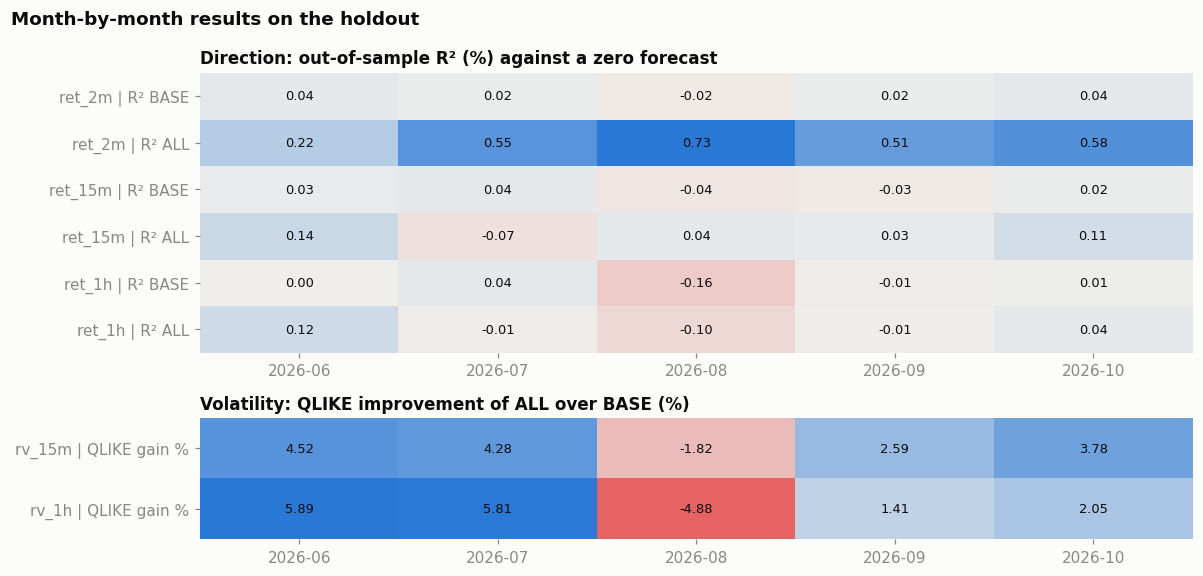

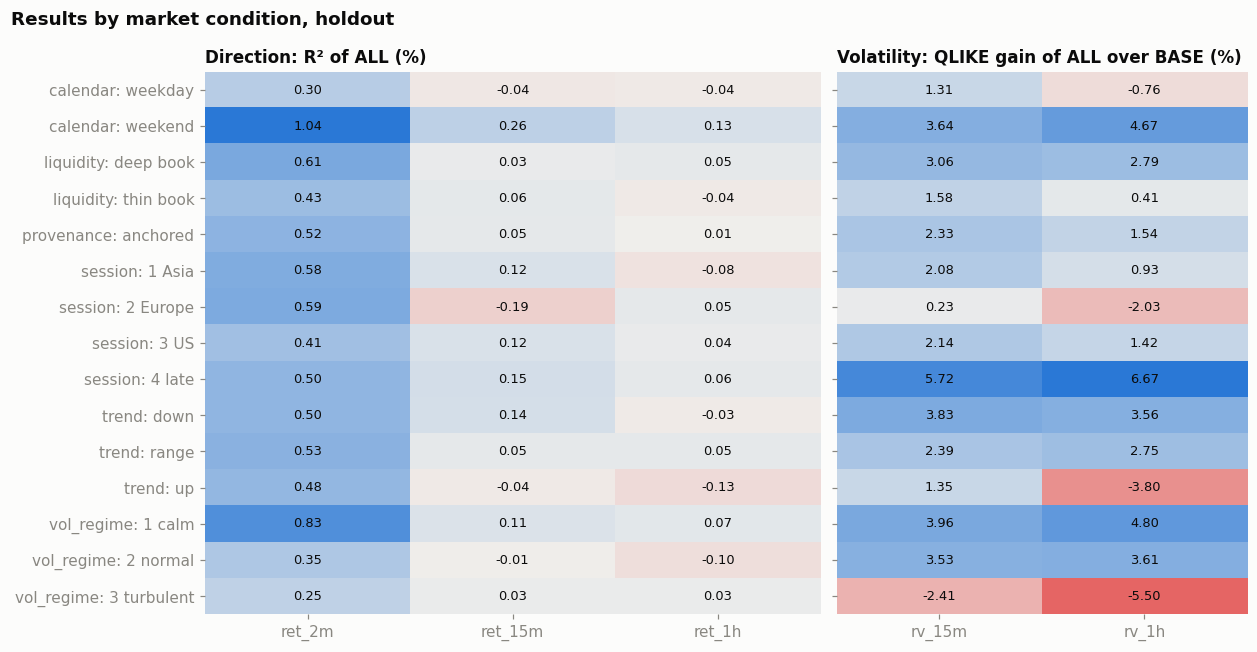

target                        ret_2m         ret_15m         ret_1h         rv_15m           rv_1h
condition  level                                                                                  
calendar   weekday      [0.19, 0.39]   [-0.13, 0.04]  [-0.12, 0.05]  [-0.87, 3.36]   [-4.57, 2.93]
           weekend      [0.82, 1.25]    [0.13, 0.41]  [-0.05, 0.31]   [1.60, 5.08]    [0.87, 7.41]
liquidity  deep book    [0.46, 0.76]   [-0.06, 0.12]  [-0.04, 0.15]   [1.92, 4.20]    [1.03, 4.72]
           thin book    [0.29, 0.57]   [-0.02, 0.15]  [-0.14, 0.07]  [-1.91, 4.26]   [-5.19, 5.21]
provenance anchored     [0.39, 0.64]   [-0.02, 0.12]  [-0.07, 0.09]   [0.34, 3.93]   [-1.95, 4.48]
session    1 Asia       [0.40, 0.74]    [0.02, 0.22]  [-0.18, 0.02]  [-0.56, 4.47]   [-3.94, 6.08]
           2 Europe     [0.40, 0.77]  [-0.34, -0.06]  [-0.11, 0.23]  [-1.94, 2.03]   [-5.79, 1.05]
           3 US         [0.29, 0.54]    [0.03, 0.22]  [-0.11, 0.19]   [0.50, 3.65]   [-2.47, 4.98]
           4 late       [0.25, 0.74]   [-0.03, 0.33]  [-0.26, 0.34]   [2.69, 8.17]    [3.01, 9.60]
trend      down         [0.25, 0.72]   [-0.08, 0.32]  [-0.29, 0.19]   [1.14, 6.18]   [-1.39, 8.00]
           range        [0.40, 0.68]   [-0.02, 0.13]  [-0.04, 0.14]   [1.16, 3.40]    [0.64, 4.74]
           up           [0.20, 0.75]   [-0.24, 0.19]  [-0.32, 0.09]  [-4.00, 6.33]  [-12.30, 5.08]
vol_regime 1 calm       [0.65, 1.00]   [-0.03, 0.22]  [-0.08, 0.23]   [3.16, 4.85]    [2.70, 6.55]
           2 normal     [0.20, 0.49]   [-0.16, 0.11]  [-0.24, 0.04]   [2.49, 4.92]    [1.79, 5.34]
           3 turbulent  [0.11, 0.40]   [-0.13, 0.17]  [-0.12, 0.18]  [-8.30, 3.26]  [-13.93, 2.57]

In [41]:
MD_HOLD, MV_HOLD = monthly_table(P_HOLD)
monthly_plot(MD_HOLD, MV_HOLD, "Month-by-month results on the holdout")
CT_HOLD = condition_table(P_HOLD)
condition_plot(CT_HOLD, "Results by market condition, holdout")
CT_HOLD.assign(ci=lambda d: d.apply(lambda r: f"[{r.lo:.2f}, {r.hi:.2f}]", axis=1)).pivot(index=["condition", "level"], columns="target", values="ci")[list(HORIZONS)]

**Interpretation.**

* **The 2-minute signal persists everywhere.** It is positive in all 5 months (0.22% to 0.73%) and in every market condition, and every interval excludes zero. The weakest cells are again the most volatile: June 2026, the highest-volatility month, and the turbulent regime.
* **Provenance could not be tested here.** The holdout contains only anchored rows, so this does not add evidence on the rebuilt book. It does show that a model trained mostly on rebuilt data transfers to anchored data, and across the May 2026 cadence change, without losing the signal.
* **15 minutes and 1 hour:** mostly intervals around zero, with mixed signs. The Europe session at 15 minutes is negative, with an interval that excludes zero, which shows how noisy this horizon is.
* **Volatility (Ridge `ALL` over `BASE`):** positive in 4 of 5 months and negative in August, which contains a stress episode on 19–21 August. As in development, the point estimate is weakest in turbulent conditions (−2.4% and −5.5%, though both intervals include zero). **There is no sign that microstructure helps most when volatility forecasts matter most.**

### Placebo on the holdout, and the economics

In [42]:
# Placebo. The target comes from 7 days later, so the last week of October 2026 has no target and drops out.
y_placebo_h = {k: Y["z_" + k].shift(-SHIFT) for k in ["ret_2m", "ret_15m"]}
Pph, _ = run_walk_forward(CTX, HOLDOUT_FOLDS, ["ret_2m", "ret_15m"], configs=SMALL, lgb_configs=(), y_override=y_placebo_h, extra_purge=pd.Timedelta(days=7, minutes=13))
rows = {k: score_direction(aggregate(with_days(Pph[k])), "ridge_ALL", "ridge_BASE") for k in Pph}
display(pd.DataFrame(rows).T[["n", "r2_pct", "r2_lo", "r2_hi", "ic", "ic_t", "cw_t"]].astype(float).round(4))

ECON_HOLD = econ_table(P_HOLD)
ECON_HOLD[num] = ECON_HOLD[num].apply(pd.to_numeric).round(2)
# Pre-specified bar for "worth a real simulation", with a Bonferroni correction over the 24 rule variants.
crit = scipy.stats.norm.ppf(1 - 0.05 / len(ECON_HOLD))
ECON_HOLD["passes"] = (ECON_HOLD["net_7bps"] > 0) & (ECON_HOLD["t_gross"] > crit)
print(f"Critical t with Bonferroni over {len(ECON_HOLD)} variants: {crit:.2f}. Variants passing: {int(ECON_HOLD['passes'].sum())}")
ECON_HOLD

,n,r2_pct,r2_lo,r2_hi,ic,ic_t,cw_t
ret_2m,191917.0,-0.0008,-0.0022,0.0005,-0.0025,-0.9047,2.6606
ret_15m,191892.0,-0.0040,-0.0119,0.0033,-0.0051,-0.7765,1.6609


Critical t with Bonferroni over 24 variants: 2.87. Variants passing: 0


trades  trades_per_day  mean_forecast_bps  gross_bps  t_gross   hit months_gross_pos  net_4bps  net_7bps  net_10bps  passes
target  model     signal  delay                                                                                                                            
ret_2m  ridge_ALL top 10% 0 min  14729           98.19               1.18       0.70     9.52  0.54              5/5     -3.30     -6.30      -9.30   False
                          1 min  12291           81.94               1.16      -0.05    -0.54  0.49              2/5     -4.05     -7.05     -10.05   False
                  top 1%  0 min   1678           11.26               2.00       0.64     1.43  0.54              4/5     -3.36     -6.36      -9.36   False
                          1 min   1499           10.06               1.97      -0.18    -0.46  0.49              2/5     -4.18     -7.18     -10.18   False
        lgb_ALL   top 10% 0 min  16772          111.81               0.87       0.68     8.59  0.55              5/5     -3.32     -6.32      -9.32   False
                          1 min  14828           98.85               0.87      -0.07    -0.96  0.49              1/5     -4.07     -7.07     -10.07   False
                  top 1%  0 min   1855           12.45               1.23       0.92     3.74  0.56              5/5     -3.08     -6.08      -9.08   False
                          1 min   1733           11.63               1.22      -0.07    -0.34  0.50              2/5     -4.07     -7.07     -10.07   False
ret_15m ridge_ALL top 10% 0 min   4702           31.35               1.24       0.66     1.42  0.55              4/5     -3.34     -6.34      -9.34   False
                          1 min   4519           30.13               1.23       0.24     0.66  0.52              3/5     -3.76     -6.76      -9.76   False
                  top 1%  0 min    648            4.35               2.35       1.48     1.50  0.51              4/5     -2.52     -5.52      -8.52   False
                          1 min    640            4.30               2.36      -0.28    -0.26  0.49              3/5     -4.28     -7.28     -10.28   False
        lgb_ALL   top 10% 0 min   4973           33.15               0.70       0.16     0.52  0.52              3/5     -3.84     -6.84      -9.84   False
                          1 min   4793           31.95               0.70      -0.28    -0.88  0.50              1/5     -4.28     -7.28     -10.28   False
                  top 1%  0 min    744            4.99               1.07       0.96     1.24  0.53              3/5     -3.04     -6.04      -9.04   False
                          1 min    733            4.92               1.07       0.69     0.78  0.50              3/5     -3.31     -6.31      -9.31   False
ret_1h  ridge_ALL top 10% 0 min   1600           10.67               1.36      -0.05    -0.05  0.51              3/5     -4.05     -7.05     -10.05   False
                          1 min   1591           10.61               1.36      -0.50    -0.53  0.51              2/5     -4.50     -7.50     -10.50   False
                  top 1%  0 min    307            2.06               2.72      -1.02    -0.30  0.50              2/5     -5.02     -8.02     -11.02   False
                          1 min    304            2.04               2.74      -1.70    -0.53  0.52              2/5     -5.70     -8.70     -11.70   False
        lgb_ALL   top 10% 0 min    793            5.32               1.20       2.76     1.88  0.51              4/5     -1.24     -4.24      -7.24   False
                          1 min    778            5.22               1.20       3.27     2.09  0.51              4/5     -0.73     -3.73      -6.73   False
                  top 1%  0 min    111            0.74               1.82       1.27     0.24  0.49              2/5     -2.73     -5.73      -8.73   False
                          1 min    108            0.72               1.82       0.37     0.07  0.44              2/5     -3.63     -

**Interpretation.**

* **No variant passes.** None of the 24 meets the frozen criterion, so H-ECON is rejected as expected.
* **2 minutes:** the zero-latency gross edge is 0.6 to 0.9 bps, with t-statistics as high as 9.5, so the effect is unmistakably real. Net results are still between about −3 and −9 bps per trade. **With a one-minute delay, the gross edge is zero or negative.**
* **15 minutes:** at most about 1.5 bps gross.
* **1 hour:** Ridge is at or below zero. LightGBM's top-10% rule shows about 3 bps gross, examined below. It does not cover even the cheapest cost assumption.
* **Placebo:** R² and IC are flat, as they should be (IC t-statistics of −0.9 and −0.8). The Clark–West value of 2.66 at 2 minutes is not what a placebo should show, and it is examined next.

### Post-hoc diagnostics `POST-HOC`

The cells below were **added after seeing the holdout results**, to help interpret them. They cannot change the frozen verdicts above, and they should be read as explanation rather than confirmation. Three things needed checking:

1. The holdout placebo has a Clark–West t of 2.66, although a placebo should not reject.
2. D5 passed at 15 minutes, against my expectation. Is it a new finding, or the same imbalance effect?
3. The LightGBM 1-hour rule has a gross edge of about 3 bps in both periods, even though the model shows no overall forecast skill.

**Check 1.** The Clark–West adjusted loss splits exactly into two parts: a signal term `2y(f1 − f0)` and a term `2f0(f0 − f1)` that does not involve the target at all. The second is zero only if the larger model keeps the baseline's forecast unchanged and adds to it. Ridge chooses a separate penalty for each model, so that need not hold.

In [43]:
def cw_parts(P, m, b_):
    P_ = aggregate(P)
    y, f1, f0 = (P_[c].to_numpy(np.float64) for c in ("y", m, b_))
    day = P_["day"].to_numpy()
    daily = lambda v: pd.Series(v).groupby(day).mean().to_numpy()
    signal, target_free = 2 * y * (f1 - f0), 2 * f0 * (f0 - f1)
    return dict(clark_west_t=hac_t(daily(signal + target_free))[1], signal_term_t=hac_t(daily(signal))[1], plain_loss_t=hac_t(daily((y - f0) ** 2 - (y - f1) ** 2))[1],
                signal_term_mean=signal.mean(), target_free_term_mean=target_free.mean())

items = {"Placebo ret_2m": (with_days(Pph["ret_2m"]), "ridge_ALL", "ridge_BASE"), "Placebo ret_15m": (with_days(Pph["ret_15m"]), "ridge_ALL", "ridge_BASE")}
items.update({tid: (P_HOLD[k], m, b_) for tid, k, m, b_ in TESTS if tid.startswith("D")})
CW_PARTS = pd.DataFrame({k: cw_parts(*v) for k, v in items.items()}).T
CW_PARTS.round(4)

,clark_west_t,signal_term_t,plain_loss_t,signal_term_mean,target_free_term_mean
Placebo ret_2m,2.6606,2.1274,2.4872,0.0000,0.0000
Placebo ret_15m,1.6609,0.7509,1.3190,0.0001,0.0002
D1,15.9676,16.1461,7.6738,0.0105,-0.0001
D2,4.8727,5.5461,1.7507,0.0013,-0.0001
D3,2.3429,2.3989,1.5349,0.0006,-0.0000
D4,9.8833,9.6173,7.0952,0.0130,-0.0001
D5,4.2286,3.1962,2.5887,0.0010,0.0003
D6,-1.0477,-0.8349,-1.5932,-0.0005,-0.0001


**My proposed explanation was wrong.** The target-free term is essentially zero in every row, so it does not explain the placebo. The rejection comes from the signal term itself (t = 2.13), and it also shows up in the plain loss difference (t = 2.49).

That leaves two possibilities: this one placebo was unlucky, or t-statistics in this setup run larger than their nominal distribution. A single placebo cannot separate these, and the distinction matters because D5's plain-loss t of 2.59 is about the same size as the placebo's. So the next cell measures the null distribution directly, using many placebos.

In [44]:
def placebo_null(n_shifts=12, targets=("ret_2m", "ret_15m")):
    # Many placebos instead of one. Each pairs features with targets from a random 3 to 25 days away, in either time direction,
    # so any link is broken while the data's autocorrelation and the whole Ridge procedure are preserved.
    rng = np.random.default_rng(SEED)
    shifts = rng.integers(3 * 1440, 25 * 1440, n_shifts) * np.where(np.arange(n_shifts) % 2 == 0, 1, -1)
    sets_k = {k: {m: col_index(CTX, CONFIGS[m], k) for m in ("BASE", "ALL")} for k in targets}
    acc = {(int(s_), k): [] for s_ in shifts for k in targets}
    tn = CTX["tn"]
    for fold in HOLDOUT_FOLDS:
        start = pd.Timestamp(f"{fold}-01", tz=UTC); hi = int(np.searchsorted(tn, (start + pd.offsets.MonthBegin(1)).value))
        train_rows = CTX["elig"][:hi] & (tn[:hi] >= DEV_START.value) & (tn[:hi] < (start - CTX["purge"]).value) & ~CTX["crash"][:hi]
        Z = scaler_apply(CTX["X"][:hi], scaler_fit(CTX["X"][:hi][train_rows]))
        for k in targets:
            for s_ in shifts:
                y = Y["z_" + k].shift(-int(s_)).to_numpy(np.float64)[:hi]
                fin = np.isfinite(y)
                tr, te = np.flatnonzero(train_rows & fin), np.flatnonzero(CTX["elig"][:hi] & fin & (tn[:hi] >= start.value))
                p_, _ = ridge_suite(Z, y, tr, te, sets_k[k], PURGE_BARS, False)
                acc[(int(s_), k)].append(pd.DataFrame({"row": te, "y": y[te], "ridge_BASE": p_["BASE"], "ridge_ALL": p_["ALL"]}))
        del Z
    return pd.DataFrame([dict(shift_days=round(s_ / 1440, 1), target=k, **cw_parts(with_days(pd.concat(v, ignore_index=True)), "ridge_ALL", "ridge_BASE")) for (s_, k), v in acc.items()])

NULL = placebo_null()
stats = lambda g: pd.Series({"placebos": len(g), "mean_cw_t": g.clark_west_t.mean(), "sd_cw_t": g.clark_west_t.std(), "max_cw_t": g.clark_west_t.max(), "share_cw_t_above_2": (g.clark_west_t > 2).mean(),
                             "mean_plain_t": g.plain_loss_t.mean(), "sd_plain_t": g.plain_loss_t.std(), "max_plain_t": g.plain_loss_t.max()})
display(NULL.groupby("target").apply(stats, include_groups=False).round(2))
print("Observed Ridge results for comparison (D1 = ret_2m, D2 = ret_15m):")
CW_PARTS.loc[["D1", "D2"], ["clark_west_t", "plain_loss_t"]].round(2)

,placebos,mean_cw_t,sd_cw_t,max_cw_t,share_cw_t_above_2,mean_plain_t,sd_plain_t,max_plain_t
target,,,,,,,,
ret_15m,12.0,0.68,1.00,1.81,0.00,0.11,1.10,1.38
ret_2m,12.0,0.83,1.03,2.45,0.08,0.27,0.99,1.96


Observed Ridge results for comparison (D1 = ret_2m, D2 = ret_15m):


,clark_west_t,plain_loss_t
D1,15.97,7.67
D2,4.87,1.75


**What the null distribution shows.** Across 24 placebos, the spread of these t-statistics is about right, with a standard deviation near 1.0. Clark–West, however, is **centred near +0.7 to +0.8 rather than zero**, so it leans towards rejection in this setup. The plain loss comparison is close to zero on average. The holdout placebo's 2.66 therefore looks like an upper-tail draw from a shifted distribution, not a broken pipeline: the highest of these 24 is 2.45.

With only 12 draws per target this is a rough calibration, but it changes how some results should be read:

| Test | Clark–West t | Plain loss t | Reading |
|---|---|---|---|
| D1, D4 (2 minutes) | 16.0, 9.9 | 7.7, 7.1 | Far outside the placebo range on both measures. Unaffected. |
| D2 (Ridge, 15 minutes) | 4.9 | 1.75 | Clark–West is outside the placebo range, but the actual loss improvement is inside it. |
| D3 (Ridge, 1 hour) | 2.3 | 1.5 | **Inside the placebo range, so not evidence of anything.** Its unadjusted p of 0.0096 is misleading. |
| D5 (LightGBM, 15 minutes) | 4.2 | 2.6 | Above the Ridge placebo range, but no LightGBM placebo distribution was run. |

**Takeaway.** D5 did pass the frozen rule, and that verdict stands as recorded. But nominal Clark–West p-values are too optimistic here, so t-statistics in the 2 to 3 range should not be trusted, and future work should use a placebo-calibrated threshold. The 2-minute conclusions do not depend on this at all.

**Check 2.** If the imbalance move is permanent, as section 6 suggests, the same fixed move should appear at longer horizons. It would simply be buried under more variance. So I compare the raw `qi_1` slope across horizons, in both periods.

In [45]:
holdout_rows = ELIGIBLE & IN_HOLDOUT & MONTH.isin(HOLDOUT_FOLDS)
rows = []
for k in DIR_TARGETS:
    for lab, mask in [("development", dev_test_rows), ("holdout", holdout_rows)]:
        d_ = pd.DataFrame({"y": Y[k] * 1e4, "q": bars["qi_1"]})[mask].dropna()
        qc = d_["q"] - d_["q"].mean()
        day_ = d_.index.floor("D")
        qy, qq = (qc * d_["y"]).groupby(day_).sum().to_numpy(), (qc ** 2).groupby(day_).sum().to_numpy()
        lo, hi = block_boot(qy, qq)
        rows.append(dict(target=k, period=lab, slope_bps=qy.sum() / qq.sum(), ci_lo=lo, ci_hi=hi, corr=d_["q"].corr(d_["y"]), implied_r2_pct=100 * d_["q"].corr(d_["y"]) ** 2))
QI_HORIZON = pd.DataFrame(rows).set_index(["target", "period"])
display(QI_HORIZON.round(4))
k = "ret_15m"; P_ = aggregate(P_HOLD[k])
print(f"Holdout, {k}: correlation of the LightGBM ALL forecast with qi_1: {pd.Series(P_['lgb_ALL'].to_numpy()).corr(pd.Series(bars['qi_1'].to_numpy()[P_['row'].to_numpy()])):.3f}")

slope_bps   ci_lo   ci_hi    corr  implied_r2_pct
target  period                                                        
ret_2m  development     0.7022  0.6389  0.7661  0.0470          0.2209
        holdout         0.6659  0.6137  0.7203  0.0509          0.2595
ret_15m development     0.6142  0.4827  0.7414  0.0151          0.0227
        holdout         0.6271  0.4527  0.8115  0.0179          0.0320
ret_1h  development     0.7898  0.4723  1.0869  0.0098          0.0095
        holdout         0.6588  0.3210  0.9888  0.0094          0.0088

Holdout, ret_15m: correlation of the LightGBM ALL forecast with qi_1: 0.451


**Interpretation.** The slope barely changes with horizon: about 0.6 to 0.8 bps at 2 minutes, 15 minutes, and 1 hour, in both periods, with intervals that widen as noise grows. This has two implications:

* **The imbalance move is persistent.** It does not reverse within an hour, which suggests it reflects information reaching the price and not temporary pressure.
* **D5 is not a separate discovery.** On the holdout, imbalance alone implies a 15-minute R² of about 0.03%, roughly half of LightGBM's 0.06%, and that forecast has a 0.45 correlation with `qi_1`. Most of what passed at 15 minutes appears to be the same 2-minute effect, viewed through 15 minutes of noise. It has not grown, so a longer holding period does not make it more tradable.

**Check 3.** A positive gross edge can come from market drift, from a few large trades, or from one episode. I look at how the LightGBM 1-hour top-10% rule splits by side, how much a few trades contribute, and what happens month by month.

In [46]:
def rule_anatomy(Pd, label, k="ret_1h", m="lgb_ALL", q=0.90):
    T_ = simulate(Pd[k], k, m, q, 0)
    P_ = aggregate(Pd[k]); fc = pd.Series(P_[m].to_numpy(), index=P_["row"].to_numpy())
    side = np.sign(fc.reindex(T_["row"]).to_numpy())
    g = T_["gross_bps"]; lo_, hi_ = g.quantile([.01, .99])
    span = Y.loc[t_idx[P_["row"].to_numpy()], k].mean() * 1e4
    monthly = g.groupby(t_idx[T_["row"].to_numpy()].strftime("%Y-%m")).mean().round(1)
    return dict(period=label, trades=len(T_), share_long=(side > 0).mean(), gross_all=g.mean(), gross_long=g[side > 0].mean(), gross_short=g[side < 0].mean(),
                gross_trimmed_1pct=g[(g > lo_) & (g < hi_)].mean(), median_gross=g.median(), market_drift_bps_per_hour=span, by_month=monthly.to_dict())
ANATOMY = pd.DataFrame([rule_anatomy(P_DEV, "development"), rule_anatomy(P_HOLD, "holdout")]).set_index("period")
pd.set_option("display.max_colwidth", 160)
ANATOMY.round(2).T

period,development,holdout
trades,1162,793
share_long,0.32,0.41
gross_all,3.64,2.76
gross_long,2.17,6.03
gross_short,4.32,0.52
gross_trimmed_1pct,3.08,2.52
median_gross,1.91,1.02
market_drift_bps_per_hour,-0.64,0.11
by_month,"{'2025-10': -0.4, '2025-11': 4.4, '2025-12': 3.5, '2026-01': 3.2, '2026-02': 1.1, '2026-03': 11.3, '2026-04': -3.2, '2026-05': 3.3}","{'2026-06': 12.2, '2026-07': -2.3, '2026-08': 2.8, '2026-09': 0.6, '2026-10': 2.4}"


**Interpretation.** This is not market drift, which was only −0.64 and +0.11 bps per hour. It is also not a stable edge:

* **The side flips.** In development the edge came mostly from shorts (4.3 bps against 2.2). In the holdout it came from longs (6.0 bps against 0.5).
* **One month dominates each period:** March 2026 at +11.3 bps, and June 2026 at +12.2 bps. The other four holdout months average about 1 bps.
* **The typical trade is small,** with a median of 1 to 2 bps.

This looks more like exposure to a few large moves in volatile episodes than a repeatable signal. Combined with the lack of forecast skill at 1 hour, I treat it as noise, and it stays below cost in any case.

## 16. Final assessment

### What the evidence supports

**Do these features contain useful out-of-sample information?**

* **About volatility: yes, a lot, but most of it is in price, volume, and time of day.** R² on log realized variance is 76% to 82%.
* **About price direction: only a little, and only very briefly.** The information is real and repeatable, but it explains under 1% of 2-minute variance and essentially nothing at longer horizons.

**Do microstructure features improve on a price-and-volume baseline?**

* **For direction at 2 minutes: yes, clearly.** Almost all of that comes from one idea, top-of-book imbalance.
* **For volatility: no, once the baseline is strong.** The gain against a linear baseline is real but disappears against a nonlinear one. This is the finding most dependent on methodology: **a weaker baseline would have produced the opposite conclusion.**
* **Basis, funding, open interest, and liquidations added nothing reliable at these horizons.**

**Is any of it profitable?** Not as tested. Statistical and economic significance separated completely: the best signal has t-statistics around 10 and still loses 3 to 9 bps per trade.

### Most promising findings

**1. A stable law for top-of-book imbalance.** A fully imbalanced book is followed by a move of about 0.67 bps.

* **Evidence:** the size was predicted in advance and confirmed. It stays between 0.55 and 0.84 bps in all 13 test months, and it is flat across a nearly fourfold range of volatility. It holds on both rebuilt and anchored book data, and across the May 2026 feed change.
* **Character:** the move builds over about 30 seconds and does not reverse within an hour, which suggests information and not temporary pressure.
* **Limitation:** it is much too small to pay for a round trip, and about two-thirds of it arrives within 5 seconds. Its more realistic use may be deciding **how and when to place orders that would be placed anyway**, rather than as a standalone signal. That is a hypothesis, and it is not tested here.

**2. A nonlinear price-and-volume volatility model.** It beat Ridge with all features by 8.7% and 18.9% in QLIKE, in 5 of 5 holdout months. This is the largest practical improvement in the notebook, and it needs no order-book data. Its likely uses are risk sizing and execution scheduling.

**3. A narrow linear result for book flow.** Ridge `+BOOK_FLOW` improved volatility forecasts in all 5 holdout months, as it mostly had in development. It adds nothing to the nonlinear model, so it is low priority unless a simple linear model is required.

### What remains uncertain

* **Crash behaviour is unknown.** The book and strict windows are missing for the worst hours, and the last forecast before the crash was about 31 times too low. One event also cannot support statistical conclusions. The data cannot say whether these features help in a crash.
* **Tradability below one minute is unmeasured.** The evidence covers 0 and 60 seconds of delay for models, and only raw imbalance on 45 days inside the minute.
* **Costs are assumptions.** Fills, queue position, and market impact are not modelled.
* **The scope is narrow.** One venue, one instrument, 16 months of mostly falling prices, and a 5-month holdout that was calmer than development.
* **About 100 of the 643 features were tested,** chosen by judgement. Horizons stop at 1 hour, which is too short a test for funding and open interest. Those families are untested at their natural horizons, and this notebook does not show they are useless.
* **LightGBM was not tuned.** That was deliberate, and it cuts both ways: tuning could help either the baseline or the full model.
* **Results describe healthy-data periods.** The eligible sample excludes 6% to 12% of holdout rows and up to 35% in April 2026, and excluded rows are more active.
* **Book exactness before April 2026 is inferred, not measured.** The stability across provenance is reassuring but is not direct proof.
* **Nominal test statistics can mislead.** Clark–West leaned positive in the placebo distribution, which was itself small (12 draws per target, Ridge only).

### Process record

* **Holdout use.** The holdout cells first ran on 2026-11-06 at 10:19 UTC, after the specification was frozen, and that specification did not change afterwards. The notebook was then re-executed three more times: twice to add the `POST-HOC` cells, and once as a final top-to-bottom run of this exact file, after removing unused variables and moving a chart label. The outputs of all frozen cells matched across all four runs.
* **Before freezing,** I saw feature coverage and daily volatility for the holdout months, but no relationship between features and future targets. The code path was also dry-run on development folds, to avoid any bug fix after seeing holdout results.
* **Where my expectations failed.** I expected D5 to fail and it passed. My first explanation of the placebo rejection was wrong. A within-day IC produced a false finding before it was caught. All three are documented above.
* **The holdout is now used.** June to October 2026 can no longer serve as untouched data. Any new hypothesis prompted by this notebook needs data after 2026-10-31 for a confirmatory test.

### Recommended next steps

In priority order, starting with the cheapest and most decisive:

1. **Measure how much of the imbalance move survives realistic latency.** Use the 100 ms grid with delays from 50 ms to 5 s on all development days. This decides whether the effect can be captured at all.
2. **Test imbalance as an execution signal.** Does conditioning passive or aggressive orders on `qi_1` improve realized markouts? A sub-bp effect is far more plausible as a cost saving than as a profit source.
3. **Model imbalance in bps, not volatility units.** Section 10.3 shows the scaling is wrong for this signal, and it caused the negative February 2026 result.
4. **Find out why the nonlinear baseline wins,** which interactions it uses, and what it is worth in position sizing or risk targeting, not just in loss metrics.
5. **Test funding, open interest, and basis at horizons of 4 to 24 hours,** where they could plausibly matter.
6. **Improve stress coverage.** Build tolerant versions of key features and collect more stress episodes, since the current pipeline cannot observe the moments that matter most.
7. **Replicate on another liquid perpetual,** to separate a market-structure effect from something specific to BTCUSDT on Binance.
8. **Use a placebo-calibrated threshold** for all nested comparisons in future notebooks.

In [47]:
# Integrity check: the source dataset is unchanged, and the total runtime.
assert dataset_fingerprint() == FINGERPRINT_START, "Source dataset changed during this run."
print(f"Source dataset unchanged: {FINGERPRINT_START[0]} files, {FINGERPRINT_START[1] / 1e9:.1f} GB.")
import resource
print(f"Notebook runtime: {(time.time() - T0) / 60:.1f} minutes. Peak kernel memory: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB.")

Source dataset unchanged: 151 files, 35.8 GB.
Notebook runtime: 31.2 minutes. Peak kernel memory: 9.6 GB.
